# Homogeneous transmission Model Simulation Notebook

This notebook contains the core simulation, measurement, and plotting workflow used in the paper.

Required packages: `numpy`, `pandas`, `matplotlib`, `networkx`, `scipy`, and `python-louvain` (`pip install python-louvain`).


In [1]:
import numpy as np
import networkx as nx
import random
import pandas as pd
from collections import defaultdict, Counter
import community as community_louvain  # pip install python-louvain
import os
import matplotlib.pyplot as plt
from math import ceil
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.signal import welch, detrend, get_window
import random
from scipy.stats import linregress
from scipy.ndimage import gaussian_filter1d
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import seaborn as sns

plt.rcParams['font.size'] = 12 
rng = np.random.default_rng(42)


In [19]:
# -----------------------------
# Parameters
# -----------------------------
V = 200
d = 10
E = V*d/2

# for avalanche
max_avalanches = 10000 
record_every = 100     

update_every = 5
p_base = 0.1
# Preserve the initial scan reference: later parameter loops can overwrite p_base.
htm_p_reference = float(p_base)

noise_level=0

mode = 'no' #ar, no, random, random-dp
network ='regular' # random, sw, regular, modular

## Helper Functions


In [3]:
def one_avalanche(G, p_base, rng, track_edges=True, seed_node=None,
                  return_response=False, max_steps=None):
    # Defaults preserve the original random-seed simulation and return tuple.
    if max_steps is not None and (
        not np.isfinite(max_steps) or max_steps < 1 or int(max_steps) != max_steps
    ):
        raise ValueError('max_steps must be None or a positive integer.')
    if seed_node is None:
        seed_node = rng.integers(0, G.number_of_nodes())
    elif seed_node not in G:
        raise ValueError('Stimulated seed node is not in the graph.')
    counts_all = Counter() if return_response else None
    counts_post_seed = Counter() if return_response else None
    censored = False
    active = {seed_node}
    size = 0
    duration = 0
    series = []

    used_edges = set() if track_edges else None
    # for calculating the successful transmission
    used_edges_events = {} if track_edges else None  # dict edge->count

    while active:
        if return_response:
            counts_all.update(active)
            if duration > 0:  # t=0 contains only the directly stimulated seed
                counts_post_seed.update(active)
        series.append(len(active))
        size += len(active)
        duration += 1

        next_active = set()
        for u in active:
            xu = G.nodes[u]["activation"]
            for v in G.neighbors(u):
                xv = G.nodes[v]["activation"]
                p = p_base
                if rng.random() < p:
                    next_active.add(v)

                    if track_edges:
                        e = (u, v) if u < v else (v, u)
                        used_edges.add(e)
                        used_edges_events[e] = used_edges_events.get(e, 0) + 1

        active = next_active
        if max_steps is not None and duration >= max_steps and active:
            censored = True
            break

    if track_edges:
        result = (size, duration, series, used_edges, used_edges_events)
    else:
        result = (size, duration, series)
    if return_response:
        result += (dict(seed_node=seed_node, counts_all=counts_all,
                        counts_post_seed=counts_post_seed, censored=censored),)
    return result

In [4]:
def generate_modular_network(V, d, n_modules, p_in=0.15, p_out=0.01, seed=None):
    
    rng = np.random.default_rng(seed)
    
    # --- 1. Assign nodes to modules ---
    sizes = [V // n_modules] * n_modules
    for i in range(V % n_modules):
        sizes[i] += 1
    modules = {}
    node_index = 0
    for m, size in enumerate(sizes):
        for _ in range(size):
            modules[node_index] = m
            node_index += 1
    
    # --- 2. Create empty graph ---
    G = nx.Graph()
    G.add_nodes_from(range(V))
    
    # --- 3. Add edges ---
    # Compute probabilities dynamically based on d if desired
    if p_in is None or p_out is None:
        # approximate: E = V*d/2, split by ratio r=p_in/p_out
        p_out = d / (V * (1 + (n_modules - 1)))
        p_in = p_out * n_modules  # make intra-module higher
    
    for i in range(V):
        for j in range(i+1, V):
            same_module = (modules[i] == modules[j])
            p = p_in if same_module else p_out
            if rng.random() < p:
                G.add_edge(i, j)
    
    # --- 4. Compute modularity using Louvain ---
    partition = community_louvain.best_partition(G)
    Q = community_louvain.modularity(partition, G)
    
    # # --- 5. Optional plot ---
    # pos = nx.spring_layout(G)
    # cmap = plt.cm.get_cmap('tab10', n_modules)
    # colors = [cmap(modules[i]) for i in G.nodes()]
    # plt.figure(figsize=(6,6))
    # nx.draw_networkx(G, pos=pos, node_color=colors, with_labels=False, node_size=50)
    # plt.title(f"Modular network (V={V}, Q={Q:.3f})")
    # plt.axis('off')
    # plt.show()
    
    return G, Q, modules

In [5]:
def show_network(G, title, cmap):
    # get node activation values
    node_values = [G.nodes[node]['activation'] for node in G.nodes]

    norm = mcolors.Normalize(vmin=0, vmax=1)
    # norm = mcolors.Normalize(vmin=min(node_values), vmax=max(node_values))

    node_colors = [cmap(norm(value)) for value in node_values]

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array(node_values)

    pos = nx.spring_layout(G,seed=1)
    options = {
        "node_color": node_colors,
        "node_size": 100,
        "edge_color": "grey",
        "linewidths": 0,
        "width": 0.5,
    }
    nx.draw(G, pos, **options)
    # nx.draw_networkx(G, with_labels=True, node_color=node_colors, cmap=cmap, node_size=500)
    # nx.draw_circular(G, with_labels=True, node_color=node_colors, cmap=cmap, node_size=500)
    plt.title(f'{title}')
    plt.colorbar(sm, label="activation")
    plt.show() 

In [6]:
def generate_network(network,V,d,n_modules,p,seed=rng, show=False):
    if network == 'random':
        G = nx.gnm_random_graph(V, E,seed)
    elif network == 'regular':
        G = nx.random_regular_graph(d, V)
    elif network == 'sw':
        G = nx.watts_strogatz_graph(V, d, p)
    elif network =='modular':
        G, Q, modules = generate_modular_network(V, d, n_modules,p_in=0.15, p_out=0.01, seed=rng)
    else:
        raise ValueError("Unknown network: 'random' | 'regular' | 'sw'| 'modular'")
    
    for n in G.nodes():
        G.nodes[n]["activation"] = rng.uniform(0, 1.0)
    if show == True:
        show_network(G, 'Initial Network', cm.plasma)
    return G

In [7]:
def update_activation_null(G,noise_level):
    for n in G.nodes():
        # uncoupled logistic map
        G.nodes[n]["activation"]=rng.uniform(0, 1.0)

def rewiring_no(G):
    return

def rewiring_random_degree_preserving(G, trials=1):
    edges = list(G.edges())
    if len(edges) < 2:
        return
    for _ in range(trials):
        (a, c) = random.choice(edges)
        (b, d) = random.choice(edges)
        # avoid self-loop
        if len({a, b, c, d}) < 4:
            continue
        # change (a,d) and (b,c)
        if G.has_edge(a, d) or G.has_edge(b, c):
            continue
        # do exchange
        G.remove_edge(a, c)
        G.remove_edge(b, d)
        G.add_edge(a, d)
        G.add_edge(b, c)
        edges = list(G.edges())

def rewiring_random(G):
    a = random.choice(list(G.nodes()))
    candidates = [u for u in G.nodes() if u != a]
    if not candidates:
        return
    b = random.choice(candidates)
    if not G.has_edge(a, b):
        G.add_edge(a, b)
        nbrs = list(G.neighbors(a))
        if len(nbrs) > 1:
            c_cands = [u for u in nbrs if u != b] or [b]
            c = random.choice(c_cands)
            if c != b and G.has_edge(a, c):
                G.remove_edge(a, c)

def rewiring_ar(G):
    a = random.choice(list(G.nodes()))
    act_a = G.nodes[a]["activation"]
    b = min((u for u in G.nodes() if u != a),
            key=lambda u: abs(G.nodes[u]["activation"] - act_a))
    # print(f'step1: {a}')
    if not G.has_edge(a, b):
        # print(f'step2: {b}')
        G.add_edge(a, b)
        nbrs = list(G.neighbors(a))
        c = max(nbrs, key=lambda u: abs(G.nodes[u]["activation"] - act_a))
        G.remove_edge(a, c)
        # if len(nbrs) > 1:
        #     c = max(nbrs, key=lambda u: abs(G.nodes[u]["activation"] - act_a))
        #     if c != b and G.has_edge(a, c):
        #         G.remove_edge(a, c)
    return

In [8]:
# -----------------------------
# Network measures
# -----------------------------
def spectral_radius(G):
    A = nx.to_numpy_array(G, dtype=float)
    if A.size == 0:
        return np.nan
    vals = np.linalg.eigvals(A)
    return float(np.max(np.real(vals)))


def compute_network_measures(G):
    """Compute graph-level summary statistics on the current network."""
    m = {}
    comps = list(nx.connected_components(G))
    m["n_components"] = len(comps)
    gcc = G.subgraph(max(comps, key=len)).copy() if comps else G
    m["gcc_size"] = gcc.number_of_nodes()
    m["gcc_frac"] = m["gcc_size"] / G.number_of_nodes() if G.number_of_nodes() > 0 else np.nan

    # Basic path-length metrics are evaluated on the giant connected component.
    if gcc.number_of_nodes() >= 2 and nx.is_connected(gcc):
        m["avg_path_length"] = nx.average_shortest_path_length(gcc)
        m["diameter"] = nx.diameter(gcc)
    else:
        m["avg_path_length"] = np.nan
        m["diameter"] = np.nan

    m["efficiency"] = nx.global_efficiency(G)
    m["clustering"] = nx.average_clustering(G)
    m["assortativity"] = nx.degree_assortativity_coefficient(G)

    rc = nx.rich_club_coefficient(G, normalized=False)
    m["rich_club_coeff"] = float(np.mean(list(rc.values()))) if rc else np.nan

    bc = nx.betweenness_centrality(G)
    m["betweenness"] = float(np.mean(list(bc.values()))) if bc else np.nan

    if G.number_of_edges() > 0 and G.number_of_nodes() > 0:
        part = community_louvain.best_partition(G)
        m["modularity"] = community_louvain.modularity(part, G)
    else:
        part = {n: 0 for n in G.nodes()}
        m["modularity"] = np.nan

    E = G.number_of_edges()
    if E > 0:
        inter_edges = sum(1 for u, v in G.edges() if part[u] != part[v])
        intra_edges = E - inter_edges
        m["inter_edge_frac"] = inter_edges / E
        m["intra_edge_frac"] = intra_edges / E
    else:
        m["inter_edge_frac"] = np.nan
        m["intra_edge_frac"] = np.nan

    # Participation coefficient: how broadly each node connects across modules.
    deg = dict(G.degree())
    P_vals = []
    for i in G.nodes():
        k_i = deg[i]
        if k_i == 0:
            P_vals.append(np.nan)
            continue

        neigh_modules = Counter(part[j] for j in G.neighbors(i))
        sum_sq = 0.0
        for k_is in neigh_modules.values():
            frac = k_is / k_i
            sum_sq += frac ** 2
        P_vals.append(1.0 - sum_sq)

    P_arr = np.array(P_vals, dtype=float)
    if np.all(np.isnan(P_arr)):
        m["participation_mean"] = np.nan
        m["participation_std"] = np.nan
    else:
        m["participation_mean"] = float(np.nanmean(P_arr))
        m["participation_std"] = float(np.nanstd(P_arr))

    # Within-module degree z-score.
    module_nodes = defaultdict(list)
    for node, comm in part.items():
        module_nodes[comm].append(node)

    z_all = []
    for comm, nodes in module_nodes.items():
        k_in = []
        for n in nodes:
            kin = sum(1 for nbr in G.neighbors(n) if part[nbr] == comm)
            k_in.append(kin)

        k_in = np.array(k_in, dtype=float)
        if len(k_in) <= 1 or np.allclose(np.std(k_in), 0.0):
            z = np.zeros_like(k_in)
        else:
            z = (k_in - k_in.mean()) / k_in.std()
        z_all.extend(z.tolist())

    if z_all:
        z_arr = np.array(z_all, dtype=float)
        m["wmdeg_z_mean"] = float(np.mean(z_arr))
        m["wmdeg_z_std"] = float(np.std(z_arr))
    else:
        m["wmdeg_z_mean"] = np.nan
        m["wmdeg_z_std"] = np.nan

    if E > 0:
        ebc = nx.edge_betweenness_centrality(G)
        eb_vals = np.array(list(ebc.values()), dtype=float)
        m["edge_bw_mean"] = float(eb_vals.mean())
        m["edge_bw_max"] = float(eb_vals.max())
        m["edge_bw_std"] = float(eb_vals.std())
    else:
        m["edge_bw_mean"] = np.nan
        m["edge_bw_max"] = np.nan
        m["edge_bw_std"] = np.nan

    lam1 = spectral_radius(G)
    m["spectral_radius"] = lam1

    try:
        m["crit_gap_signed"] = p_base * lam1 - 1.0
        m["crit_gap_abs"] = abs(m["crit_gap_signed"])
    except NameError:
        m["crit_gap_signed"] = np.nan
        m["crit_gap_abs"] = np.nan

    if G.number_of_nodes() >= 2:
        L = nx.laplacian_matrix(G).astype(float).todense()
        evals = np.linalg.eigvalsh(L)
        m["algebraic_connectivity"] = float(evals[1]) if len(evals) >= 2 else 0.0
    else:
        m["algebraic_connectivity"] = np.nan

    return m


In [9]:
def propagation_spectrum(G, p_base):
    """HTM transmission spectrum: M=p_base*A, with no similarity or local-p term."""
    nodes = list(G.nodes())
    if not nodes:
        raise ValueError('Cannot compute a propagation spectrum for an empty graph.')
    if not np.isfinite(p_base) or not 0 <= p_base <= 1:
        raise ValueError('p_base must lie in [0,1].')
    A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
    p_values = np.full(len(nodes), float(p_base))
    activations = np.asarray([G.nodes[node].get('activation', np.nan) for node in nodes], dtype=float)
    P = np.diag(p_values)
    M_base = A @ P
    M = M_base.copy()
    spectrumA = np.linalg.eigvals(A)
    spectrumM = np.linalg.eigvals(M)
    rho_A = float(np.max(np.abs(spectrumA)))
    rho = float(np.max(np.abs(spectrumM)))
    return dict(nodes=nodes, A=A, p_values=p_values, activations=activations,
                P=P, M_base=M_base, M=M, spectrumA=spectrumA,
                spectrumM=spectrumM, rho_A=rho_A, rho_base=rho, rho=rho)


In [10]:
def _dfa_series(x):
    """Validate without sorting, removing samples, or changing the time axis."""
    if np.iscomplexobj(x):
        raise ValueError("DFA controls require a real-valued sequence.")
    x = np.asarray(x, dtype=float)
    if x.ndim != 1 or not np.all(np.isfinite(x)):
        raise ValueError("DFA requires a finite one-dimensional sequence.")
    return x


def dfa_fluctuations(x, min_window=4, max_frac=0.1, n_scales=25, min_segments=10):
    """First-order DFA with the same scales and segmentation as dfa_alpha.

    Segment-wise linear least-squares detrending is vectorized in bounded chunks.
    Incomplete end segments are omitted, matching the existing DFA convention.
    Return the full F(n) curve, log-log fit, and slope; insufficient or constant
    series have NaN slopes rather than an artificial finite exponent.
    """
    x = _dfa_series(x)
    for name, value, lower in (("min_window", min_window, 2),
                               ("n_scales", n_scales, 3),
                               ("min_segments", min_segments, 2)):
        if not np.isfinite(value) or value < lower or int(value) != value:
            raise ValueError(f"{name} must be an integer >= {lower}.")
    if not np.isfinite(max_frac) or not 0 < max_frac <= 1:
        raise ValueError("max_frac must lie in (0, 1].")
    result = dict(alpha=np.nan, intercept=np.nan, r2=np.nan,
                  scales=np.array([], dtype=int), fluctuations=np.array([], dtype=float),
                  n_samples=int(x.size))
    s_max = int(x.size * max_frac)
    if x.size < 100 or s_max <= min_window + 1 or np.ptp(x) == 0:
        return result
    profile = np.cumsum(x - x.mean())
    scales = np.unique(np.logspace(np.log10(min_window), np.log10(s_max), int(n_scales)).astype(int))
    used, fluctuations = [], []
    for s in scales:
        nseg = x.size // s
        if nseg < min_segments:
            continue
        segments = profile[:nseg * s].reshape(nseg, s)
        t = np.arange(s, dtype=float) - (s - 1) / 2
        t_squared = np.dot(t, t)
        sum_squared = 0.0
        chunk_segments = max(1, 1_000_000 // s)
        for start in range(0, nseg, chunk_segments):
            segment = segments[start:start + chunk_segments]
            centered = segment - segment.mean(axis=1, keepdims=True)
            slopes = np.einsum('ij,j->i', centered, t) / t_squared
            residuals = centered - slopes[:, None] * t
            sum_squared += float(np.einsum('ij,ij->', residuals, residuals))
        fluctuation = np.sqrt(sum_squared / (nseg * s))
        if np.isfinite(fluctuation) and fluctuation > 0:
            used.append(s)
            fluctuations.append(fluctuation)
    result.update(scales=np.asarray(used, dtype=int), fluctuations=np.asarray(fluctuations))
    if len(used) >= 3:
        log_n, log_f = np.log10(used), np.log10(fluctuations)
        slope, intercept = np.polyfit(log_n, log_f, 1)
        residual = log_f - (slope * log_n + intercept)
        total = np.sum((log_f - log_f.mean())**2)
        result.update(alpha=float(slope), intercept=float(intercept),
                      r2=float(1 - np.sum(residual**2) / total) if total > 0 else np.nan)
    return result


def _control_block_lengths(x, block_length=None, block_lengths=None):
    """Resolve fixed or explicit variable lengths without losing samples."""
    if block_lengths is not None:
        lengths = np.asarray(block_lengths, dtype=float)
        if (lengths.ndim != 1 or lengths.size < 2 or
                not np.all(np.isfinite(lengths) & (lengths >= 1)) or
                not np.all(lengths == np.floor(lengths)) or lengths.sum() != x.size):
            raise ValueError("block_lengths must contain at least two positive integer "
                             "lengths summing exactly to the sequence length.")
        return lengths.astype(int)
    if (block_length is None or not np.isfinite(block_length) or block_length < 1 or
            int(block_length) != block_length or block_length >= x.size):
        raise ValueError("block_length must be an integer in [1, len(x)-1].")
    starts = np.arange(0, x.size, int(block_length))
    return np.diff(np.append(starts, x.size))


def avalanche_block_lengths(activity, avalanches):
    """Recover complete avalanche boundaries and verify size/duration alignment.

    Each activity sample is a count of active nodes at one propagation step.
    Thus block LENGTH is duration, while SUM of block values is avalanche size.
    A mismatch raises an error instead of silently using incorrect boundaries.
    """
    activity = _dfa_series(activity)
    events = np.asarray(avalanches, dtype=float)
    if events.ndim != 2 or events.shape[1] != 2 or events.shape[0] < 2:
        raise ValueError("Need at least two (size, duration) avalanche records.")
    if not np.all(np.isfinite(events) & (events >= 1)) or not np.all(events == np.floor(events)):
        raise ValueError("Avalanche sizes and durations must be positive integers.")
    lengths = _control_block_lengths(activity, block_lengths=events[:, 1])
    starts = np.concatenate(([0], np.cumsum(lengths)[:-1]))
    if not np.array_equal(np.add.reduceat(activity, starts), events[:, 0]):
        raise ValueError("Activity block sums do not match avalanche sizes; "
                         "activity_all and avalanches must describe the same ordered run.")
    return lengths


def blocked_shuffle(x, block_length=None, rng=None, *, block_lengths=None):
    """Permute whole blocks, preserving every sample and within-block order.

    Explicit block_lengths allow variable-duration avalanche blocks. Alternatively,
    block_length retains the fixed-length option, including a shorter final block.
    """
    x = _dfa_series(x)
    lengths = _control_block_lengths(x, block_length, block_lengths)
    blocks = np.split(x, np.cumsum(lengths)[:-1])
    rng = np.random.default_rng(rng)
    return np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])






def dfa_surrogate_controls(x, n_surrogates=100, block_length=50, seed=13,
                           dfa_kwargs=None, progress_every=25, verbose=True,
                           block_lengths=None, block_label=None):
    """Compare original DFA against shuffled and block-shuffled controls.

    All surrogates use the identical DFA parameters and sequence length.
    Quantiles describe the SURROGATE distribution, not a confidence interval of
    the original exponent. No significance test or Gaussian assumption is used.
    A local RNG leaves the simulation RNG untouched. Only DFA curves and exponents
    are retained; full surrogate sequences are processed one at a time.
    """
    import warnings
    x = _dfa_series(x)
    if not np.isfinite(n_surrogates) or n_surrogates < 2 or int(n_surrogates) != n_surrogates:
        raise ValueError("n_surrogates must be an integer >= 2.")
    lengths = _control_block_lengths(
        x, block_length if block_lengths is None else None, block_lengths
    )
    fixed_length = int(block_length) if block_lengths is None else None
    block_scheme = 'fixed_length' if block_lengths is None else 'explicit_lengths'
    if block_label is None:
        block_label = (f"Block shuffled (L={fixed_length})" if fixed_length is not None
                       else "Variable-length blocks")
    blocks = np.split(x, np.cumsum(lengths)[:-1])
    if progress_every is not None and (
        not np.isfinite(progress_every) or progress_every < 1 or int(progress_every) != progress_every
    ):
        raise ValueError("progress_every must be None or a positive integer.")
    n_surrogates = int(n_surrogates)
    settings = {} if dfa_kwargs is None else dict(dfa_kwargs)
    original = dfa_fluctuations(x, **settings)
    if not np.isfinite(original['alpha']):
        raise ValueError("Original DFA is unavailable: need a nonconstant series of at least "
                         "100 samples and at least three eligible DFA scales.")
    rng = np.random.default_rng(seed)
    methods = ('shuffled', 'blocked_shuffled')
    draws, curve_rows = [], []
    summary_rows = [dict(
        method='original', alpha_mean=original['alpha'], alpha_std=np.nan,
        alpha_q025=np.nan, alpha_q975=np.nan, alpha_original=original['alpha'],
        n_samples=x.size, n_surrogates=0, n_valid=1, block_length=np.nan,
    )]
    for scale, fluctuation in zip(original['scales'], original['fluctuations']):
        curve_rows.append(dict(method='original', scale=scale, F_mean=fluctuation,
                               F_q025=np.nan, F_q975=np.nan))
    curve_samples = {}
    for method in methods:
        exponents = np.full(n_surrogates, np.nan)
        curves = np.full((n_surrogates, original['scales'].size), np.nan)
        for b in range(n_surrogates):
            if method == 'shuffled':
                surrogate = rng.permutation(x)
            elif method == 'blocked_shuffled':
                surrogate = np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])
            fit = dfa_fluctuations(surrogate, **settings)
            exponents[b] = fit['alpha']
            # Align by scale even if a degenerate fluctuation was omitted.
            _, original_indices, surrogate_indices = np.intersect1d(
                original['scales'], fit['scales'], return_indices=True
            )
            curves[b, original_indices] = fit['fluctuations'][surrogate_indices]
            draws.append(dict(method=method, replicate=b, dfa_alpha=fit['alpha']))
            if verbose and progress_every and (b + 1) % progress_every == 0:
                print(f"DFA {method}: {b + 1}/{n_surrogates}")
        valid = np.isfinite(exponents)
        if not np.all(valid):
            warnings.warn(f"{method}: {valid.sum()}/{n_surrogates} valid DFA fits.", stacklevel=2)
        finite = exponents[valid]
        quantiles = np.percentile(finite, [2.5, 97.5]) if finite.size else [np.nan, np.nan]
        summary_rows.append(dict(
            method=method, alpha_mean=float(finite.mean()) if finite.size else np.nan,
            alpha_std=float(finite.std(ddof=1)) if finite.size > 1 else np.nan,
            alpha_q025=float(quantiles[0]), alpha_q975=float(quantiles[1]),
            alpha_original=original['alpha'], n_samples=x.size,
            n_surrogates=n_surrogates, n_valid=int(valid.sum()),
            block_length=fixed_length if method == 'blocked_shuffled' else np.nan,
            block_scheme=block_scheme if method == 'blocked_shuffled' else None,
            n_blocks=int(lengths.size) if method == 'blocked_shuffled' else np.nan,
            block_length_min=int(lengths.min()) if method == 'blocked_shuffled' else np.nan,
            block_length_max=int(lengths.max()) if method == 'blocked_shuffled' else np.nan,
            block_length_mean=float(lengths.mean()) if method == 'blocked_shuffled' else np.nan,
        ))
        curve_samples[method] = curves
        for j, scale in enumerate(original['scales']):
            values = curves[:, j]
            values = values[np.isfinite(values)]
            q = np.percentile(values, [2.5, 97.5]) if values.size else [np.nan, np.nan]
            curve_rows.append(dict(method=method, scale=scale,
                                   F_mean=float(values.mean()) if values.size else np.nan,
                                   F_q025=float(q[0]), F_q975=float(q[1])))
    return dict(original=original, summary=pd.DataFrame(summary_rows),
                replicates=pd.DataFrame(draws), curves=pd.DataFrame(curve_rows),
                curve_samples=curve_samples, block_length=fixed_length,
                block_lengths=lengths, block_label=block_label, block_scheme=block_scheme,
                dfa_kwargs=settings, seed=seed)


def plot_dfa_controls(result, title, scale_label, fname=None):
    """Plot DFA curves with 95% surrogate ranges and exponent distributions."""
    fig, (ax, ax_alpha) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)
    original = result['original']
    ax.loglog(original['scales'], original['fluctuations'], 'o-', color='black',
              linewidth=2, markersize=4, label=f"Original: DFA={original['alpha']:.3f}")
    methods = ('shuffled', 'blocked_shuffled')
    names = ['Shuffled', result['block_label']]
    colors = plt.cm.plasma(np.linspace(0.15, 0.8, len(methods)))
    box_data = []
    for method, name, color in zip(methods, names, colors):
        curve = result['curves'].loc[lambda d: d['method'] == method]
        summary = result['summary'].loc[lambda d: d['method'] == method].iloc[0]
        ax.loglog(curve['scale'], curve['F_mean'], color=color, linewidth=1.8,
                  label=f"{name}: {summary['alpha_mean']:.3f} +/- {summary['alpha_std']:.3f}")
        ax.fill_between(curve['scale'], curve['F_q025'], curve['F_q975'], color=color, alpha=0.13)
        exponents = result['replicates'].loc[lambda d: d['method'] == method, 'dfa_alpha']
        box_data.append(exponents[np.isfinite(exponents)].to_numpy())
    boxes = ax_alpha.boxplot(box_data, patch_artist=True, widths=0.5)
    for box, color in zip(boxes['boxes'], colors):
        box.set_facecolor(color)
        box.set_alpha(0.5)
    ax_alpha.axhline(original['alpha'], color='black', linestyle='--', label='Original DFA')
    ax_alpha.set_xticks(np.arange(1, len(methods)+1))
    ax_alpha.set_xticklabels(names, rotation=15)
    ax_alpha.set_ylabel('DFA exponent')
    ax_alpha.set_title('Surrogate exponent distributions')
    ax_alpha.legend(frameon=False)
    ax.set_xlabel(scale_label)
    ax.set_ylabel('F(n)')
    ax.set_title('DFA curves; shading = 95% surrogate range')
    ax.legend(frameon=False, fontsize=8)
    for panel in (ax, ax_alpha):
        panel.grid(alpha=0.2)
    fig.suptitle(title)
    fig.tight_layout()
    if fname:
        fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return fig


In [11]:
# -----------------------------
# LRTC helpers (DFA & PSD slope)
# -----------------------------
def dfa_alpha(x, min_window=4, max_frac=0.1, n_scales=25, min_segments=10):
    """Return the DFA slope using the original scales and linear detrending."""
    return dfa_fluctuations(x, min_window, max_frac, n_scales, min_segments)['alpha']

def psd_loglog_slope_robust(x, fs=1.0, band=None, use_diff=False,
                            p_lo=15, p_hi=85, n_logbins=24):
    """
    Robust PSD log–log slope near 1/f.
    Parameters
    ----------
    x : array-like
        Continuous per-time-step activity (NOT cumulative).
    fs : float
        Sampling rate. If you simulated in steps, fs=1.0 is fine.
    band : tuple or None
        (f_lo, f_hi). If None, pick mid-band by log-frequency percentiles (p_lo,p_hi).
    use_diff : bool
        If True, fit slope on first-differenced series (helps nonstationary A(t)).
    p_lo, p_hi : float
        Percentiles (in log10 f) to define the mid-band when band=None.
    n_logbins : int
        Number of logarithmic bins for smoothing before regress.

    Returns
    -------
    slope : float
        Log-log slope (should be ~ -1 near 1/f).
    info : dict
        Diagnostics: intercept, r2, npts, band_used, method flags.
    """
    x = np.asarray(x, dtype=float)
    N = x.size
    if N < 128:
        return np.nan, {"reason": "too_short"}

    # 0) Preprocess: de-mean, (optional) difference, detrend
    x = x - np.mean(x)
    if use_diff:
        x = np.diff(x)
    x = detrend(x, type='constant')  # keep it stationary-ish

    # 1) Welch PSD
    # Choose nperseg so that we have enough low-f bins (at least ~10–15)
    target_segs = 12  # aim for ~12 segments
    nperseg = int(2 ** np.floor(np.log2(max(256, N // target_segs))))
    nperseg = max(128, min(nperseg, 4096))
    noverlap = nperseg // 2
    win = get_window('hann', nperseg)
    f, Pxx = welch(x, fs=fs, window=win, nperseg=nperseg, noverlap=noverlap,
                   detrend=False, scaling='density')

    valid = (f > 0) & np.isfinite(Pxx) & (Pxx > 0)
    if np.sum(valid) < 20:
        return np.nan, {"reason": "insufficient_bins"}

    f = f[valid]; Pxx = Pxx[valid]

    # 2) Choose band
    if band is None:
        xf = np.log10(f)
        lo, hi = np.percentile(xf, [p_lo, p_hi])
        band_mask = (xf >= lo) & (xf <= hi)
        band_used = (10**lo, 10**hi)
    else:
        flo, fhi = band
        band_mask = (f >= flo) & (f <= fhi)
        band_used = (flo, fhi)

    f_band = f[band_mask]; P_band = Pxx[band_mask]
    if f_band.size < 12:
        return np.nan, {"reason": "narrow_band"}

    # 3) Log-binning (geometric bins) to suppress spikes
    logf = np.log10(f_band)
    edges = np.linspace(logf.min(), logf.max(), n_logbins+1)
    mids, pow_med = [], []
    for k in range(n_logbins):
        m = (logf >= edges[k]) & (logf < edges[k+1])
        if np.any(m):
            mids.append(10 ** np.median(logf[m]))
            pow_med.append(np.median(P_band[m]))
    f_b = np.asarray(mids); P_b = np.asarray(pow_med)
    ok = (f_b > 0) & (P_b > 0)
    f_b = f_b[ok]; P_b = P_b[ok]
    if f_b.size < 8:
        return np.nan, {"reason": "few_logbins"}

    X = np.log10(f_b); Y = np.log10(P_b)

    # 4) Robust linear regression in log–log
    slope = intercept = np.nan; r2 = np.nan; used = "ols"
    try:
        # Huber regression if scikit-learn is available
        from sklearn.linear_model import HuberRegressor
        model = HuberRegressor().fit(X.reshape(-1,1), Y)
        slope = float(model.coef_[0]); intercept = float(model.intercept_)
        yhat = model.predict(X.reshape(-1,1))
        ss_res = np.sum((Y - yhat)**2)
        ss_tot = np.sum((Y - np.mean(Y))**2)
        r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
        used = "huber"
    except Exception:
        # fallback OLS
        slope, intercept = np.polyfit(X, Y, 1)
        yhat = slope*X + intercept
        ss_res = np.sum((Y - yhat)**2)
        ss_tot = np.sum((Y - np.mean(Y))**2)
        r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
        used = "ols"

    info = {
        "intercept": intercept,
        "r2": float(r2),
        "npts": int(f_b.size),
        "band_used": band_used,
        "nperseg": int(nperseg),
        "noverlap": int(noverlap),
        "robust": used,
        "used_diff": bool(use_diff),
    }
    return float(slope), info

In [12]:
# ----------------
# plot
# ----------------
def loglog_hist(data, nbins, xlabel, title, fname):
    data = np.asarray(data)
    data = data[data > 0]
    if data.size == 0:
        return np.nan, 0.0

    min_val, max_val = data.min(), data.max()
    orders_span = float(np.log10(max_val) - np.log10(min_val))

    bins = np.logspace(np.log10(min_val), np.log10(max_val), nbins)
    hist, edges = np.histogram(data, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])
    msk = hist > 0

    fig, ax = plt.subplots(figsize=(6.2, 5.0), dpi=120)
    c_data = plt.cm.plasma(0.20)
    c_fit = plt.cm.plasma(0.82)
    ax.loglog(centers[msk], hist[msk], marker="o", linestyle="None", markersize=5.5,
              markerfacecolor=c_data, markeredgecolor="white", markeredgewidth=0.5,
              alpha=0.90, label="Empirical PDF")

    slope = np.nan
    # Fit an effective slope in the central decades.
    xs, ys = np.log10(centers[msk]), np.log10(hist[msk])
    if xs.size > 3:
        lo, hi = np.percentile(xs, [15, 85])
        mid = (xs >= lo) & (xs <= hi)
        if mid.sum() > 1:
            slope, b = np.polyfit(xs[mid], ys[mid], 1)
            xx = np.linspace(xs[mid].min(), xs[mid].max(), 100)
            yy = slope * xx + b
            ax.loglog(10**xx, 10**yy, linestyle="--", linewidth=2.0, color=c_fit,
                      label=f"Fit: tau ~ {-slope:.2f}")

    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel("Probability density", fontsize=15)
    ax.set_title(title, fontsize=16, pad=10)
    ax.tick_params(axis="both", which="major", labelsize=12, length=5, width=1.0)
    ax.tick_params(axis="both", which="minor", length=3, width=0.8)
    ax.grid(which="major", alpha=0.22, linewidth=0.8)
    ax.grid(which="minor", alpha=0.12, linewidth=0.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    ax.legend(frameon=False, fontsize=12, loc="best")
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"{title}: spans ~{orders_span:.2f} decades (min={min_val:.3g}, max={max_val:.3g})")
    return slope, orders_span

def plot_all_mode_pdf(mode, tp, V, nbins):
    df_aval = pd.read_csv(f"avalanches_{mode}_{V}.csv") 
    df_aval = df_aval.iloc[100:-1]

    if tp =='duration':
        data = df_aval["duration"].values
        
    if tp =='size':
        data = df_aval["size"].values

    data = np.asarray(data)
    data = data[data > 0]
    if data.size == 0:
        return
    bins = np.logspace(np.log10(data.min()), np.log10(data.max()), nbins)
    hist, edges = np.histogram(data, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])

    msk = hist > 0

    return centers[msk], hist[msk]

In [13]:
def _fit_discrete_powerlaw_MLE(data, xmin=2, min_tail=50, max_candidates=100):
    """Exact discrete MLE: p(x | x >= xmin) = x**(-alpha) / zeta(alpha, xmin).

    Select xmin by minimum discrete KS distance over candidate observed values.
    KS is a selection diagnostic, not a goodness-of-fit p-value.
    Reference: https://arxiv.org/abs/0706.1062
    """
    from scipy.optimize import minimize_scalar
    from scipy.special import zeta

    data = np.asarray(data, dtype=float).ravel()
    data = data[np.isfinite(data) & (data > 0)]
    if not np.all(data == np.floor(data)):
        raise ValueError("Discrete avalanche MLE requires integer-valued samples.")
    if min_tail < 2 or int(min_tail) != min_tail:
        raise ValueError("min_tail must be an integer >= 2.")
    if max_candidates is not None and (max_candidates < 2 or int(max_candidates) != max_candidates):
        raise ValueError("max_candidates must be None or an integer >= 2.")
    values, counts = np.unique(data, return_counts=True)
    tail_counts = np.cumsum(counts[::-1])[::-1]
    if xmin is None:
        candidates = values[(tail_counts >= min_tail) & (values < values[-1])] if values.size else []
        # Set max_candidates=None to search every eligible observed xmin.
        if max_candidates is not None and len(candidates) > max_candidates:
            indices = np.unique(np.linspace(0, len(candidates) - 1, int(max_candidates), dtype=int))
            candidates = candidates[indices]
    else:
        if not np.isfinite(xmin) or xmin < 1 or int(xmin) != xmin:
            raise ValueError("xmin must be a positive integer.")
        candidates = [float(xmin)]

    best = dict(alpha=np.nan, xmin=np.nan, ks=np.nan, n_tail=0, n_total=int(data.size))
    for cutoff in candidates:
        mask = values >= cutoff
        x, multiplicities = values[mask], counts[mask]
        n = int(multiplicities.sum())
        if n < min_tail or x.size < 2:
            continue
        sum_log = float(np.dot(multiplicities, np.log(x)))

        def negative_log_likelihood(alpha):
            if alpha <= 1:
                return np.inf
            normalizer = zeta(alpha, cutoff)
            if not np.isfinite(normalizer) or normalizer <= 0:
                return np.inf
            return n * np.log(normalizer) + alpha * sum_log

        # Optimize log(alpha - 1) so every evaluated exponent stays above 1.
        fit = minimize_scalar(
            lambda theta: negative_log_likelihood(1.0 + np.exp(theta)),
            bracket=(np.log(0.5), np.log(2.0)), method="brent"
        )
        if not fit.success or not np.isfinite(fit.fun):
            continue
        alpha = float(1.0 + np.exp(fit.x))
        normalizer = zeta(alpha, cutoff)
        empirical_right = np.cumsum(multiplicities) / n
        empirical_left = (np.cumsum(multiplicities) - multiplicities) / n
        model_right = 1 - zeta(alpha, x + 1) / normalizer
        model_left = 1 - zeta(alpha, x) / normalizer
        ks = float(max(np.max(np.abs(empirical_right - model_right)),
                       np.max(np.abs(empirical_left - model_left))))
        if not np.isfinite(best['ks']) or ks < best['ks']:
            best.update(alpha=alpha, xmin=float(cutoff), ks=ks, n_tail=n)
    return best


def loglog_hist_MLE(data, nbins, xlabel, title, fname, *, xmin=1,
                    min_tail=50, max_candidates=100, return_fit=False):
    """Plot integer avalanche data and an unbinned discrete power-law MLE.

    nbins affects display only. Fit raw samples >= xmin, including the upper tail.
    Default xmin selection checks up to 100 candidates with >= 50 tail samples.
    Returns (-alpha, full_data_decades), matching loglog_hist's negative-slope
    convention used by compare_scaling and the collapse plot. With return_fit=True,
    append a dict containing positive alpha, xmin, KS distance and sample counts.
    This fits an unbounded pure power law, not a finite-size cutoff model.
    """
    import warnings
    from scipy.special import zeta

    data = np.asarray(data, dtype=float).ravel()
    data = data[np.isfinite(data) & (data > 0)]
    if nbins < 2 or int(nbins) != nbins:
        raise ValueError("nbins must be an integer >= 2.")
    fit = _fit_discrete_powerlaw_MLE(data, xmin, min_tail, max_candidates)
    orders_span = float(np.log10(data.max() / data.min())) if data.size else 0.0
    slope = -fit['alpha']
    result = (slope, orders_span, fit) if return_fit else (slope, orders_span)
    if data.size == 0:
        warnings.warn("No finite positive samples; MLE is unavailable.", stacklevel=2)
        return result

    # Integer-aligned logarithmic bins: every integer outcome belongs to one bin.
    grid = np.floor(np.geomspace(data.min(), data.max() + 1, int(nbins)))
    grid[0], grid[-1] = data.min(), data.max() + 1
    edges = np.unique(grid) - 0.5
    counts, _ = np.histogram(data, bins=edges)
    widths = np.diff(edges)
    centers = np.sqrt(edges[:-1] * edges[1:])
    density = counts / (data.size * widths)
    occupied = counts > 0

    fig, ax = plt.subplots(figsize=(6.2, 5.0), dpi=120)
    ax.loglog(centers[occupied], density[occupied], 'o', markersize=5.5,
              color=plt.cm.plasma(0.20), markeredgecolor='white',
              markeredgewidth=0.5, alpha=0.90, label='Empirical PDF')
    if np.isfinite(fit['alpha']):
        alpha, cutoff = fit['alpha'], fit['xmin']
        # Bin-average the fitted PMF to compare with histogram density units.
        # Multiply by the empirical tail fraction: the plot shows ALL samples.
        lo, hi = np.ceil(edges[:-1]), np.ceil(edges[1:])
        fitted_bins = lo >= cutoff
        model_density = (fit['n_tail'] / data.size) * (
            zeta(alpha, lo[fitted_bins]) - zeta(alpha, hi[fitted_bins])
        ) / zeta(alpha, cutoff) / widths[fitted_bins]
        ax.loglog(centers[fitted_bins], model_density, '--', linewidth=2.0,
                  color=plt.cm.plasma(0.82), label=f'MLE: alpha={alpha:.2f}')
        ax.axvline(cutoff, color='gray', linestyle=':', linewidth=1.2,
                   label=f'xmin={cutoff:g}, n_tail={fit["n_tail"]}')
        print(f'{title}: alpha={alpha:.4f}, slope={slope:.4f}, '
              f'xmin={cutoff:g}, KS={fit["ks"]:.4f}, '
              f'tail={fit["n_tail"]}/{data.size}, span={orders_span:.2f} decades')
    else:
        warnings.warn("No identifiable power-law fit with enough tail samples; "
                      "returning NaN slope. Adjust xmin/min_tail if appropriate.", stacklevel=2)
    ax.set_xlabel(xlabel, fontsize=15)
    ax.set_ylabel('Probability density', fontsize=15)
    ax.set_title(title, fontsize=16, pad=10)
    ax.tick_params(axis='both', which='major', labelsize=12, length=5, width=1.0)
    ax.tick_params(axis='both', which='minor', length=3, width=0.8)
    ax.grid(which='major', alpha=0.22, linewidth=0.8)
    ax.grid(which='minor', alpha=0.12, linewidth=0.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    ax.legend(frameon=False, fontsize=10, loc='best')
    fig.tight_layout()
    if fname:
        fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return result


#### Bootstrap uncertainty of avalanche exponents

Use positive PDF exponents $P(S)\propto S^{-\tau}$ and $P(T)\propto T^{-\alpha}$.
For each paired resample, refit both distributions and compute
$\gamma_{\mathrm{th}}=(\alpha-1)/(\tau-1)$.
Report the original-data MLE $\pm$ the bootstrap standard deviation, plus 95% percentile intervals.
The default reselects `xmin` in every replicate; `refit_xmin=False` gives uncertainty conditional on the original cutoffs.

Resampling whole `(size, duration)` rows retains their covariance. The delta-method check uses
$\sigma_\gamma^2\approx[(\alpha-1)^2/(\tau-1)^4]\sigma_\tau^2+
[1/(\tau-1)^2]\sigma_\alpha^2-
[2(\alpha-1)/(\tau-1)^3]\operatorname{Cov}(\tau,\alpha)$.
The reported `sigma_gamma_th` instead comes directly from the bootstrap ratios and includes their nonlinearity.

`block_length=1` assumes independent, stationary avalanches. For time-correlated stationary data, choose a suitable longer block; resampling does not correct drift during network adaptation.
For an uncertainty estimate conditional on the fitted cutoffs, call
`bootstrap_avalanche_exponents(df_aval, n_boot=1000, seed=13, refit_xmin=False)`.
Keep both versions when cutoff selection is unstable; fixed-cutoff errors exclude this source of uncertainty.

The shaded scaling band covers uncertainty in the theoretical exponent only, with the reference-line amplitude held fixed.


In [14]:
def bootstrap_avalanche_exponents(
    df_aval, n_boot=1000, seed=13, *, refit_xmin=True,
    xmin_size=None, xmin_duration=None, min_tail=50, max_candidates=100,
    block_length=1, progress_every=100, verbose=True,
):
    """Paired nonparametric bootstrap of positive PDF exponents and their ratio.

    P(S) ~ S**(-tau), P(T) ~ T**(-alpha); gamma_th = (alpha-1)/(tau-1).
    Resample entire (size, duration) rows to preserve within-avalanche dependence.
    By default reselect both xmin values in EVERY replicate, including cutoff
    selection variability. Explicit xmin_size/xmin_duration stay fixed.
    refit_xmin=False conditions on cutoffs selected from the original data.
    block_length=1 assumes independent, stationary avalanches; larger values use
    circular moving blocks of consecutive rows to retain serial dependence.
    This does not remove nonstationarity during the self-tuning phase.

    sigma values are bootstrap sample standard deviations (ddof=1), NOT divided
    by sqrt(n_boot). Point estimates are MLEs from the original paired sample.
    ci95 uses bootstrap percentiles; no power-law goodness-of-fit claim is made.
    Reference: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
    """
    import warnings

    for name, value, lower in (("n_boot", n_boot, 2), ("block_length", block_length, 1)):
        if not np.isfinite(value) or value < lower or int(value) != value:
            raise ValueError(f"{name} must be an integer >= {lower}.")
    n_boot, block_length = int(n_boot), int(block_length)
    if progress_every is not None and (
        not np.isfinite(progress_every) or progress_every < 1 or int(progress_every) != progress_every
    ):
        raise ValueError("progress_every must be None or a positive integer.")
    rows = df_aval.loc[:, ["size", "duration"]].to_numpy(dtype=float)
    if rows.size == 0 or not np.all(np.isfinite(rows) & (rows > 0)):
        raise ValueError("Bootstrap requires nonempty, finite, positive paired data.")
    if not np.all(rows == np.floor(rows)):
        raise ValueError("Discrete avalanche bootstrap requires integer samples.")
    n = len(rows)
    if n < min_tail:
        raise ValueError("Not enough avalanche pairs for min_tail.")
    if block_length > n:
        raise ValueError("block_length cannot exceed the number of avalanche pairs.")

    def fit_pair(sample, cutoff_size, cutoff_duration):
        size_fit = _fit_discrete_powerlaw_MLE(
            sample[:, 0], xmin=cutoff_size, min_tail=min_tail, max_candidates=max_candidates
        )
        duration_fit = _fit_discrete_powerlaw_MLE(
            sample[:, 1], xmin=cutoff_duration, min_tail=min_tail, max_candidates=max_candidates
        )
        return size_fit, duration_fit

    size_fit, duration_fit = fit_pair(rows, xmin_size, xmin_duration)
    tau, alpha = size_fit['alpha'], duration_fit['alpha']
    if not np.all(np.isfinite([tau, alpha])) or tau <= 1 or alpha <= 1:
        raise ValueError("Cannot estimate both exponents from the original sample.")
    gamma_th = (alpha - 1) / (tau - 1)
    cutoff_size = xmin_size if refit_xmin else size_fit['xmin']
    cutoff_duration = xmin_duration if refit_xmin else duration_fit['xmin']
    # Independent local RNG: uncertainty analysis does not advance simulation RNG.
    bootstrap_rng = np.random.default_rng(seed)
    samples = np.full((n_boot, 5), np.nan)
    for b in range(n_boot):
        if block_length == 1:
            indices = bootstrap_rng.integers(0, n, size=n)
        else:
            starts = bootstrap_rng.integers(0, n, size=(n + block_length - 1) // block_length)
            indices = ((starts[:, None] + np.arange(block_length)) % n).ravel()[:n]
        fit_s, fit_t = fit_pair(rows[indices], cutoff_size, cutoff_duration)
        tau_b, alpha_b = fit_s['alpha'], fit_t['alpha']
        if np.all(np.isfinite([tau_b, alpha_b])) and tau_b > 1 and alpha_b > 1:
            gamma_b = (alpha_b - 1) / (tau_b - 1)
            if np.isfinite(gamma_b):
                samples[b] = tau_b, alpha_b, gamma_b, fit_s['xmin'], fit_t['xmin']
        if verbose and progress_every and (b + 1) % progress_every == 0:
            print(f"Paired bootstrap: {b + 1}/{n_boot}")

    valid = np.all(np.isfinite(samples), axis=1)
    n_success = int(valid.sum())
    if n_success < max(2, int(np.ceil(0.8 * n_boot))):
        raise RuntimeError(f"Only {n_success}/{n_boot} bootstrap fits succeeded; "
                           "uncertainty is unreliable. Inspect sample size and cutoffs.")
    if n_success < n_boot:
        warnings.warn(f"Excluded {n_boot - n_success}/{n_boot} failed paired fits; "
                      "reported uncertainty is conditional on successful fits.", stacklevel=2)
    draws = samples[valid, :3]
    sigma_tau, sigma_alpha, sigma_gamma = np.std(draws, axis=0, ddof=1)
    lower, upper = np.percentile(draws, [2.5, 97.5], axis=0)
    covariance = np.cov(draws[:, :2], rowvar=False, ddof=1)
    # Delta-method cross-check, including the size-duration covariance term.
    gradient = np.array([-(alpha - 1) / (tau - 1)**2, 1 / (tau - 1)])
    sigma_gamma_delta = float(np.sqrt(max(0.0, gradient @ covariance @ gradient)))
    summary = pd.DataFrame({
        "estimate": [tau, alpha, gamma_th],
        "bootstrap_std": [sigma_tau, sigma_alpha, sigma_gamma],
        "ci95_low": lower, "ci95_high": upper,
    }, index=pd.Index(["tau", "alpha", "gamma_th"], name="parameter"))
    sample_table = pd.DataFrame(samples, columns=[
        "tau", "alpha", "gamma_th", "xmin_size", "xmin_duration"
    ])
    sample_table.index.name = "replicate"
    sample_table['valid'] = valid
    result = dict(
        tau=float(tau), sigma_tau=float(sigma_tau),
        alpha=float(alpha), sigma_alpha=float(sigma_alpha),
        gamma_th=float(gamma_th), sigma_gamma_th=float(sigma_gamma),
        gamma_th_ci95=(float(lower[2]), float(upper[2])),
        sigma_gamma_delta=sigma_gamma_delta,
        cov_tau_alpha=float(covariance[0, 1]),
        summary=summary, samples=sample_table,
        size_fit=size_fit, duration_fit=duration_fit,
        n_success=n_success, n_boot=n_boot, seed=seed,
        refit_xmin=refit_xmin, block_length=block_length,
    )
    if verbose:
        print(f"tau (size)       = {tau:.4f} +/- {sigma_tau:.4f}")
        print(f"alpha (duration) = {alpha:.4f} +/- {sigma_alpha:.4f}")
        print(f"gamma_th         = {gamma_th:.4f} +/- {sigma_gamma:.4f}")
        print(f"gamma_th 95% percentile interval: [{lower[2]:.4f}, {upper[2]:.4f}]")
        print(f"Delta-method sigma_gamma (with covariance): {sigma_gamma_delta:.4f}")
        print(f"Successful paired fits: {n_success}/{n_boot}; "
              f"refit_xmin={refit_xmin}; block_length={block_length}")
    return result


In [15]:
def compare_scaling(df_aval, tau_s, tau_d, 
                    duration_range=(2, 1e3), 
                    y0=0.75, savefig=None, bootstrap_result=None,
                    plot=True, verbose=True):
    """
    Compare observed vs. theoretical scaling of <S(T)> ~ T^γ
    Inputs
    -------
    plot, verbose : bool
        Disable plotting and console summary independently for parameter scans.
    df_aval : DataFrame with columns ['size','duration']
    tau_s, tau_d : negative fitted PDF slopes (-tau, -alpha)
    bootstrap_result : dict | None
        Accepted for compatibility with older calls; intentionally unused.
        Theory always uses the supplied tau_s/tau_d, with no uncertainty band.
    duration_range : tuple, duration window for fitting (avoid noisy tails)
    y0 : baseline for theory line
    savefig : str | None, path to save figure

    Outputs
    -------
    dict with gamma_obs, gamma_theory, Δγ, δγ, R²
    """
    # -- compute mean size vs duration --
    df = df_aval.copy()
    mean_size = df.groupby('duration')['size'].mean().reset_index()

    # Point-estimate comparison only; legacy bootstrap_result is not used.
    # -- theoretical slope --
    gamma_theory = (tau_d + 1) / (tau_s + 1)

    # -- log-log fit (observed slope) --
    x = np.log10(mean_size["duration"].values)
    y = np.log10(mean_size["size"].values)
    mask = (mean_size["duration"] > duration_range[0]) & \
           (mean_size["duration"] < duration_range[1])
    if np.sum(mask) < 2:
        raise ValueError("Not enough points in duration_range for linear fit.")
    slope_obs, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

    # -- metrics --
    delta_abs = slope_obs - gamma_theory
    delta_rel = abs(delta_abs) / gamma_theory
    R2 = r_value**2

    # plot=False computes metrics without constructing or saving figures.
    # -- plotting --
    if plot:
        fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=120)
        c_data = plt.cm.plasma(0.15)
        c_fit = plt.cm.plasma(0.60)
        c_theory = plt.cm.plasma(0.90)
        ax.scatter(mean_size["duration"], mean_size["size"], s=30, alpha=0.72,
                   color=c_data, edgecolor="white", linewidth=0.4, label="Data")
        ax.set_xscale("log")
        ax.set_yscale("log")

        # fitted line
        x_fit = np.logspace(np.log10(duration_range[0]), np.log10(duration_range[1]), 200)
        y_fit = 10**intercept * x_fit**slope_obs
        ax.plot(x_fit, y_fit, linestyle="--", linewidth=2.2, color=c_fit,
                label=f"Fit: gamma_obs={slope_obs:.2f}, R2={R2:.2f}")

        # theoretical reference line
        x_ref = np.logspace(np.log10(duration_range[0]), np.log10(duration_range[1]), 200)
        y_ref = y0 * (x_ref / x_ref[0])**gamma_theory
        theory_label = f"Theory: gamma_th={gamma_theory:.2f}"
        ax.plot(x_ref, y_ref, linestyle="-.", linewidth=2.0, color=c_theory,
                label=theory_label)

        ax.set_xlabel("Duration T", fontsize=15)
        ax.set_ylabel("Mean avalanche size <S(T)>", fontsize=15)
        ax.set_title("Scaling Relation", fontsize=16, pad=10)
        ax.tick_params(axis="both", which="major", labelsize=12, length=5, width=1.0)
        ax.tick_params(axis="both", which="minor", length=3, width=0.8)
        ax.grid(which="major", alpha=0.22, linewidth=0.8)
        ax.grid(which="minor", alpha=0.12, linewidth=0.5)
        for spine in ax.spines.values():
            spine.set_linewidth(1.0)
        ax.legend(frameon=False, fontsize=12, loc="best")
        fig.tight_layout()
        if savefig:
            fig.savefig(savefig, dpi=300, bbox_inches="tight")
        plt.show()

    # -- results summary --
    results = {
        "gamma_obs": slope_obs,
        "gamma_theory": gamma_theory,
        "delta_abs": delta_abs,
        "delta_rel": delta_rel,
        "R2": R2
    }

    if verbose:
        print("\n--- Scaling Consistency ---")
        print(f"gamma_obs (fit)   = {slope_obs:.3f}")
        print(f"gamma_theory      = {gamma_theory:.3f}")
        print(f"Delta gamma       = {delta_abs:.3f}")
        print(f"Relative Δγ       = {delta_rel*100:.2f}%")
        print(f"R² (fit quality)  = {R2:.3f}")
        print("---------------------------")

    return results

In [16]:
def compute_energy(G):
    """Average dissimilarity across edges."""
    if G.number_of_edges() == 0:
        return np.nan
    E = 0.0
    for u, v in G.edges():
        dx = abs(G.nodes[u]["activation"] - G.nodes[v]["activation"])
        E += dx
    return E / G.number_of_edges()

In [17]:
def do_rewiring(G, mode):
    if mode == "no":
        rewiring_no(G)
    elif mode == "random":
        rewiring_random(G)
    elif mode == "random-dp":
        rewiring_random_degree_preserving(G)
    elif mode == "ar":
        rewiring_ar(G)
    else:
        raise ValueError("Unknown mode")
    return

## Main Simulation Loop


In [20]:
G = generate_network(network,V,d,n_modules=3,p=0.2,seed=rng, show=False)
# show_network(G, 'Initial network', cm.plasma)
# -----------------------------
# Main loop
# -----------------------------
avalanches = []
activity_all = []
avalanche_records = []   # to store detailed avalanche time series
activation_records = []  # per-update activation snapshots
history = defaultdict(list)

cum_steps = 0
branching_acc_num = 0.0  # sum active_{t+1}
branching_acc_den = 0.0  # sum active_t

measures0 = compute_network_measures(G)
measures0.update({
    "n_aval": 0,
    "cum_steps": 0,
    "mean_size": np.nan,
    "mean_duration": np.nan,
    "median_size": np.nan,
    "median_duration": np.nan,
    "sigma_hat": np.nan,
})

# baseline (so plots can start from 0)
# cnt = []

for i in range(1, max_avalanches+1):
    update_activation_null(G,noise_level)

    for n in G.nodes():
        activation_records.append({
            "update": i,
            "node": n,
            "activation": G.nodes[n]["activation"]
        })
    # fast
    size, dur, ser = one_avalanche(G, p_base=p_base, rng=rng, track_edges=False)

    # size, dur, ser = one_avalanche(G, p_base=p_base)
    avalanches.append((size, dur))
    activity_all.extend(ser)
    cum_steps += len(ser)


    for t, s_t in enumerate(ser):
        avalanche_records.append({
            "avalanche_id": i,
            "t": t,
            "activity": s_t,
            "duration": dur
        })
    
    # periodic logging
    if i % record_every == 1:
        measures = compute_network_measures(G)
        energy = compute_energy(G)
        sizes = np.array([s for s, d in avalanches])
        durs  = np.array([d for s, d in avalanches])
        # sigma_hat = branching_acc_num / (branching_acc_den + 1e-12)
    if i % record_every == 1:
        measures = compute_network_measures(G)
        energy = compute_energy(G)

        measures.update({
            "n_aval": i,
            "cum_steps": cum_steps,
            "mean_size": float(np.mean(sizes)),
            "mean_duration": float(np.mean(durs)),
            "median_size": float(np.median(sizes)),
            "median_duration": float(np.median(durs)),
            "energy": float(energy),

        })
        for k, v in measures.items():
            history[k].append(v)
            
# show_network(G, 'After Rewiring', cm.plasma)
# === Save all results ===
pd.DataFrame(history).to_csv(f"network_measures_{mode}_{V}.csv", index=False)
pd.DataFrame({"activity": activity_all}).to_csv(f"global_activity_{mode}_{V}.csv", index=False)
pd.DataFrame(avalanches, columns=["size", "duration"]).to_csv(f"avalanches_{mode}_{V}.csv", index=False)
pd.DataFrame(avalanche_records).to_csv(f"avalanches_detailed_{mode}_{V}.csv", index=False)  # <---- NEW
pd.DataFrame(activation_records).to_csv(f"activation_series_{mode}_{V}.csv", index=False)


## Propagation spectrum of the final network


HTM has homogeneous edge transmission with **no similarity term**:
$M_{ij}=A_{ij}p_{\mathrm{base}}$, so $\rho(M)=p_{\mathrm{base}}\rho(A)$.
`rho_base` and `rho` are identical here; `rho_A` is topology-only.
Activation values are retained as metadata but do not enter propagation or rho.
This analysis leaves the graph and simulation RNG unchanged.


In [22]:

# HTM: analyze M=p_base*A; activations do not enter the matrix.
propagation_result = propagation_spectrum(G, p_base)
nodes = propagation_result['nodes']
A = propagation_result['A']
p_values = propagation_result['p_values']
P = propagation_result['P']
M_base = propagation_result['M_base']
M = propagation_result['M']
spectrumM = propagation_result['spectrumM']
rho_A = propagation_result['rho_A']
rho_base = propagation_result['rho_base']
rho = propagation_result['rho']

# Labeled matrices preserve the node-to-row/column mapping.
df_A = pd.DataFrame(A, index=nodes, columns=nodes)
df_M = pd.DataFrame(M, index=nodes, columns=nodes)
df_node_p = pd.DataFrame({
    'node': nodes, 'p_base_node': p_values,
    'activation': propagation_result['activations'],
})
df_spectrumM = pd.DataFrame({
    'eigenvalue_real': spectrumM.real,
    'eigenvalue_imag': spectrumM.imag,
    'magnitude': np.abs(spectrumM),
})
df_spectral_summary = pd.DataFrame([{
    'rho_A': rho_A, 'rho_base': rho_base, 'rho_M_snapshot': rho,
    'p_base': p_base, 'mode': mode, 'n_nodes': len(nodes),
}])
# df_node_p.to_csv(f"main_node_p_snapshot_{mode}_{V}.csv", index=False)
# df_spectrumM.to_csv(f"main_spectrumM_{mode}_{V}.csv", index=False)
# df_spectral_summary.to_csv(f"main_spectral_summary_{mode}_{V}.csv", index=False)
print(f"Adjacency spectral radius rho(A): {rho_A:.8f}")
print(f"Base propagation rho(A @ P), without similarity: {rho_base:.8f}")
# print(f"Snapshot propagation spectral radius rho(M): {rho:.8f}")


Adjacency spectral radius rho(A): 10.00000000
Base propagation rho(A @ P), without similarity: 1.00000000


## Network Measurements


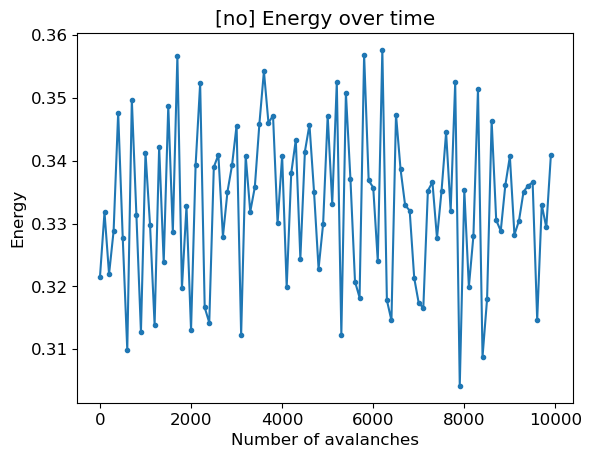

In [23]:
df = pd.read_csv(f"network_measures_{mode}_{V}.csv")

energy = df["energy"].values
steps = df["n_aval"].values

plt.figure()
plt.plot(steps, energy, '.-')
plt.xlabel("Number of avalanches")
plt.ylabel("Energy")
plt.title(f"[{mode}] Energy over time")
plt.show()


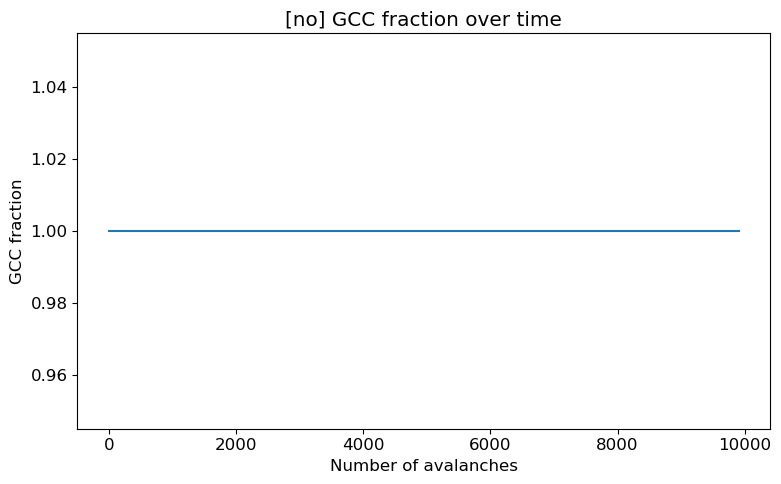

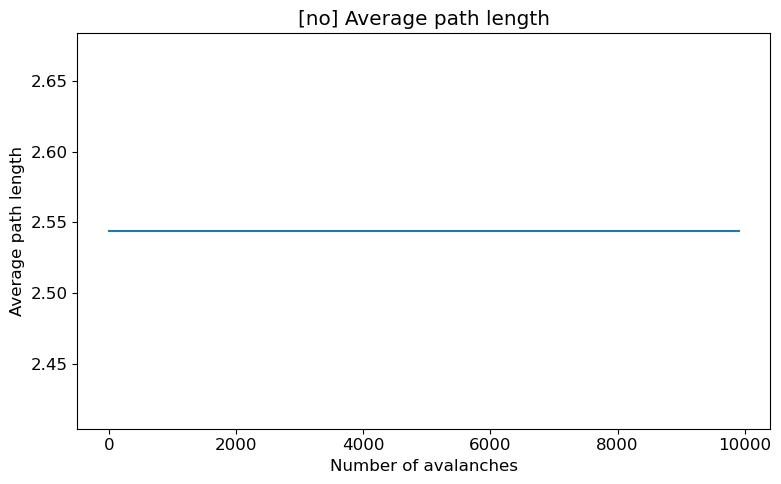

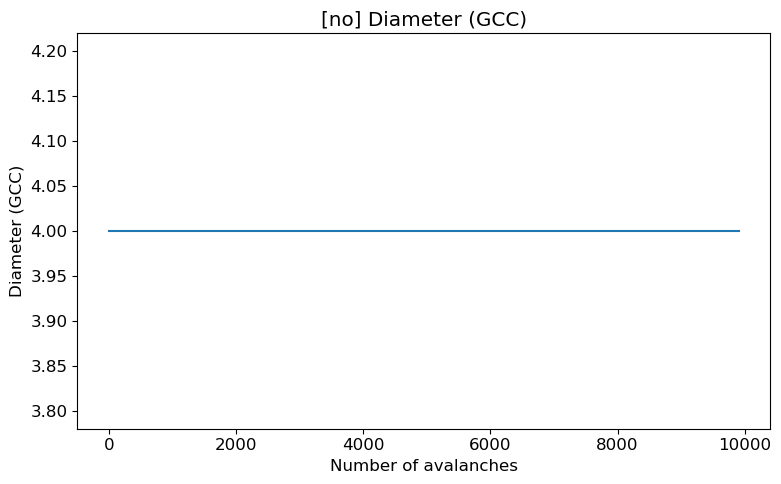

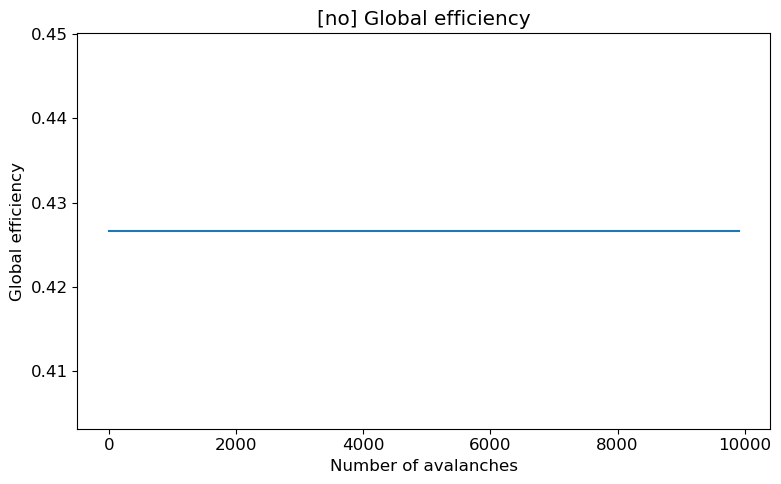

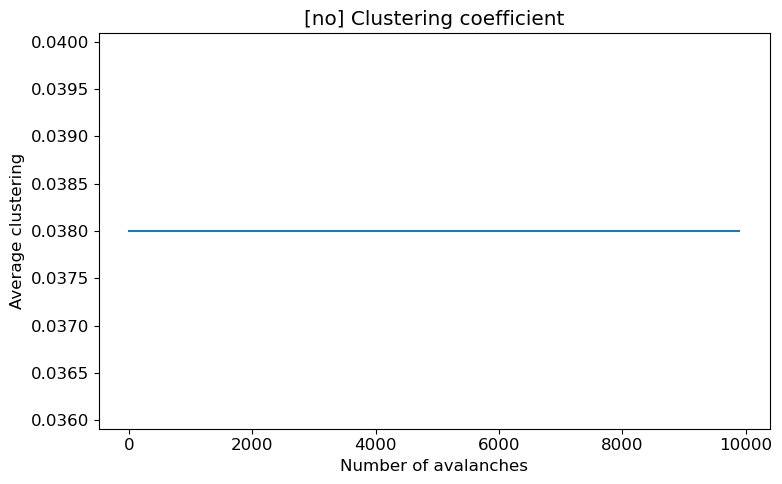

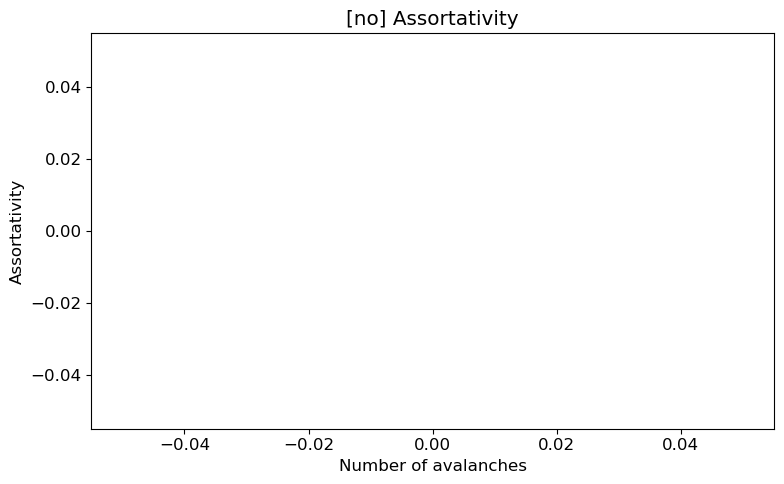

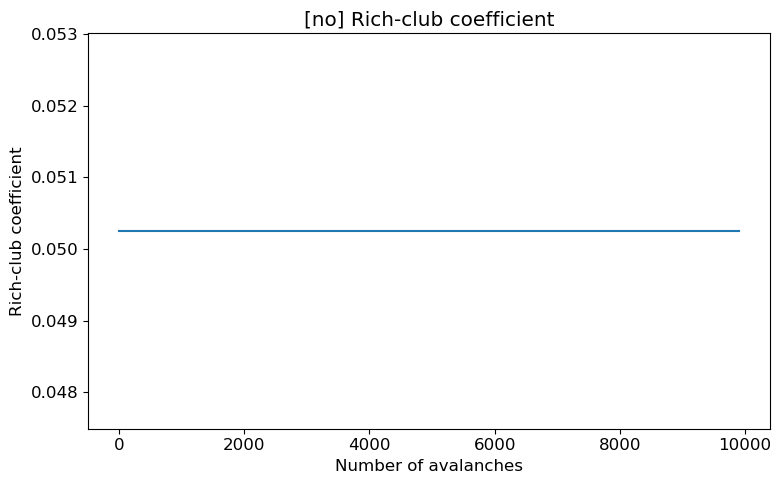

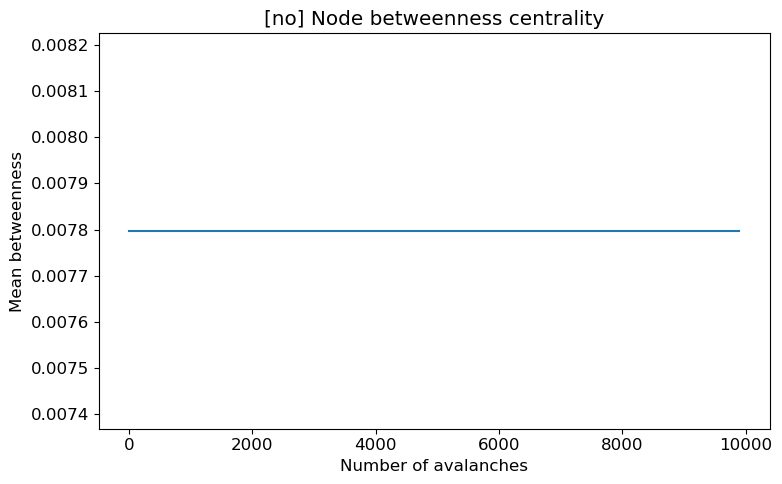

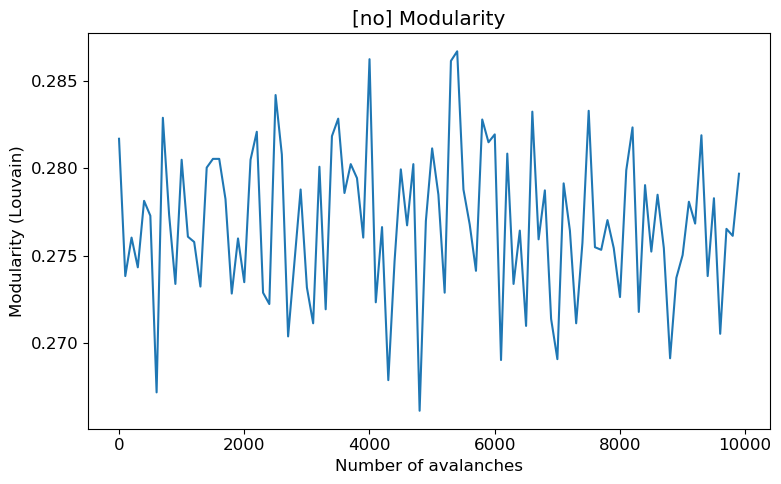

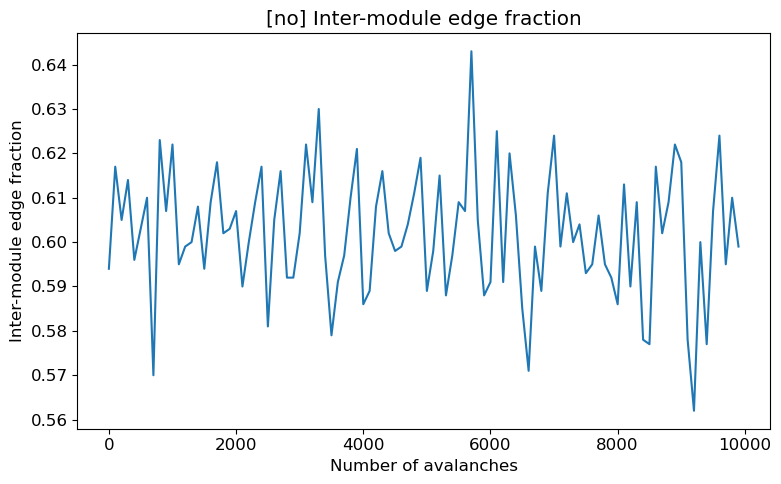

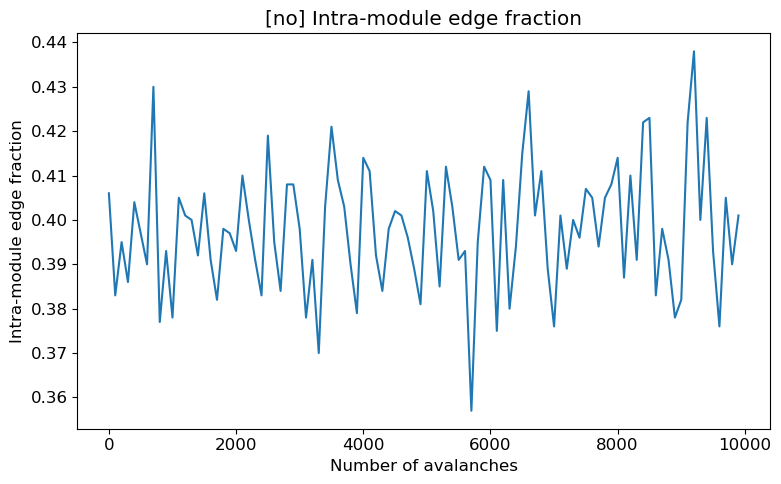

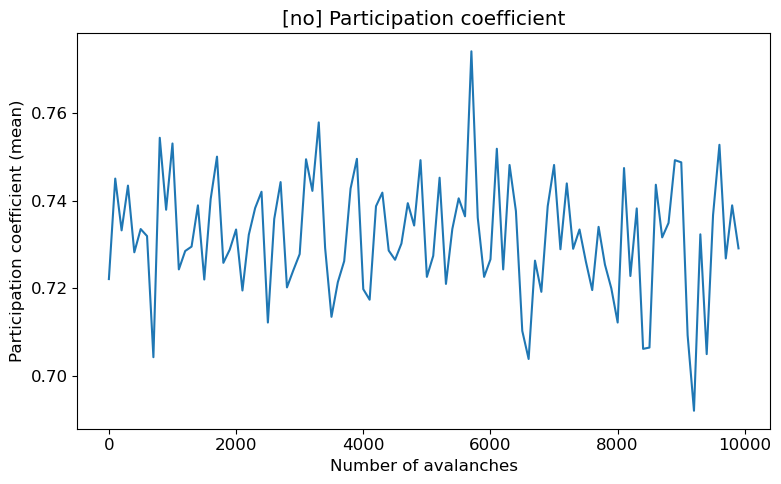

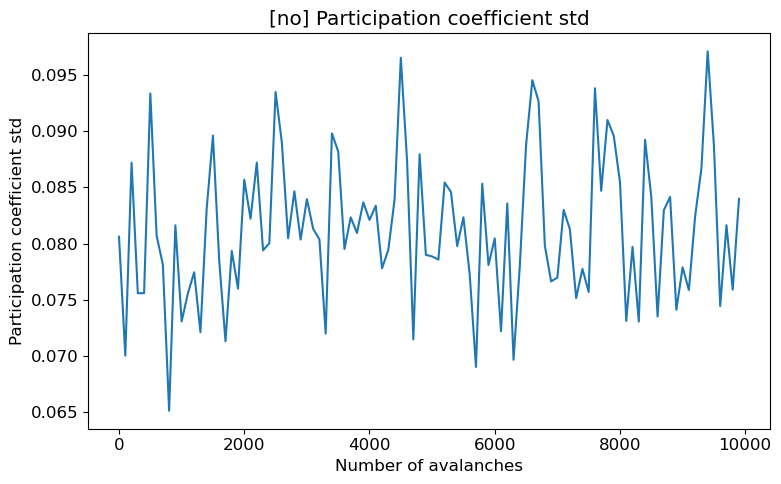

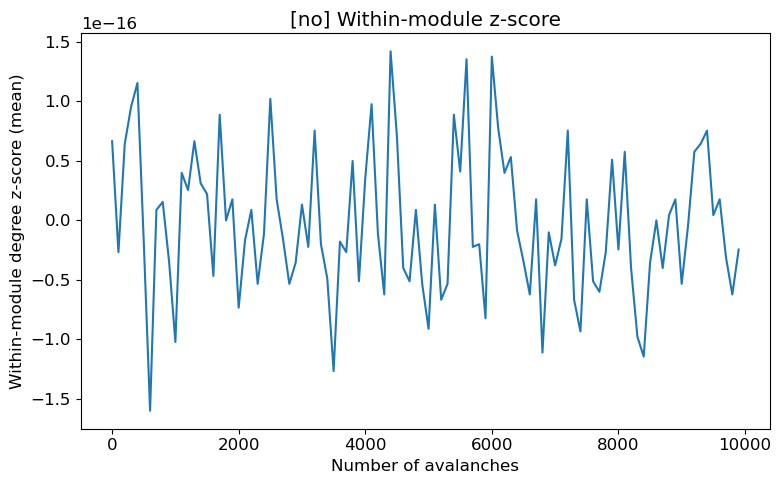

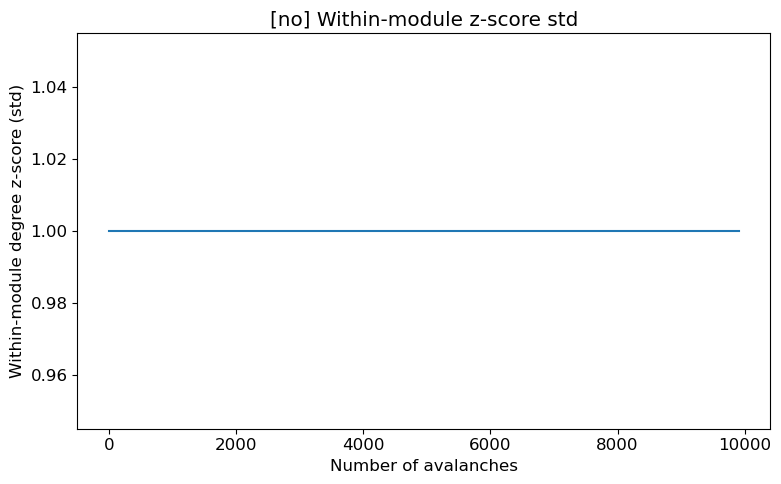

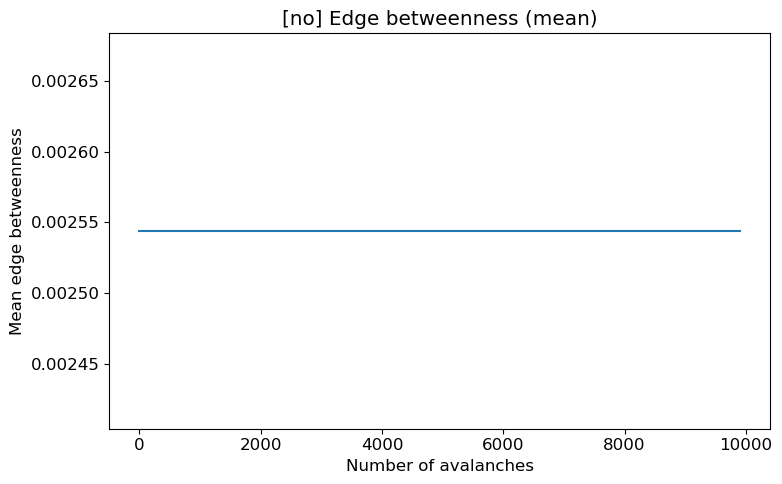

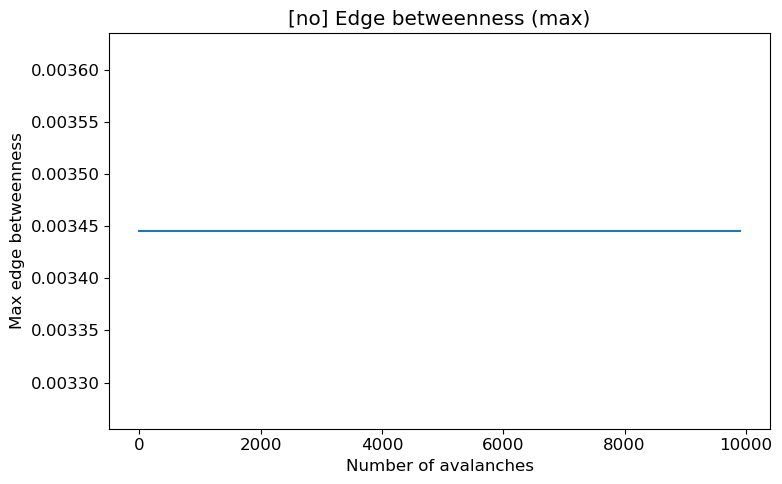

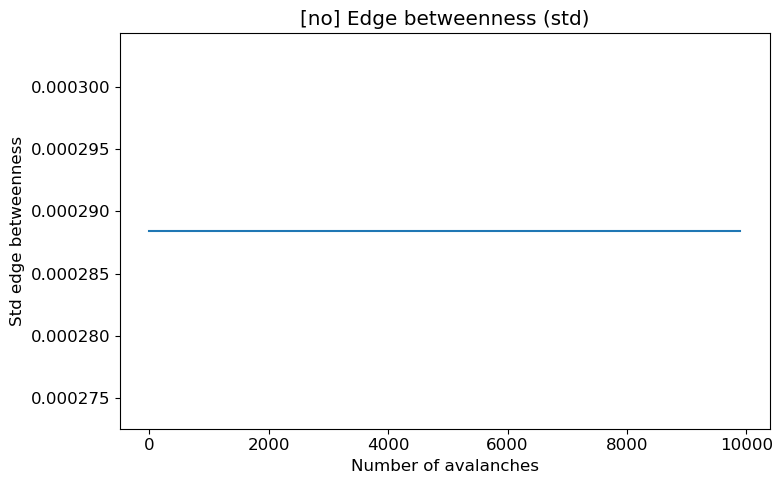

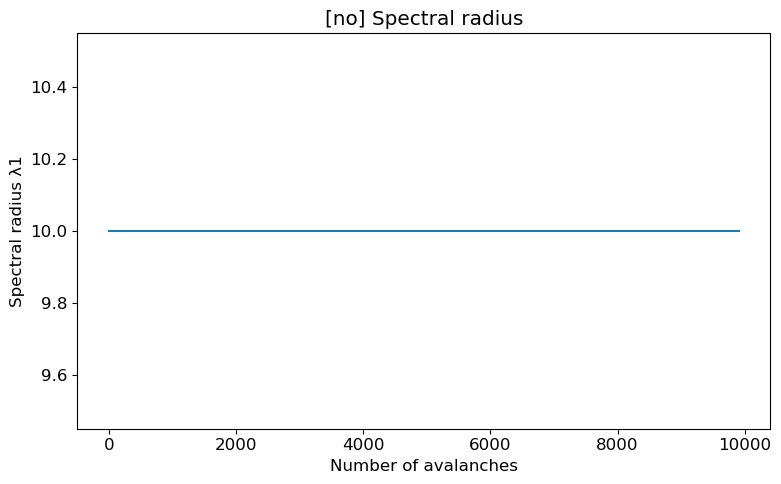

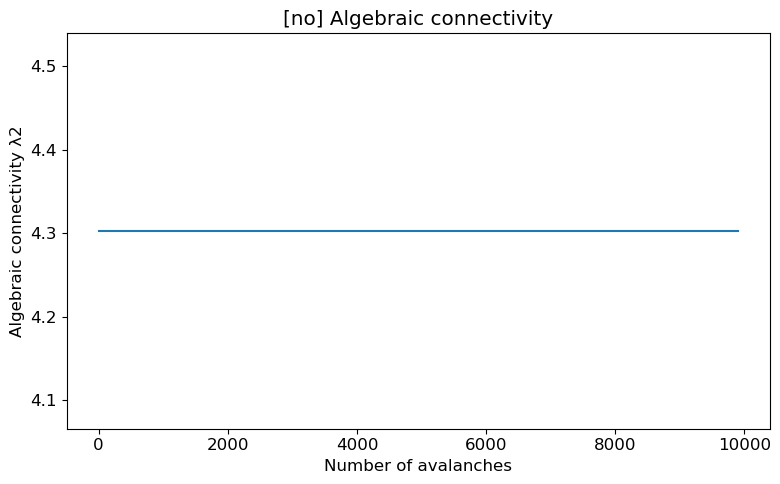

In [24]:
use_steps = False   # True: fast timescale (`cum_steps`); False: slow timescale (`n_aval`)
df_net = pd.read_csv(f"network_measures_{mode}_{V}.csv")
df_aval = pd.read_csv(f"avalanches_{mode}_{V}.csv")
df_act = pd.read_csv(f"global_activity_{mode}_{V}.csv")
try:
    df_lrtc = pd.read_csv(f"lrtc_summary_{mode}_{V}.csv")
except FileNotFoundError:
    df_lrtc = pd.DataFrame()


def get_x():
    if use_steps:
        if "cum_steps" in df_net.columns:
            return df_net["cum_steps"].values, "Steps"
        return np.arange(len(df_net)), "Steps (proxy)"

    if "n_aval" in df_net.columns:
        return df_net["n_aval"].values, "Number of avalanches"
    return np.arange(len(df_net)), "Number of avalanches (proxy)"


x_axis, xlabel = get_x()


def lineplot(y, ylabel, title, fname):
    plt.figure(figsize=(8, 5))
    plt.plot(x_axis, y, lw=1.5)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()


def maybe_plot(col, ylabel, title, fname):
    if col in df_net.columns:
        lineplot(df_net[col], ylabel, title, fname)
    else:
        print(f"Column {col} not found; skipping.")


# Basic graph metrics
maybe_plot("gcc_frac", "GCC fraction", f"[{mode}] GCC fraction over time", f"fig_{mode}_gcc_frac.png")
maybe_plot("avg_path_length", "Average path length", f"[{mode}] Average path length", f"fig_{mode}_apl.png")
maybe_plot("diameter", "Diameter (GCC)", f"[{mode}] Diameter (GCC)", f"fig_{mode}_diam.png")
maybe_plot("efficiency", "Global efficiency", f"[{mode}] Global efficiency", f"fig_{mode}_eff.png")
maybe_plot("clustering", "Average clustering", f"[{mode}] Clustering coefficient", f"fig_{mode}_clust.png")
maybe_plot("assortativity", "Assortativity", f"[{mode}] Assortativity", f"fig_{mode}_assort.png")
maybe_plot("rich_club_coeff", "Rich-club coefficient", f"[{mode}] Rich-club coefficient", f"fig_{mode}_rc.png")
maybe_plot("betweenness", "Mean betweenness", f"[{mode}] Node betweenness centrality", f"fig_{mode}_betweenness.png")
maybe_plot("modularity", "Modularity (Louvain)", f"[{mode}] Modularity", f"fig_{mode}_modularity.png")

# Community-structure metrics
maybe_plot("inter_edge_frac", "Inter-module edge fraction", f"[{mode}] Inter-module edge fraction", f"fig_{mode}_inter_edges.png")
maybe_plot("intra_edge_frac", "Intra-module edge fraction", f"[{mode}] Intra-module edge fraction", f"fig_{mode}_intra_edges.png")
maybe_plot("participation_mean", "Participation coefficient (mean)", f"[{mode}] Participation coefficient", f"fig_{mode}_participation_mean.png")
maybe_plot("participation_std", "Participation coefficient std", f"[{mode}] Participation coefficient std", f"fig_{mode}_participation_std.png")
maybe_plot("wmdeg_z_mean", "Within-module degree z-score (mean)", f"[{mode}] Within-module z-score", f"fig_{mode}_wmz_mean.png")
maybe_plot("wmdeg_z_std", "Within-module degree z-score (std)", f"[{mode}] Within-module z-score std", f"fig_{mode}_wmz_std.png")

# Edge-betweenness metrics
maybe_plot("edge_bw_mean", "Mean edge betweenness", f"[{mode}] Edge betweenness (mean)", f"fig_{mode}_edgebw_mean.png")
maybe_plot("edge_bw_max", "Max edge betweenness", f"[{mode}] Edge betweenness (max)", f"fig_{mode}_edgebw_max.png")
maybe_plot("edge_bw_std", "Std edge betweenness", f"[{mode}] Edge betweenness (std)", f"fig_{mode}_edgebw_std.png")

# Spectral metrics
maybe_plot("spectral_radius", "Spectral radius λ1", f"[{mode}] Spectral radius", f"fig_{mode}_spec_radius.png")
maybe_plot("algebraic_connectivity", "Algebraic connectivity λ2", f"[{mode}] Algebraic connectivity", f"fig_{mode}_algconn.png")


## Avalanche Exponents


#### DFA of activity and avalanche-size sequences with surrogate controls


In [25]:
# -----------------------------
# LRTC summary (DFA and PSD slope) on the full activity series
# -----------------------------
# Shared settings for originals and every surrogate.
dfa_settings = dict(min_window=4, max_frac=0.1, n_scales=25, min_segments=10)
avalanche_size_sequence = np.asarray([event[0] for event in avalanches], dtype=float)
dfa_val = dfa_alpha(activity_all, **dfa_settings)
dfa_size_val = dfa_alpha(avalanche_size_sequence, **dfa_settings)
print(f"Activity DFA: {dfa_val:.4f}; avalanche-size DFA: {dfa_size_val:.4f}")
series_length = int(len(activity_all))
aval_count = int(len(avalanches))

slope, info = psd_loglog_slope_robust(activity_all, fs=1.0, band=(1 / 2000, 0.05), use_diff=False)

df_lrtc_summary = pd.DataFrame([{
    "dfa_alpha": dfa_val,  # retained for compatibility with existing readers
    "dfa_alpha_activity": dfa_val,
    "dfa_alpha_size": dfa_size_val,
    "size_series_length": len(avalanche_size_sequence),
    "psd_slope": slope,
    "psd_r2": info.get("r2", np.nan),
    "psd_fit_method": info.get("robust", "unknown"),
    "series_length": series_length,
    "aval_count": aval_count,
    "mode": mode,
    "p_base": p_base,
}])
df_lrtc_summary.to_csv(f"lrtc_summary_{mode}_{V}.csv", index=False)

df_lrtc_summary


Activity DFA: 0.8738; avalanche-size DFA: 0.4874


,dfa_alpha,dfa_alpha_activity,dfa_alpha_size,size_series_length,psd_slope,psd_r2,psd_fit_method,series_length,aval_count,mode,p_base
0,0.873791,0.873791,0.487396,10000,-0.673389,0.770446,huber,73529,10000,no,0.1


DFA controls: activity, samples=73529
DFA shuffled: 25/100
DFA shuffled: 50/100
DFA shuffled: 75/100
DFA shuffled: 100/100
DFA blocked_shuffled: 25/100
DFA blocked_shuffled: 50/100
DFA blocked_shuffled: 75/100
DFA blocked_shuffled: 100/100


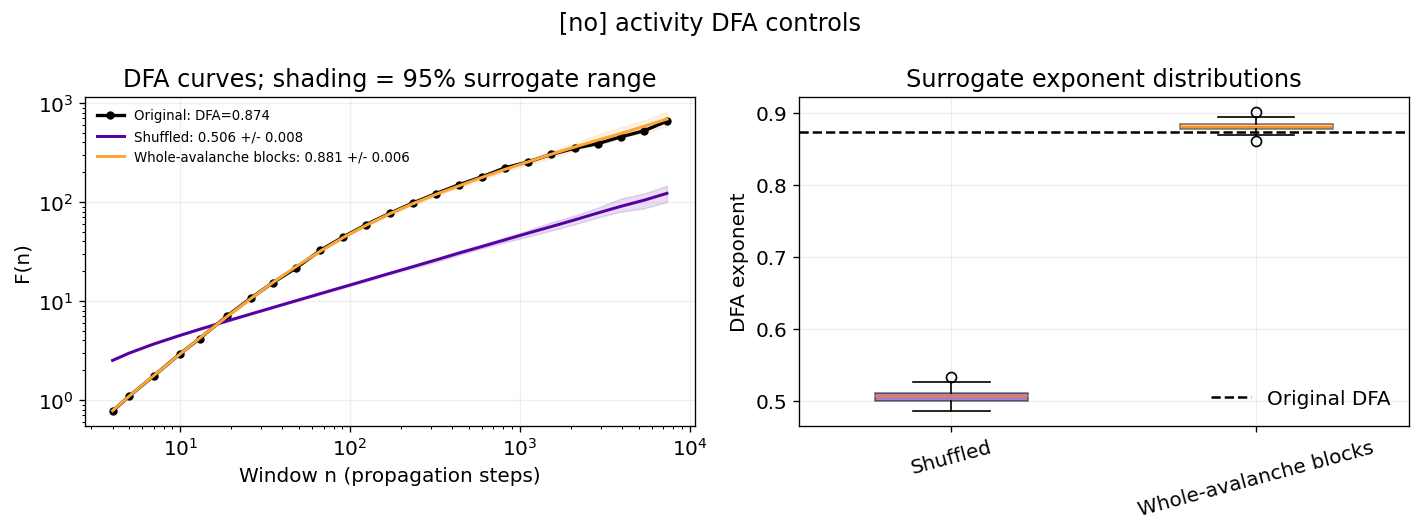

DFA controls: avalanche_size, samples=10000
DFA shuffled: 25/100
DFA shuffled: 50/100
DFA shuffled: 75/100
DFA shuffled: 100/100
DFA blocked_shuffled: 25/100
DFA blocked_shuffled: 50/100
DFA blocked_shuffled: 75/100
DFA blocked_shuffled: 100/100


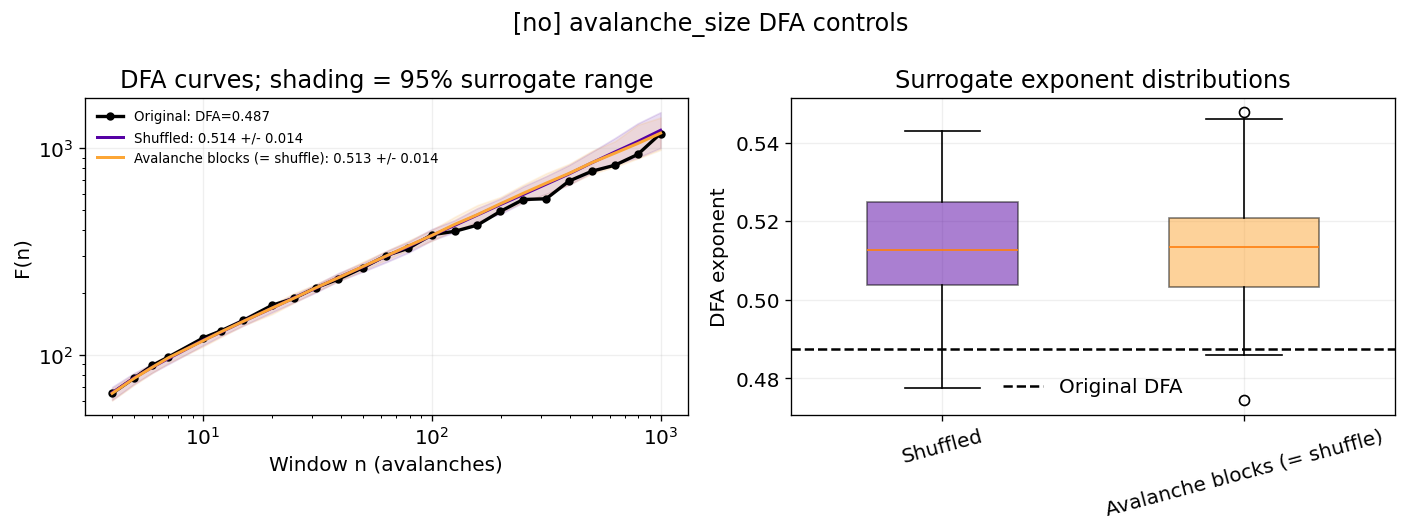

        series           method  alpha_mean  alpha_std  alpha_q025  alpha_q975  n_valid
      activity         original    0.873791        NaN         NaN         NaN        1
      activity         shuffled    0.506132   0.008452    0.491835    0.524835      100
      activity blocked_shuffled    0.880950   0.006284    0.870241    0.894015      100
avalanche_size         original    0.487396        NaN         NaN         NaN        1
avalanche_size         shuffled    0.513841   0.013811    0.487051    0.538907      100
avalanche_size blocked_shuffled    0.512822   0.014138    0.488001    0.542757      100


In [26]:
# Independent control RNGs; these do not change the simulation RNG.
dfa_n_surrogates = 100
dfa_control_seed = 13
# One whole avalanche per block, with boundaries from the simulation records.
# Length in activity_all = duration; sum of activity values = avalanche size.
dfa_avalanche_durations = avalanche_block_lengths(activity_all, avalanches)
dfa_block_lengths = {
    'activity': dfa_avalanche_durations,
    # One size value per avalanche: this control is equivalent to ordinary shuffle.
    'avalanche_size': np.ones(len(avalanche_size_sequence), dtype=int),
}
dfa_block_labels = {
    'activity': 'Whole-avalanche blocks',
    'avalanche_size': 'Avalanche blocks (= shuffle)',
}
dfa_block_stops = np.cumsum(dfa_avalanche_durations)
df_dfa_avalanche_blocks = pd.DataFrame({
    'avalanche_index': np.arange(len(avalanches)),
    'activity_start': np.concatenate(([0], dfa_block_stops[:-1])),
    'activity_stop_exclusive': dfa_block_stops,
    'duration': dfa_avalanche_durations,
    'size': avalanche_size_sequence,
})
df_dfa_avalanche_blocks.to_csv(f"main_dfa_avalanche_blocks_{mode}_{V}.csv", index=False)
dfa_control_inputs = {
    'activity': np.asarray(activity_all, dtype=float),
    'avalanche_size': avalanche_size_sequence,
}
dfa_control_seeds = np.random.SeedSequence(dfa_control_seed).spawn(len(dfa_control_inputs))
dfa_control_results = {}
for (series_name, sequence), control_seed in zip(dfa_control_inputs.items(), dfa_control_seeds):
    print(f"DFA controls: {series_name}, samples={len(sequence)}")
    dfa_control_results[series_name] = dfa_surrogate_controls(
        sequence, n_surrogates=dfa_n_surrogates,
        block_lengths=dfa_block_lengths[series_name],
        block_label=dfa_block_labels[series_name], seed=control_seed,
        dfa_kwargs=dfa_settings,
    )
    unit = 'propagation steps' if series_name == 'activity' else 'avalanches'
    plot_dfa_controls(
        dfa_control_results[series_name], f"[{mode}] {series_name} DFA controls",
        scale_label=f"Window n ({unit})",
        fname=f"fig_main_dfa_controls_{series_name}_{mode}_{V}.png",
    )

df_dfa_controls_summary = pd.concat([
    result['summary'].assign(series=series_name, block_unit='one_avalanche')
    for series_name, result in dfa_control_results.items()
], ignore_index=True)
df_dfa_controls_replicates = pd.concat([
    result['replicates'].assign(series=series_name)
    for series_name, result in dfa_control_results.items()
], ignore_index=True)
df_dfa_controls_curves = pd.concat([
    result['curves'].assign(series=series_name)
    for series_name, result in dfa_control_results.items()
], ignore_index=True)
# Record the exact DFA settings and seed with the summary.
for key, value in dfa_settings.items():
    df_dfa_controls_summary[f'dfa_{key}'] = value
df_dfa_controls_summary['seed'] = dfa_control_seed
df_dfa_controls_summary.to_csv(f"main_dfa_controls_summary_{mode}_{V}.csv", index=False)
df_dfa_controls_replicates.to_csv(f"main_dfa_controls_replicates_{mode}_{V}.csv", index=False)
df_dfa_controls_curves.to_csv(f"main_dfa_controls_curves_{mode}_{V}.csv", index=False)
print(df_dfa_controls_summary[['series', 'method', 'alpha_mean', 'alpha_std',
                               'alpha_q025', 'alpha_q975', 'n_valid']].to_string(index=False))


[no] Avalanche size distribution: alpha=1.4999, slope=-1.4999, xmin=1, KS=0.0306, tail=9000/9000, span=3.38 decades


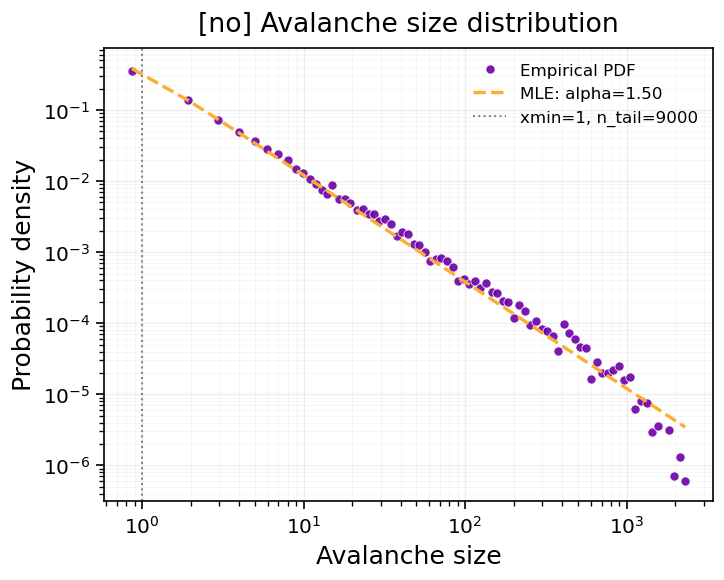

[no] Avalanche duration distribution: alpha=1.7637, slope=-1.7637, xmin=2, KS=0.0726, tail=5831/9000, span=2.23 decades


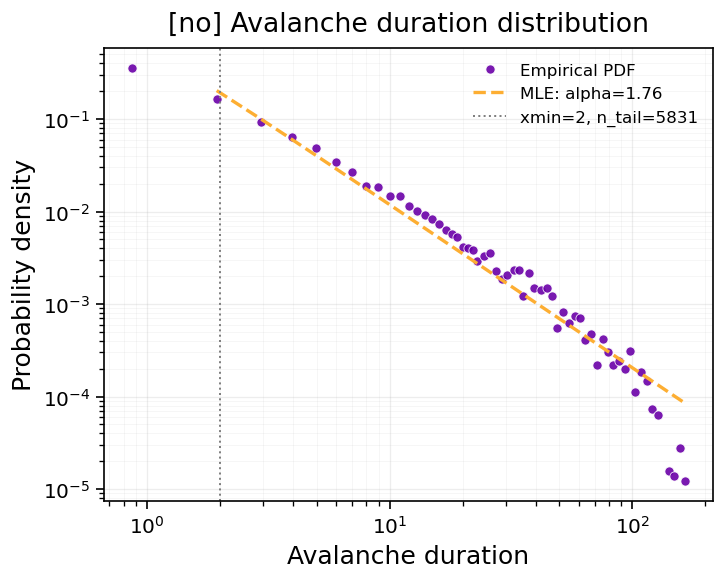

Span (decades): size≈3.38, duration≈2.23


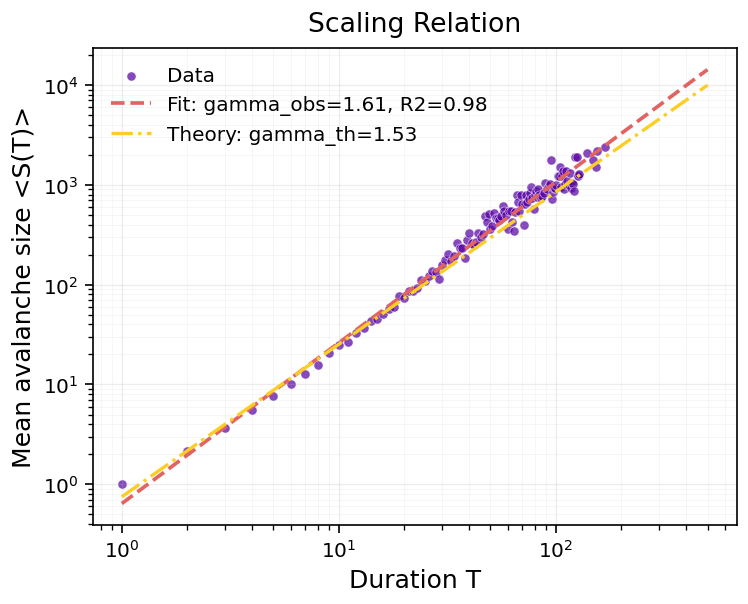


--- Scaling Consistency ---
gamma_obs (fit)   = 1.611
gamma_theory      = 1.528
Delta gamma       = 0.083
Relative Δγ       = 5.45%
R² (fit quality)  = 0.983
---------------------------


In [ ]:
df_aval = pd.read_csv(f"avalanches_{mode}_{V}.csv") 
df_aval = df_aval.iloc[999:-1]
tau_s, span_size = loglog_hist_MLE(df_aval["size"].values, xmin=None, nbins=100, xlabel="Avalanche size",
            title=f"[{mode}] Avalanche size distribution", fname=f"fig_aval_size.png")
tau_d, span_dur = loglog_hist_MLE(df_aval["duration"].values, xmin=None, nbins=100, xlabel="Avalanche duration",
            title=f"[{mode}] Avalanche duration distribution", fname=f"fig_aval_dur.png")
print(f"Span (decades): size≈{span_size:.2f}, duration≈{span_dur:.2f}")

# Standalone bootstrap statistics below are independent of the scaling plot.
# Positive PDF exponents: tau for size, alpha for duration.
# Paired resampling preserves their covariance in gamma_th = (alpha-1)/(tau-1).
# refit_xmin=True includes cutoff-selection uncertainty; False fixes the cutoffs.
# block_length=1 assumes independent stationary avalanches; increase if needed.
# bootstrap_main = bootstrap_avalanche_exponents(
#     df_aval, n_boot=1000, seed=13, refit_xmin=True, block_length=1,
# )
# bootstrap_main['summary'].to_csv(f"main_bootstrap_summary_{mode}_{V}.csv")
# bootstrap_main['samples'].to_csv(f"main_bootstrap_samples_{mode}_{V}.csv")

res = compare_scaling(df_aval, tau_s, tau_d,
                      duration_range=(1, 500),
                      savefig="scaling_relation.png")

# linear fitting
# tau_s, span_size = loglog_hist(df_aval["size"].values, nbins=100, xlabel="Avalanche size",
#             title=f"[{mode}] Avalanche size distribution", fname=f"fig_aval_size.png")
# tau_d, span_dur = loglog_hist(df_aval["duration"].values, nbins=100, xlabel="Avalanche duration",
#             title=f"[{mode}] Avalanche duration distribution", fname=f"fig_aval_dur.png")
# res = compare_scaling(df_aval, tau_s, tau_d,
#                       duration_range=(1, 500),
#                       savefig="scaling_relation.png")


#### Quantifying avalanche-shape collapse

Methods background: [quantitative shape-collapse analysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC4921690/), [general collapse residuals](https://arxiv.org/abs/cond-mat/0102515). 


In [28]:
def load_shape_collapse_data(file, duration_range, burn_in_records=0,
                             drop_last=False, chunksize=250000, verbose=True):
    """Read only needed columns and durations; avoid loading long avalanches.

    Optional burn-in counts ALL avalanche records in file order, not just those
    in the selected duration range. Returned trajectories are never truncated.
    """
    if len(duration_range) != 2 or not 2 <= duration_range[0] <= duration_range[1]:
        raise ValueError('Need 2 <= minimum duration <= maximum duration.')
    if int(burn_in_records) != burn_in_records or burn_in_records < 0:
        raise ValueError('burn_in_records must be a nonnegative integer.')
    pieces, ordered_ids, seen = [], [], set()
    columns = ['avalanche_id', 't', 'activity', 'duration']
    for i, chunk in enumerate(pd.read_csv(file, usecols=columns, chunksize=chunksize)):
        for avalanche_id in pd.unique(chunk['avalanche_id']):
            if avalanche_id not in seen:
                seen.add(avalanche_id)
                ordered_ids.append(avalanche_id)
        chosen = chunk.loc[chunk['duration'].between(*duration_range), columns]
        if not chosen.empty:
            pieces.append(chosen.copy())
        if verbose and (i + 1) % 10 == 0:
            print(f'Collapse input: read {(i + 1)*chunksize:,} rows; retaining only requested durations.')
    if not pieces:
        raise ValueError('No avalanche trajectories in the requested duration range.')
    stop = -1 if drop_last else None
    retained_ids = ordered_ids[int(burn_in_records):stop]
    data = pd.concat(pieces, ignore_index=True)
    data = data.loc[data['avalanche_id'].isin(retained_ids)].copy()
    if data.empty:
        raise ValueError('No selected trajectories remain after burn-in selection.')
    return data


def _shape_integral(y, x):
    # Last-axis trapezoidal integration, compatible with NumPy 1.x and 2.x.
    return np.sum(.5 * (y[..., 1:] + y[..., :-1]) * np.diff(x), axis=-1)


def _shape_dispersion(curves, x):
    """Equal-duration relative RMS about the master curve, with no local division."""
    master = curves.mean(axis=0)
    energy = float(_shape_integral(master**2, x))
    if not np.isfinite(energy) or energy <= 0:
        raise ValueError('Master-curve energy must be positive.')
    per_duration = np.sqrt(_shape_integral((curves-master)**2, x) / energy)
    return float(np.sqrt(np.mean(per_duration**2))), master, per_duration, energy


def _shape_quality_scores(raw_means, durations, gamma, x):
    curves = raw_means / durations[:, None]**(gamma-1)
    relative, master, per_duration, energy = _shape_dispersion(curves, x)
    areas = _shape_integral(curves, x)
    if np.any(areas <= 0):
        raise ValueError('All compared curves must have positive area.')
    shape_only = _shape_dispersion(curves / areas[:, None], x)[0]
    time_only = _shape_dispersion(raw_means, x)[0]  # gamma=1, same grid/durations
    improvement = 1-relative/time_only if time_only > 1e-14 else np.nan
    metrics = dict(relative_rmse=relative, shape_only_relative_rmse=shape_only,
                   amplitude_cv=float(areas.std(ddof=0)/areas.mean()),
                   time_only_relative_rmse=time_only, relative_improvement=improvement)
    return metrics, curves, master, per_duration, energy


def quantify_shape_collapse(data, gamma, duration_range=(5, 14), max_curves=10,
                            min_avalanches=20, n_grid=101, x_range=None,
                            n_boot=500, seed=13, progress_every=100):
    """Quantify the FIXED-gamma avalanche-shape collapse shown in this notebook.

    Native coordinate is t/T, as in the original plot. Compare only common
    overlap, with linear interpolation and NO extrapolation or added zero points.
    Durations have equal weight. Primary metric retains amplitude information;
    unit-area shape-only dispersion is a separate complementary diagnostic.
    Bootstrap whole avalanches independently WITHIN duration, keeping sample
    counts, chosen durations, gamma and grid fixed. CI is conditional on these;
    it neither includes gamma-fit uncertainty nor tests a null hypothesis.
    n_boot=0 returns point estimates and analytic sampling-noise RMS only,
    with empty replicates and NaN bootstrap uncertainty; no resampling is run.
    No universal score threshold establishes criticality or scaling.
    """
    if not np.isfinite(gamma):
        raise ValueError('gamma must be finite.')
    for name, value, lower in (('max_curves', max_curves, 2), ('min_avalanches', min_avalanches, 2),
                               ('n_grid', n_grid, 3), ('n_boot', n_boot, 0)):
        if not np.isfinite(value) or int(value) != value or value < lower:
            raise ValueError(f'{name} must be an integer >= {lower}.')
    required = ['avalanche_id', 't', 'activity', 'duration']
    if not set(required).issubset(data.columns):
        raise ValueError('Detailed data need avalanche_id, t, activity and duration.')
    chosen = data.loc[data['duration'].between(*duration_range), required].copy()
    if chosen.empty:
        raise ValueError('No requested durations are present.')
    if not np.all(np.isfinite(chosen[['t', 'activity', 'duration']].to_numpy(dtype=float))):
        raise ValueError('Trajectory values must be finite.')
    if (np.any(chosen['activity'] < 0) or np.any(chosen['duration'] < 2) or
            np.any(chosen['duration'] != np.floor(chosen['duration'])) or
            np.any(chosen['t'] != np.floor(chosen['t']))):
        raise ValueError('Activity must be nonnegative; t and duration must be valid integers.')
    if chosen['avalanche_id'].isna().any() or chosen.groupby('avalanche_id')['duration'].nunique().max() > 1:
        raise ValueError('Each avalanche_id must identify one trajectory with one duration.')
    counts = chosen.groupby('duration')['avalanche_id'].nunique().sort_index()
    eligible = counts.index[counts >= min_avalanches].to_numpy(dtype=int)
    if len(eligible) < 2:
        raise ValueError('Need at least two durations with min_avalanches complete examples each.')
    indices = np.linspace(0, len(eligible)-1, min(int(max_curves), len(eligible)), dtype=int)
    durations = eligible[indices]
    selection = counts.rename('n_avalanches').reset_index()
    selection['eligible'] = selection['n_avalanches'] >= min_avalanches
    selection['used'] = selection['duration'].isin(durations)
    common_lo, common_hi = 0., float(np.min((durations-1)/durations))
    if x_range is not None:
        if not common_lo <= x_range[0] < x_range[1] <= common_hi:
            raise ValueError(f'x_range must lie in common overlap [{common_lo}, {common_hi}].')
        common_lo, common_hi = x_range
    grid = np.linspace(common_lo, common_hi, int(n_grid))
    profiles, native, raw_means = {}, {}, []
    for duration in durations:
        part = chosen.loc[chosen['duration'] == duration]
        if np.any((part['t'] < 0) | (part['t'] >= duration)):
            raise ValueError(f'T={duration}: time indices must run from 0 to T-1.')
        if part.duplicated(['avalanche_id', 't']).any():
            raise ValueError(f'T={duration}: duplicate avalanche/time rows.')
        matrix = part.pivot(index='avalanche_id', columns='t', values='activity').reindex(columns=np.arange(duration))
        if matrix.isna().any().any():
            raise ValueError(f'T={duration}: incomplete avalanche trajectories.')
        x_native = np.arange(duration)/duration
        native[int(duration)] = dict(x=x_native, mean=matrix.mean(axis=0).to_numpy(), n=len(matrix))
        interpolated = np.array([np.interp(grid, x_native, row) for row in matrix.to_numpy(dtype=float)])
        profiles[int(duration)] = interpolated
        raw_means.append(interpolated.mean(axis=0))
    raw_means = np.asarray(raw_means)
    scores, curves, master, per_duration, energy = _shape_quality_scores(raw_means, durations, gamma, grid)
    # Sampling contribution to dispersion of mean curves under independent
    # avalanches: subtracting a common estimated master contributes (1 - 1/K).
    mean_variances = np.array([profiles[int(t)].var(axis=0, ddof=1)/len(profiles[int(t)])
                              for t in durations]) / durations[:, None]**(2*(gamma-1))
    noise_sq = (1-1/len(durations))*np.mean(_shape_integral(mean_variances, grid))/energy
    noise_rms = float(np.sqrt(max(0., noise_sq)))
    rng = np.random.default_rng(seed)
    replicates = []
    for b in range(int(n_boot)):
        resampled_means = []
        for duration in durations:
            group = profiles[int(duration)]
            resampled_means.append(group[rng.integers(0, len(group), size=len(group))].mean(axis=0))
        sample_scores = _shape_quality_scores(np.array(resampled_means), durations, gamma, grid)[0]
        replicates.append(dict(replicate=b, **sample_scores))
        if progress_every and (b+1) % progress_every == 0:
            print(f'Shape-collapse bootstrap: {b+1}/{n_boot}')
    replicates = pd.DataFrame(replicates, columns=['replicate', *scores])
    summary = []
    for metric, value in scores.items():
        values = replicates[metric].to_numpy(dtype=float)
        finite = values[np.isfinite(values)]
        interval = np.percentile(finite, [2.5, 97.5]) if len(finite) else [np.nan, np.nan]
        summary.append(dict(metric=metric, estimate=value,
                            bootstrap_std=finite.std(ddof=1) if len(finite)>1 else np.nan,
                            ci95_low=interval[0], ci95_high=interval[1], n_valid=len(finite)))
    summary.append(dict(metric='sampling_noise_relative_rmse', estimate=noise_rms,
                        bootstrap_std=np.nan, ci95_low=np.nan, ci95_high=np.nan, n_valid=0))
    per_duration_table = pd.DataFrame({
        'duration': durations, 'n_avalanches': [native[int(t)]['n'] for t in durations],
        'relative_rmse': per_duration, 'scaled_area': _shape_integral(curves, grid),
    })
    curve_table = pd.DataFrame([
        dict(duration=int(t), x=float(x), y=float(y), master=float(m))
        for t, curve in zip(durations, curves) for x, y, m in zip(grid, curve, master)
    ])
    return dict(gamma=float(gamma), durations=durations, grid=grid, native=native,
                scaled_curves=curves, master=master, summary=pd.DataFrame(summary),
                replicates=replicates, per_duration=per_duration_table,
                selection=selection, curves=curve_table, n_boot=int(n_boot), seed=seed,
                min_avalanches=int(min_avalanches), sampling_noise_rmse=noise_rms)


def plot_shape_collapse_quality(result, fname=None):
    fig, (ax, ax_error) = plt.subplots(1, 2, figsize=(11, 4.6), dpi=120)
    colors = plt.cm.plasma(np.linspace(.12, .9, len(result['durations'])))
    for duration, curve, color in zip(result['durations'], result['scaled_curves'], colors):
        ax.plot(result['grid'], curve, color=color, alpha=.8, label=f'T={duration}')
    spread = result['scaled_curves'].std(axis=0, ddof=0)
    ax.fill_between(result['grid'], result['master']-spread, result['master']+spread,
                    color='black', alpha=.10, label='Between-duration SD')
    ax.plot(result['grid'], result['master'], color='black', linestyle='--', linewidth=2, label='Equal-duration master')
    row = result['summary'].set_index('metric').loc['relative_rmse']
    ax.set(title=f"Relative RMS={row['estimate']:.3f}; 95% bootstrap [{row['ci95_low']:.3f}, {row['ci95_high']:.3f}]",
           xlabel='t/T (common overlap; no extrapolation)', ylabel='Mean activity / T^(gamma-1)')
    ax.legend(frameon=False, fontsize=7, ncol=2)
    per = result['per_duration']
    ax_error.bar(per['duration'].astype(str), 100*per['relative_rmse'], color=colors)
    for i, (_, item) in enumerate(per.iterrows()):
        ax_error.annotate(f"n={int(item['n_avalanches'])}", (i, 100*item['relative_rmse']),
                          xytext=(0, 4), textcoords='offset points', ha='center', fontsize=7)
    ax_error.set(xlabel='Duration T', ylabel='Relative RMS deviation (%)', title='Contribution of each duration')
    for panel in (ax, ax_error):
        panel.grid(alpha=.2)
    fig.tight_layout()
    if fname:
        fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return fig


Shape-collapse bootstrap: 100/500
Shape-collapse bootstrap: 200/500
Shape-collapse bootstrap: 300/500
Shape-collapse bootstrap: 400/500
Shape-collapse bootstrap: 500/500


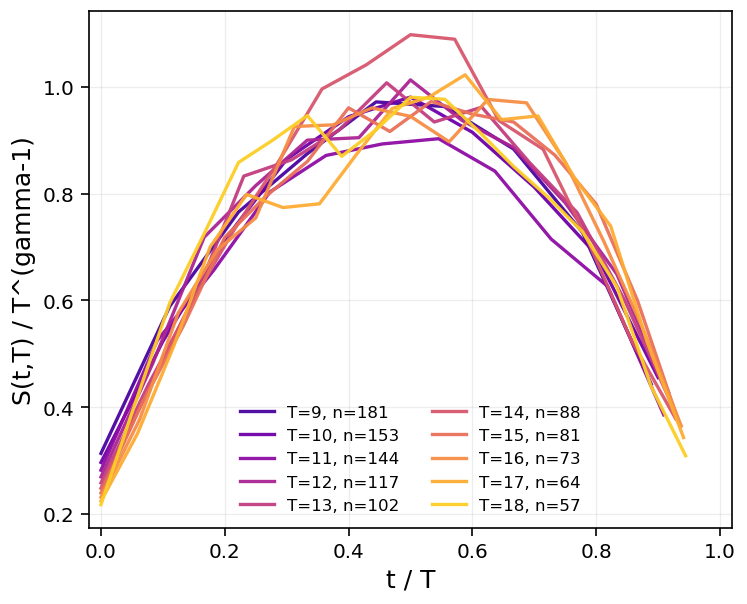

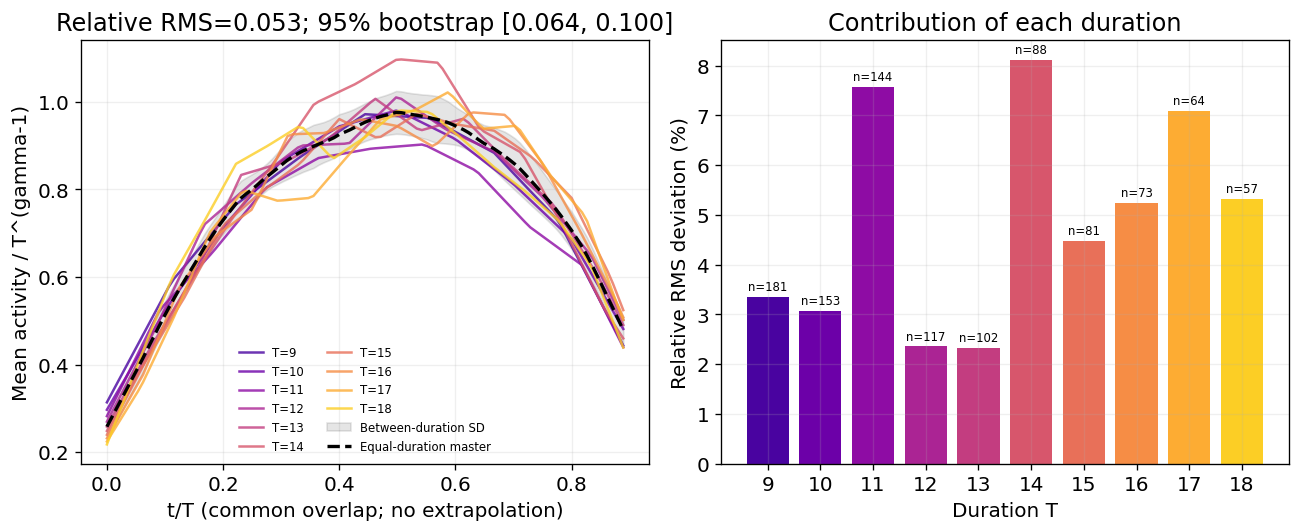

Smaller relative_rmse means closer FULL collapse; zero means identical curves.
shape_only_relative_rmse removes area differences and cannot validate amplitude scaling.
time_only_relative_rmse uses gamma=1 on the same curves/grid; improvement may be negative.
sampling_noise_relative_rmse estimates finite-count noise under independent avalanches.
Bootstrap SD/ranges are conditional on gamma and are not a pass/fail significance test.
                      metric  estimate  bootstrap_std  ci95_low  ci95_high  n_valid    gamma  x_min    x_max  n_durations  n_grid  n_boot  seed  min_avalanches  burn_in_records  drop_last
               relative_rmse  0.053009       0.009876  0.063713   0.100394      500 1.527801    0.0 0.888889           10     101     500    13              20                0      False
    shape_only_relative_rmse  0.045517       0.006965  0.049905   0.075967      500 1.527801    0.0 0.888889           10     101     500    13              20                0      False
 

In [29]:
# Estimate gamma from the scaling relation S ~ T^gamma.
gamma = (tau_d + 1) / (tau_s + 1)

# Collapse-plot settings.
T_min, T_max = 9, 18
n_curves = 10
show_legend = True
savefig = None  # e.g. f"collapse_{mode}_{V}.png"

# Quantify only complete, adequately sampled durations, using the plotted gamma.
collapse_min_avalanches = 20
collapse_n_grid = 101
collapse_n_boot = 500
collapse_seed = 13
collapse_x_range = None  # None: full COMMON t/T overlap; e.g. (0.1, 0.8)
collapse_burn_in_records = 0  # preserves original collapse sample; 500 to match the MLE slice
collapse_drop_last = False  # use True with burn-in=500 to match df_aval.iloc[500:-1]
df = load_shape_collapse_data(
    f"avalanches_detailed_{mode}_{V}.csv", (T_min, T_max),
    burn_in_records=collapse_burn_in_records, drop_last=collapse_drop_last,
)
collapse_quality = quantify_shape_collapse(
    df, gamma, duration_range=(T_min, T_max), max_curves=n_curves,
    min_avalanches=collapse_min_avalanches, n_grid=collapse_n_grid,
    x_range=collapse_x_range, n_boot=collapse_n_boot, seed=collapse_seed,
)
durations_to_plot = collapse_quality['durations']
colors = plt.cm.plasma(np.linspace(0.12, 0.90, len(durations_to_plot)))

fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=120)
for c, T in zip(colors, durations_to_plot):
    native = collapse_quality['native'][int(T)]
    x_scaled = native['x']
    y_scaled = native['mean'] / (T ** (gamma - 1))
    ax.plot(x_scaled, y_scaled, color=c, linewidth=2.0, alpha=0.95, label=f"T={int(T)}, n={native['n']}")

ax.set_xlabel("t / T", fontsize=15)
ax.set_ylabel("S(t,T) / T^(gamma-1)", fontsize=15)
ax.set_xlim(-0.02, 1.02)
ax.tick_params(axis="both", which="major", labelsize=12, length=5, width=1.0)
ax.tick_params(axis="both", which="minor", length=3, width=0.8)
ax.grid(which="major", alpha=0.22, linewidth=0.8)
ax.grid(which="minor", alpha=0.10, linewidth=0.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.0)
if show_legend:
    ax.legend(frameon=False, fontsize=10, ncol=2, loc="best")
fig.tight_layout()
if savefig:
    fig.savefig(savefig, dpi=300, bbox_inches="tight")
plt.show()

# Conditional on the displayed gamma, fixed durations and the common time grid.
collapse_quality_summary = collapse_quality['summary'].copy()
collapse_quality_summary['gamma'] = gamma
collapse_quality_summary['x_min'] = collapse_quality['grid'][0]
collapse_quality_summary['x_max'] = collapse_quality['grid'][-1]
collapse_quality_summary['n_durations'] = len(durations_to_plot)
collapse_quality_summary['n_grid'] = collapse_n_grid
collapse_quality_summary['n_boot'] = collapse_n_boot
collapse_quality_summary['seed'] = collapse_seed
collapse_quality_summary['min_avalanches'] = collapse_min_avalanches
collapse_quality_summary['burn_in_records'] = collapse_burn_in_records
collapse_quality_summary['drop_last'] = collapse_drop_last
collapse_quality_summary.to_csv(f"main_shape_collapse_quality_{mode}_{V}.csv", index=False)
collapse_quality['per_duration'].to_csv(f"main_shape_collapse_by_duration_{mode}_{V}.csv", index=False)
collapse_quality['selection'].to_csv(f"main_shape_collapse_selection_{mode}_{V}.csv", index=False)
collapse_quality['replicates'].to_csv(f"main_shape_collapse_bootstrap_{mode}_{V}.csv", index=False)
collapse_quality['curves'].to_csv(f"main_shape_collapse_common_curves_{mode}_{V}.csv", index=False)
plot_shape_collapse_quality(collapse_quality, fname=f"fig_main_shape_collapse_quality_{mode}_{V}.png")
print('Smaller relative_rmse means closer FULL collapse; zero means identical curves.')
print('shape_only_relative_rmse removes area differences and cannot validate amplitude scaling.')
print('time_only_relative_rmse uses gamma=1 on the same curves/grid; improvement may be negative.')
print('sampling_noise_relative_rmse estimates finite-count noise under independent avalanches.')
print('Bootstrap SD/ranges are conditional on gamma and are not a pass/fail significance test.')
print(collapse_quality_summary.to_string(index=False))
print(collapse_quality['per_duration'].to_string(index=False))


## Critical window

This part is for calculating the criticality indicators (DFA, PSD and rho).
Please use 'critical window definition.m' to check the critical window

In [30]:
def run_simulation(a, p_base, noise_level, ep=0, return_spans=False, *,
                   return_metrics=False, burn_in_records=1000, rho_use_similarity=False,
                   scaling_duration_range=(2, 1e3),
                   collapse_duration_range=(5, 14), collapse_min_avalanches=20,
                   collapse_max_curves=10, collapse_n_grid=101):
    """Critical-window simulation and numerical diagnostics, with no plots/bootstrap.

    Default tuple returns preserve existing callers and negative MLE PDF slopes.
    return_metrics=True returns all scan metrics as a dictionary instead.
    rho_use_similarity=False: M = A @ diag(clip(p_values, 0, 1)).
    rho_use_similarity=True: multiply M elementwise by 1 - abs(x_i - x_j).
    Similarity uses the FINAL activation snapshot, not an avalanche/time average.
    This flag controls spectral analysis only; propagation rules remain as defined.
    This model uses shared p_base, so p_values are constant in node-list order.
    Scaling and collapse use the same post-burn-in avalanches, excluding the last.
    DFA/PSD retain the existing definition using the full concatenated activity.
    """
    if not isinstance(rho_use_similarity, (bool, np.bool_)):
        raise TypeError('rho_use_similarity must be True or False.')
    if int(burn_in_records) != burn_in_records or burn_in_records < 0:
        raise ValueError('burn_in_records must be a nonnegative integer.')
    burn_in_records = int(burn_in_records)
    G = generate_network(network, V, d, n_modules=3, p=0.1, seed=rng, show=False)
    for n in G.nodes():
        G.nodes[n]['activation'] = rng.uniform(0., 1.)

    avalanches, activity_all, shape_rows = [], [], []
    for i in range(1, max_avalanches+1):
        update_activation_null(G, noise_level)
        size, dur, ser = one_avalanche(G, p_base=p_base, rng=rng, track_edges=False)
        avalanches.append((size, dur))
        activity_all.extend(ser)
        # Keep only complete profiles needed for collapse, from the exact MLE slice.
        if (burn_in_records < i < max_avalanches
                and collapse_duration_range[0] <= dur <= collapse_duration_range[1]):
            shape_rows.extend((i, t, value, dur) for t, value in enumerate(ser))

    df_aval = pd.DataFrame(avalanches, columns=['size', 'duration']).iloc[burn_in_records:-1]
    dfa_val = dfa_alpha(activity_all)
    slope, info = psd_loglog_slope_robust(activity_all, fs=1.,
                                        band=(1/2000, .05), use_diff=False)
    # Fit raw samples directly: identical MLE, without histogram figures or files.
    fit_s = _fit_discrete_powerlaw_MLE(df_aval['size'].to_numpy())
    fit_d = _fit_discrete_powerlaw_MLE(df_aval['duration'].to_numpy())
    tau_s, tau_d = -fit_s['alpha'], -fit_d['alpha']
    def span(values):
        values = np.asarray(values)
        return float(np.log10(values.max()/values.min())) if values.size else 0.
    span_size, span_dur = span(df_aval['size']), span(df_aval['duration'])

    nodes = list(G.nodes())
    A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
    p_values = np.full(len(nodes), float(p_base))
    P = np.diag(np.clip(p_values, 0.0, 1.0))
    M = A @ P
    if rho_use_similarity:
        activations = np.asarray([G.nodes[n]['activation'] for n in nodes], dtype=float)
        if not np.all(np.isfinite(activations) & (activations >= 0) & (activations <= 1)):
            raise ValueError('Similarity requires finite node activations in [0, 1].')
        similarity = 1.0 - np.abs(activations[:, None] - activations[None, :])
        M = M * similarity
    # M is generally asymmetric when node probabilities differ.
    # Use eigvals (not eigvalsh); rho is the largest eigenvalue magnitude.
    spectrumM = np.linalg.eigvals(M)
    eigenvalues = spectrumM
    rho = float(np.max(np.abs(spectrumM)))
    lambda_max = spectrumM[np.argmax(spectrumM.real)]

    metrics = dict(dfa=float(dfa_val), rho=rho, tau_s=tau_s, tau_d=tau_d,
                   rho_use_similarity=bool(rho_use_similarity),
                   rho_activation_snapshot='final' if rho_use_similarity else 'not_used',
                   slope=float(slope), span_size=span_size, span_dur=span_dur,
                   gamma_obs=np.nan, gamma_theory=np.nan, delta_rel=np.nan,
                   relative_delta_gamma=np.nan, scaling_R2=np.nan,
                   relative_rmse=np.nan, shape_only_relative_rmse=np.nan,
                   time_only_relative_rmse=np.nan, sampling_noise_relative_rmse=np.nan,
                   amplitude_cv=np.nan, relative_improvement=np.nan,
                   collapse_n_durations=0, scaling_status='not_available',
                   collapse_status='not_available', n_analysis_avalanches=len(df_aval))
    if np.isfinite(tau_s) and np.isfinite(tau_d):
        try:
            scaling = compare_scaling(df_aval, tau_s, tau_d,
                duration_range=scaling_duration_range, bootstrap_result=None,
                plot=False, verbose=False)
            metrics.update(gamma_obs=scaling['gamma_obs'], gamma_theory=scaling['gamma_theory'],
                           delta_rel=scaling['delta_rel'], relative_delta_gamma=scaling['delta_rel'],
                           scaling_R2=scaling['R2'], scaling_status='ok')
        except ValueError as error:
            metrics['scaling_status'] = str(error)
        gamma = (tau_d+1)/(tau_s+1)
        if np.isfinite(gamma):
            try:
                data = pd.DataFrame(shape_rows, columns=['avalanche_id', 't', 'activity', 'duration'])
                collapse = quantify_shape_collapse(data, gamma,
                    duration_range=collapse_duration_range, max_curves=collapse_max_curves,
                    min_avalanches=collapse_min_avalanches, n_grid=collapse_n_grid,
                    n_boot=0, progress_every=0)
                metrics.update(collapse['summary'].set_index('metric')['estimate'].to_dict())
                metrics.update(collapse_n_durations=len(collapse['durations']), collapse_status='ok')
            except ValueError as error:
                metrics['collapse_status'] = str(error)
    else:
        metrics['scaling_status'] = metrics['collapse_status'] = 'Insufficient data for MLE exponents.'

    print(f"Mode={mode}, p_base={p_base}, a={a}; "
          f"DFA={dfa_val:.4f}, rho(M)={rho:.4f} (similarity={rho_use_similarity}), tau_s={tau_s:.4f}, tau_d={tau_d:.4f}, "
          f"relative delta gamma={metrics['relative_delta_gamma']:.4g} "
          f"({100*metrics['relative_delta_gamma']:.2f}%)")
    print('Collapse: ' + ', '.join(f'{name}={metrics[name]:.5g}' for name in (
        'relative_rmse', 'shape_only_relative_rmse', 'time_only_relative_rmse',
        'sampling_noise_relative_rmse')))
    for key in ['scaling_status', 'collapse_status']:
        if metrics[key] != 'ok':
            print(f'{key}: {metrics[key]}')
    if return_metrics:
        return metrics
    if return_spans:
        return tau_s, tau_d, span_size, span_dur, dfa_val, slope
    return tau_s, tau_d, dfa_val, slope


In [ ]:
mode = 'no'
network = 'regular' # random, sw, regular, modular

# -------------------------------
# setting
# -------------------------------
noise_level = 0
N_repeat = 1        
p_base_values = np.linspace(0.08, 0.11,21)
a_values = np.linspace(1,100,100)


# Analysis settings: matched post-burn-in samples; no figures or bootstrap.
# Spectrum only: False -> A @ P （without ST); True -> (A @ P) * (1 - |x_i-x_j|) (with ST).
# True uses final activations; it is a snapshot, not a time-averaged spectrum.
critical_rho_use_similarity = False
critical_burn_in_records = 1000
critical_scaling_duration_range = (2, 1e3)
critical_collapse_duration_range = (5, 14)
critical_collapse_min_avalanches = 20

shape = (len(a_values), len(p_base_values))
metric_names = ['tau_s', 'tau_d', 'dfa', 'slope', 'rho', 'relative_delta_gamma',
                'gamma_obs', 'gamma_theory', 'scaling_R2',
                'relative_rmse', 'shape_only_relative_rmse', 'time_only_relative_rmse',
                'sampling_noise_relative_rmse', 'amplitude_cv', 'relative_improvement']
metric_matrices = {name: np.full(shape, np.nan) for name in metric_names}
scan_rows, repeat_rows = [], []
for i, a in enumerate(a_values):
    for j, p_base in enumerate(p_base_values):
        repeats = []
        print(f"Running [{i},{j}] a={a:.3f}, p={p_base:.3f} ...")
        for k in range(N_repeat):
            try:
                metrics = run_simulation(a, p_base, noise_level, ep=0,
                    return_metrics=True, burn_in_records=critical_burn_in_records,
                    rho_use_similarity=critical_rho_use_similarity,
                    scaling_duration_range=critical_scaling_duration_range,
                    collapse_duration_range=critical_collapse_duration_range,
                    collapse_min_avalanches=critical_collapse_min_avalanches)
            except Exception as error:
                print(f"Error at a={a:.3f}, p={p_base:.3f}, repeat={k}: {error}")
                repeat_rows.append(dict(a=a, p_base=p_base, repeat=k, rho_use_similarity=critical_rho_use_similarity, simulation_status=str(error)))
                continue
            repeats.append(metrics)
            repeat_rows.append(dict(a=a, p_base=p_base, repeat=k, simulation_status='ok', **metrics))
        row = dict(a=a, p_base=p_base, n_success=len(repeats),
                   rho_use_similarity=bool(critical_rho_use_similarity),
                   rho_activation_snapshot='final' if critical_rho_use_similarity else 'not_used')
        for name in metric_names:
            values = np.asarray([result[name] for result in repeats], dtype=float)
            finite = values[np.isfinite(values)]
            value = float(finite.mean()) if finite.size else np.nan
            metric_matrices[name][i, j] = value
            row[name] = value
            row[name+'_n_valid'] = len(finite)
        scan_rows.append(row)

# Preserve matrix names used by existing downstream cells.
tau_s_matrix, tau_d_matrix = metric_matrices['tau_s'], metric_matrices['tau_d']
dfa_matrix, slope_matrix = metric_matrices['dfa'], metric_matrices['slope']
rho_matrix = metric_matrices['rho']
relative_delta_gamma_matrix = metric_matrices['relative_delta_gamma']
df = pd.DataFrame(scan_rows)
scan_repeats_df = pd.DataFrame(repeat_rows)
df.to_csv('parameter_scan_with_regular_-2.csv', index=False)
scan_repeats_df.to_csv('parameter_scan_with_regular_repeats.csv', index=False)
print('Saved: parameter_scan_with_regular.csv and parameter_scan_with_regular_repeats.csv')
print(df[['a', 'p_base', 'dfa', 'rho', 'rho_use_similarity', 'tau_s', 'tau_d', 'relative_delta_gamma',
          'relative_rmse', 'shape_only_relative_rmse', 'time_only_relative_rmse',
          'sampling_noise_relative_rmse']].to_string(index=False))
# tau_s/tau_d keep the notebook's NEGATIVE PDF slope convention.
# relative_delta_gamma is a fraction (multiply by 100 for percent).



Running [0,0] a=1.000, p=0.135 ...
Mode=no, p_base=0.135, a=1.0; DFA=0.7678, rho(M)=0.9000 (similarity=True), tau_s=-1.7074, tau_d=-1.9783, relative delta gamma=0.1037 (10.37%)
Collapse: relative_rmse=0.10117, shape_only_relative_rmse=0.052708, time_only_relative_rmse=0.20808, sampling_noise_relative_rmse=0.048106
Running [0,1] a=1.000, p=0.136 ...
Mode=no, p_base=0.136, a=1.0; DFA=0.7628, rho(M)=0.9067 (similarity=True), tau_s=-1.6900, tau_d=-1.9538, relative delta gamma=0.08457 (8.46%)
Collapse: relative_rmse=0.10583, shape_only_relative_rmse=0.044827, time_only_relative_rmse=0.21384, sampling_noise_relative_rmse=0.046449
Running [0,2] a=1.000, p=0.137 ...
Mode=no, p_base=0.137, a=1.0; DFA=0.7400, rho(M)=0.9133 (similarity=True), tau_s=-1.6788, tau_d=-1.9410, relative delta gamma=0.0947 (9.47%)
Collapse: relative_rmse=0.09238, shape_only_relative_rmse=0.044307, time_only_relative_rmse=0.20066, sampling_noise_relative_rmse=0.047809
Running [0,3] a=1.000, p=0.138 ...
Mode=no, p_base=0.

## HTM dynamic range: no similarity term

Internal transmission is exactly `p`, matching this notebook's `one_avalanche`. For every p, $M=pA$ and $\rho(M)=p\rho(A)$, identical across repeats and independent of activation values. External Bernoulli input h is added after internal propagation; the measurement protocol, absorbing/low-drive fits and bootstrap remain unchanged.

The scan uses `p = dr_p_reference * dr_p_factors`, with `dr_p_reference = htm_p_reference` captured from the initial `p_base` parameter. The graph-based reference `pc_proxy = 1/rho(A)` is reported separately and NEVER silently replaces the chosen scan center. For a degree-10 regular graph it is 0.1. This is a linear spectral proxy, not a verified critical point. The former 0.15 came from `1/rho((2/3)*A)` belonging to the similarity model.

Earlier dynamic-range runs in this notebook used similarity in the actual propagation and must be rerun; changing their reported rho alone cannot convert those response curves to HTM. Corrected results carry `transmission_rule='homogeneous_no_similarity'` and use a separate HTM output directory. Saved activation arrays remain inert compatibility metadata only.


### classic version or absorbing baseline

In [37]:
def _dr_step(active, src, dst, log_failure, h, rng):
    """Exact conditional law of independent-edge propagation plus external input."""
    selected = active[src]
    log_inactive = np.bincount(dst[selected], weights=log_failure[selected],
                              minlength=active.size)
    probability = 1.0 - (1.0-h)*np.exp(log_inactive)
    return rng.random(active.size) < np.clip(probability, 0.0, 1.0)


def _dr_trajectory(src, dst, log_failure, n, h, burn_in, steps, n_blocks,
                   rng, initially_active=False):
    active = np.full(n, bool(initially_active))
    # The resting h=0 trajectory is the exact absorbing baseline.
    if h == 0 and not initially_active:
        series = np.zeros(steps)
    else:
        for _ in range(burn_in):
            active = _dr_step(active, src, dst, log_failure, h, rng)
        series = np.empty(steps)
        for t in range(steps):
            active = _dr_step(active, src, dst, log_failure, h, rng)
            series[t] = active.mean()
    blocks = np.array([v.mean() for v in np.array_split(series, n_blocks)])
    half = steps//2
    first, last = series[:half].mean(), series[half:].mean()
    left = np.array([v.mean() for v in np.array_split(series[:half], n_blocks//2)])
    right = np.array([v.mean() for v in np.array_split(series[half:], n_blocks//2)])
    drift_se = np.sqrt(left.var(ddof=1)/left.size + right.var(ddof=1)/right.size)
    drift_flag = bool(abs(last-first) > 3*drift_se + 1e-12)
    return dict(F=series.mean(), batch_se=blocks.std(ddof=1)/np.sqrt(n_blocks),
                first_half_F=first, last_half_F=last, drift_flag=drift_flag,
                final_activity=series[-1]), blocks


def _dr_fit(h, response):
    from sklearn.isotonic import IsotonicRegression
    h, response = np.asarray(h), np.asarray(response)
    fitted = IsotonicRegression(increasing=True, y_min=0, y_max=1).fit_transform(h, response)

    def crossing(target):
        positive = np.flatnonzero(h > 0)
        xx, yy = h[positive], fitted[positive]
        if yy[0] > target:
            return np.nan, 'below_h_grid'
        reached = np.flatnonzero(yy >= target)
        if not reached.size:
            return np.nan, 'above_h_grid'
        k = reached[0]
        if yy[k] == target:
            return float(xx[k]), 'resolved'
        if k == 0:
            return np.nan, 'below_h_grid'
        log_h = np.log10(xx[k-1]) + (target-yy[k-1])/(yy[k]-yy[k-1])*np.log10(xx[k]/xx[k-1])
        return float(10**log_h), 'resolved'

    h10, status10 = crossing(.1)
    h90, status90 = crossing(.9)
    delta = 10*np.log10(h90/h10) if np.isfinite(h10) and np.isfinite(h90) else np.nan
    return fitted, dict(h10=h10, h90=h90, delta_db=delta,
                        h10_status=status10, h90_status=status90,
                        isotonic_rmse=float(np.sqrt(np.mean((fitted-response)**2))))


def add_dynamic_range_spectrum(result, adjacency=None, data_file=None,
                               output_dir=None, verbose=True):
    """HTM rho(M)=p*rho(A); identical for every repeat and every h at fixed p.

    Only results tagged homogeneous_no_similarity are accepted: old similarity
    response curves must be simulated again, not relabeled with a new rho.
    """
    from pathlib import Path
    if result.get('transmission_rule') != 'homogeneous_no_similarity':
        raise ValueError('Old/untagged results may use similarity. Rerun HTM dynamic range; changing rho alone cannot repair those responses.')
    ps = np.asarray(result['p_values'], dtype=float)
    repeats = np.asarray(result['response']).shape[1]
    if adjacency is None:
        adjacency = result.get('adjacency')
    if adjacency is None and data_file is not None:
        with np.load(data_file, allow_pickle=False) as saved:
            if ('transmission_rule' not in saved
                    or saved['transmission_rule'].item() != 'homogeneous_no_similarity'
                    or not np.array_equal(saved['p_values'], ps)):
                raise ValueError('Saved snapshot must come from the corrected HTM experiment.')
            adjacency = saved['adjacency'].copy()
    if adjacency is None:
        raise ValueError('Supply adjacency or the original corrected HTM data_file.')
    A = np.asarray(adjacency, dtype=float)
    if (A.ndim != 2 or not A.shape[0] or A.shape[0] != A.shape[1]
            or not np.all(np.isfinite(A)) or np.any(A < 0)
            or ps.ndim != 1 or not ps.size or not np.all(np.isfinite(ps))
            or np.any((ps < 0) | (ps > 1)) or np.unique(ps).size != ps.size or repeats < 2):
        raise ValueError('Require square nonnegative adjacency and distinct p values in [0,1].')
    rho_A = float(np.max(np.abs(np.linalg.eigvals(A))))
    rho_values = np.repeat((ps*rho_A)[:, None], repeats, axis=1)
    rows = [dict(p=float(p), repeat=r, rho=float(rho_values[i, r]))
            for i, p in enumerate(ps) for r in range(repeats)]
    by_repeat = pd.DataFrame(rows)
    stats = pd.DataFrame(dict(p=ps, rho_mean=rho_values.mean(axis=1),
                             rho_std=np.zeros(ps.size),
                             rho_min=rho_values.min(axis=1), rho_max=rho_values.max(axis=1)))
    augmented = dict(result)
    for key, frame in [('summary', result['summary'])]:
        clean = frame.drop(columns=list(stats.columns[1:]), errors='ignore')
        augmented[key] = clean.merge(stats, on='p', how='left', validate='one_to_one')
    for key in ['trials', 'active_start_baseline']:
        if key in result:
            augmented[key] = result[key].drop(columns=['rho'], errors='ignore').merge(
                by_repeat, on=['p', 'repeat'], how='left', validate='many_to_one')
    augmented.update(adjacency=A.copy(), rho_A=rho_A, rho_values=rho_values,
                     spectrum_by_repeat=by_repeat, spectrum_summary=stats)
    augmented['settings'] = dict(result.get('settings', {}),
        rho_definition='HTM: rho(p*A)=p*rho(A), no similarity; excludes external input',
        rho_summary='identical across repeats on the same graph; rho_std=0 exactly')
    if output_dir is not None:
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        by_repeat.to_csv(out/'dynamic_range_spectrum_by_repeat.csv', index=False)
        stats.to_csv(out/'dynamic_range_spectrum_summary.csv', index=False)
        augmented['summary'].to_csv(out/'dynamic_range_summary_with_spectrum.csv', index=False)
    if verbose:
        print('Transmission rho(M) for each p/repeat (same rho at every h within a repeat):')
        print(by_repeat.to_string(index=False))
        print('HTM spectral summary: same matrix across repeats, hence zero spectral SD:')
        print(stats.to_string(index=False))
    return augmented


def _plot_dynamic_range_spectrum(ax, result):
    """Overlay HTM rho=p*rho(A), deterministic at fixed p and topology."""
    summary = result['summary'].sort_values('p')
    if not {'rho_mean', 'rho_std'}.issubset(summary.columns):
        return None  # Legacy plot data remain usable without a recovered snapshot.
    cmap = plt.get_cmap('plasma')
    color = cmap(.12)
    ax_rho = ax.twinx()
    ax_rho.plot(summary['p'], summary['rho_mean'], 'd-.', color=color, label='HTM rho(M)=p*rho(A)')
    ax_rho.axhline(1., color=cmap(.05), linestyle=':', linewidth=1, label='rho(M)=1 reference')
    ax_rho.set_ylabel('Transmission spectral radius rho(M)', color=color)
    ax_rho.tick_params(axis='y', colors=color)
    handles, labels = ax.get_legend_handles_labels()
    rho_handles, rho_labels = ax_rho.get_legend_handles_labels()
    ax.legend(handles+rho_handles, labels+rho_labels,frameon=False, fontsize=7,loc='upper left')
    return ax_rho


def run_dynamic_range(G, p_factors=(.7, 1., 1.3), pc_reference=None,
                      h_values=None, n_repeats=5, burn_in=1000, steps=3000,
                      n_blocks=20, n_bootstrap=500, seed=41, output_dir=None,
                      *, p_reference=None):
    """HTM: homogeneous p transmission; reference p is independent of spectral proxy.

    p_reference controls p=p_reference*p_factors. Default uses htm_p_reference
    captured in the parameter cell. pc_reference is a legacy explicit alias,
    not an automatically selected critical point.
    """
    # Continuously driven response; no tuning and no graph mutation.
    from pathlib import Path
    import json
    import warnings

    if G.is_multigraph() or G.number_of_nodes() == 0:
        raise ValueError('Use a nonempty simple graph (directed or undirected).')
    integers = dict(n_repeats=n_repeats, burn_in=burn_in, steps=steps,
                    n_blocks=n_blocks, n_bootstrap=n_bootstrap)
    for name, value in integers.items():
        if not np.isfinite(value) or int(value) != value:
            raise ValueError(f'{name} must be an integer.')
    n_repeats, burn_in, steps, n_blocks, n_bootstrap = map(int, integers.values())
    if n_repeats < 3 or burn_in < 0 or n_blocks < 4 or n_blocks % 2 or steps < 2*n_blocks or n_bootstrap < 20:
        raise ValueError('Require repeats>=3, burn_in>=0, even blocks>=4, steps>=2*blocks, bootstrap>=20.')
    nodes = list(G.nodes())
    index = {node: i for i, node in enumerate(nodes)}
    # Use outgoing neighbors just as one_avalanche does; edge weights are ignored there too.
    pairs = [(index[u], index[v]) for u in nodes for v in G.neighbors(u)]
    edges = np.asarray(pairs, dtype=int).reshape(-1, 2)
    src, dst = edges[:, 0], edges[:, 1]
    n = len(nodes)
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
    rho_A = float(np.max(np.abs(np.linalg.eigvals(A))))
    proxy = 1/rho_A if rho_A > 0 else np.nan
    if p_reference is not None and pc_reference is not None and not np.isclose(p_reference, pc_reference):
        raise ValueError('Choose p_reference; do not supply a different legacy pc_reference.')
    if p_reference is None:
        p_reference = pc_reference if pc_reference is not None else globals().get('htm_p_reference')
    if p_reference is None or not np.isfinite(p_reference) or not 0 < p_reference <= 1:
        raise ValueError('Set p_reference in (0,1] or rerun the initial parameter cell defining htm_p_reference.')
    pc = float(p_reference)  # legacy result key; this is the SCAN reference, not a proven p_c
    print(f'HTM reference p={pc:g}; topology-only spectral proxy=1/rho(A)={proxy:g}.')
    factors = np.asarray(p_factors, dtype=float)
    if factors.ndim != 1 or not factors.size or not np.all(np.isfinite(factors)) or np.any(factors < 0) or np.unique(factors).size != factors.size:
        raise ValueError('p_factors must be distinct finite nonnegative numbers.')
    ps = pc*factors
    if np.any(ps > 1):
        raise ValueError('All tested p must be <=1; reduce p_factors or pc_reference.')
    if h_values is None:
        h_values = np.logspace(-4, 0, 17)
    h = np.asarray(h_values, dtype=float)
    if h.ndim != 1 or not h.size or not np.all(np.isfinite(h)) or np.any((h < 0) | (h > 1)):
        raise ValueError('h_values must be a nonempty vector of probabilities in [0,1].')
    h = np.unique(np.r_[0., h, 1.])
    if np.count_nonzero(h > 0) < 2:
        raise ValueError('Include positive h values below 1 to resolve response thresholds.')
    root = np.random.SeedSequence(seed)
    environment_seed, simulation_seed, bootstrap_seed = root.spawn(3)
    # Compatibility metadata only; these activations never affect HTM propagation.
    environments = np.random.default_rng(environment_seed).random((n_repeats, n))
    streams = iter(simulation_seed.spawn(len(ps)*n_repeats*(len(h)+1)))
    response = np.empty((len(ps), n_repeats, len(h)))
    batch_means = np.empty(response.shape + (n_blocks,))
    rows, baseline_rows = [], []
    for i, (p, factor) in enumerate(zip(ps, factors)):
        for r in range(n_repeats):
            probability = np.full(src.size, p, dtype=float)
            with np.errstate(divide='ignore'):
                log_failure = np.log1p(-probability)
            for j, hh in enumerate(h):
                stats, blocks = _dr_trajectory(src, dst, log_failure, n, hh,
                    burn_in, steps, n_blocks, np.random.default_rng(next(streams)))
                response[i, r, j] = stats['F']
                batch_means[i, r, j] = blocks
                rows.append(dict(p_index=i, p=p, p_factor=factor, repeat=r, h=hh,
                                 expected_external_attempts=n*hh*steps, **stats))
            stats, _ = _dr_trajectory(src, dst, log_failure, n, 0., burn_in,
                steps, n_blocks, np.random.default_rng(next(streams)), initially_active=True)
            baseline_rows.append(dict(p=p, p_factor=factor, repeat=r, **stats))
        print(f'Dynamic range: p={p:.5g} ({factor:g} x reference), {n_repeats} repeats complete.', flush=True)

    rng_boot = np.random.default_rng(bootstrap_seed)
    # Share repeat resamples across p so later paired p comparisons remain possible.
    resamples = rng_boot.integers(n_repeats, size=(n_bootstrap, n_repeats))
    bootstrap = np.full((n_bootstrap, len(ps), 3), np.nan)
    curve_rows, summary_rows = [], []
    for i, (p, factor) in enumerate(zip(ps, factors)):
        mean = response[i].mean(axis=0)
        se = response[i].std(axis=0, ddof=1)/np.sqrt(n_repeats)
        fitted, estimate = _dr_fit(h, mean)
        for b, selected in enumerate(resamples):
            _, bs = _dr_fit(h, response[i, selected].mean(axis=0))
            bootstrap[b, i] = [bs['h10'], bs['h90'], bs['delta_db']]
        valid = np.all(np.isfinite(bootstrap[:, i]), axis=1)
        coverage = valid.mean()
        for k, key in enumerate(['h10', 'h90', 'delta_db']):
            if coverage >= .95 and np.isfinite(estimate[key]):
                lo, hi = np.quantile(bootstrap[valid, i, k], [.025, .975])
            else:
                lo, hi = np.nan, np.nan
            estimate[key+'_ci95_low'], estimate[key+'_ci95_high'] = lo, hi
        summary_rows.append(dict(p=p, p_factor=factor, **estimate,
                                 bootstrap_resolved_fraction=coverage))
        for j, hh in enumerate(h):
            curve_rows.append(dict(p=p, p_factor=factor, h=hh, F_mean=mean[j],
                                   F_se=se[j], F_isotonic=fitted[j]))
    result = dict(summary=pd.DataFrame(summary_rows), curves=pd.DataFrame(curve_rows),
                  trials=pd.DataFrame(rows), active_start_baseline=pd.DataFrame(baseline_rows),
                  response=response, batch_means=batch_means, environments=environments,
                  h=h, p_values=ps, bootstrap=bootstrap, bootstrap_repeat_indices=resamples,
                  pc_reference=pc, p_reference=pc, pc_proxy=proxy, reference_is_proxy=False,
                  transmission_rule='homogeneous_no_similarity', model='HTM')
    settings = dict(seed=seed, n_repeats=n_repeats, burn_in=burn_in, steps=steps,
                    n_blocks=n_blocks, n_bootstrap=n_bootstrap, h=h.tolist(),
                    p_factors=factors.tolist(), pc_reference=pc, p_reference=pc,
                    reference_is_proxy=False, pc_proxy=proxy,
                    model='HTM', transmission_rule='homogeneous_no_similarity',
                    activation_environment='unused compatibility metadata; HTM transmission is p without similarity',
                    F_min=0., F_max=1., baseline='finite absorbing state',
                    external_update='union with internally generated next active set',
                    bootstrap_columns=['h10', 'h90', 'delta_db'])
    result['settings'] = settings
    result = add_dynamic_range_spectrum(result, adjacency=A, verbose=False)
    settings = result['settings']
    if output_dir is not None:
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        for name in ['summary', 'curves', 'trials', 'active_start_baseline',
                     'spectrum_by_repeat', 'spectrum_summary']:
            result[name].to_csv(out/f'dynamic_range_{name}.csv', index=False)
        np.savez_compressed(out/'dynamic_range_data.npz', response=response,
                            batch_means=batch_means, environments=environments, h=h,
                            p_values=ps, bootstrap=bootstrap, bootstrap_repeat_indices=resamples,
                            adjacency=A, transmission_rule=np.asarray('homogeneous_no_similarity'), rho_values=result['rho_values'], node_labels=np.asarray([repr(v) for v in nodes], dtype=str))
        (out/'dynamic_range_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
    if result['trials']['drift_flag'].any():
        warnings.warn('Some trajectories show first/last-half drift. Increase burn_in/steps and inspect batch means; block errors are diagnostics, not proof of stationarity.')
    if not np.all(np.isfinite(result['summary']['delta_db'])):
        warnings.warn('Some h10/h90 crossings are outside the positive h grid. Extend the grid and simulate longer; unresolved dynamic ranges are NaN.')
    positive = result['trials'].query('h > 0 and h < 1')
    if (positive['expected_external_attempts'] < 100).any():
        warnings.warn('Some runs have fewer than 100 expected external attempts. Low-drive means may need longer observation and more repeats.')
    return result


def plot_dynamic_range(result, fname=None):
    """Separate response-curve and dynamic-range figures; repeat SE and bootstrap CI."""
    from pathlib import Path
    cmap = plt.get_cmap('plasma')
    fig_response, ax = plt.subplots(figsize=(7, 5))
    ax.set_prop_cycle(color=cmap(np.linspace(.08, .88, result['curves']['p'].nunique())))
    for p, curve in result['curves'].groupby('p', sort=True):
        positive = curve.query('h > 0')
        line, = ax.plot(positive['h'], positive['F_isotonic'], label=f'p={p:.4g}')
        ax.errorbar(positive['h'], positive['F_mean'], yerr=positive['F_se'],
                    fmt='o', ms=3, capsize=2, color=line.get_color(), alpha=.65)
        estimate = result['summary'].loc[result['summary']['p'] == p].iloc[0]
        for key, target in [('h10', .1), ('h90', .9)]:
            if np.isfinite(estimate[key]):
                ax.plot(estimate[key], target, 'x', color=line.get_color(), ms=8)
    for target in [.1, .9]:
        ax.axhline(target, color=cmap(.08), linestyle=':', linewidth=1)
    ax.set(xscale='log', xlabel='External activation probability h per timestep',
           ylabel='Mean active fraction F(h)', ylim=(-.03, 1.03))
           # title='Continuously driven response (points: mean +/- repeat SE)')
    ax.legend(frameon=False,loc='upper left', ncol=3)
    fig_response.tight_layout()
    

    fig_delta, ax_delta = plt.subplots(figsize=(6, 4.5))
    primary_color = cmap(.65)
    summary = result['summary'].sort_values('p')
    ax_delta.plot(summary['p'], summary['delta_db'], 'o-', color=primary_color)
    # Draw interval endpoints directly: percentile CI need not surround the point estimate.
    for row in summary.itertuples():
        if np.isfinite(row.delta_db_ci95_low) and np.isfinite(row.delta_db_ci95_high):
            ax_delta.vlines(row.p, row.delta_db_ci95_low, row.delta_db_ci95_high, color=primary_color)
            ax_delta.plot([row.p, row.p], [row.delta_db_ci95_low, row.delta_db_ci95_high], '_', color=primary_color)
    ax_delta.axvline(result['p_reference'], color=cmap(.65), linestyle='--', label='Scan reference p')
    proxy = result.get('pc_proxy', np.nan)
    if np.isfinite(proxy) and not np.isclose(proxy, result['p_reference']):
        ax_delta.axvline(proxy, color=cmap(.9), linestyle=':', label='HTM spectral proxy 1/rho(A)')
    ax_delta.set(xlabel='Propagation probability p', ylabel='Dynamic range (dB)',
                 title='Dynamic range with 95% repeat-bootstrap intervals')
    ax_delta.legend()
    _plot_dynamic_range_spectrum(ax_delta, result)
    fig_delta.tight_layout()
    if fname is not None:
        path = Path(fname)
        path.parent.mkdir(parents=True, exist_ok=True)
        suffix = path.suffix or '.png'
        fig_response.savefig(path.with_name(path.stem+'_response'+suffix), dpi=200, bbox_inches='tight')
        fig_delta.savefig(path.with_name(path.stem+'_delta'+suffix), dpi=200, bbox_inches='tight')
    plt.show()
    return fig_response, fig_delta


In [39]:
# Independent task on the current G. Does not alter G, p_base, or global RNGs.
from pathlib import Path
dr_p_reference = p_base  # initial p_base, preserved before any parameter scan
# This is the scan center, not a claim that it equals the true critical point.
dr_p_factors = [0.6, .7,0.8,0.9, 1.,1.1,1.2,1.3, 1.4]
dr_h_values = np.logspace(-4, 0, 17)  # 0 and 1 are always included; refine around h10/h90
dr_n_repeats = 5  # independent HTM dynamics on the SAME topology; no similarity
dr_burn_in = 1000
dr_steps = 3000  # increase especially for rare input at small h
dr_n_blocks = 20  # contiguous measurement batches; increase batch length to assess autocorrelation
dr_n_bootstrap = 500
dr_seed = 38
dr_output_dir = Path(f'HTM_dynamic_range_{mode}_{G.number_of_nodes()}_p{dr_p_reference:g}_seed{dr_seed}')


HTM reference p=0.1; topology-only spectral proxy=1/rho(A)=0.1.
Dynamic range: p=0.06 (0.6 x reference), 5 repeats complete.
Dynamic range: p=0.07 (0.7 x reference), 5 repeats complete.
Dynamic range: p=0.08 (0.8 x reference), 5 repeats complete.
Dynamic range: p=0.09 (0.9 x reference), 5 repeats complete.
Dynamic range: p=0.1 (1 x reference), 5 repeats complete.
Dynamic range: p=0.11 (1.1 x reference), 5 repeats complete.
Dynamic range: p=0.12 (1.2 x reference), 5 repeats complete.
Dynamic range: p=0.13 (1.3 x reference), 5 repeats complete.
Dynamic range: p=0.14 (1.4 x reference), 5 repeats complete.


C:\Users\u0183939\AppData\Local\Temp\ipykernel_42488\30755163.py:283: UserWarning: Some trajectories show first/last-half drift. Increase burn_in/steps and inspect batch means; block errors are diagnostics, not proof of stationarity.
  warnings.warn('Some trajectories show first/last-half drift. Increase burn_in/steps and inspect batch means; block errors are diagnostics, not proof of stationarity.')
C:\Users\u0183939\AppData\Local\Temp\ipykernel_42488\30755163.py:285: UserWarning: Some h10/h90 crossings are outside the positive h grid. Extend the grid and simulate longer; unresolved dynamic ranges are NaN.
  warnings.warn('Some h10/h90 crossings are outside the positive h grid. Extend the grid and simulate longer; unresolved dynamic ranges are NaN.')
C:\Users\u0183939\AppData\Local\Temp\ipykernel_42488\30755163.py:288: UserWarning: Some runs have fewer than 100 expected external attempts. Low-drive means may need longer observation and more repeats.
  warnings.warn('Some runs have few

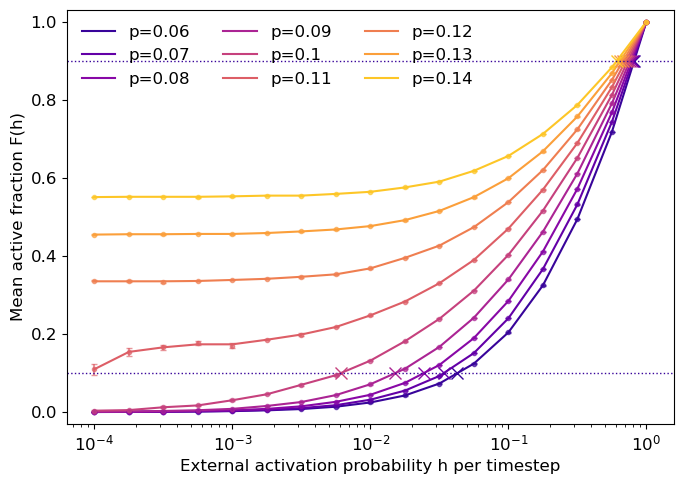

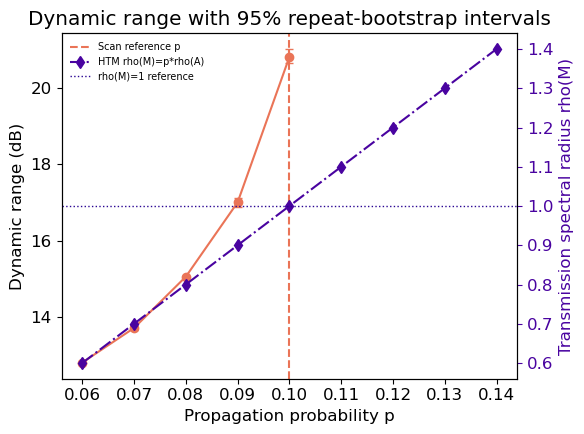

   p  p_factor      h10      h90  delta_db   h10_status h90_status  isotonic_rmse  h10_ci95_low  h10_ci95_high  h90_ci95_low  h90_ci95_high  delta_db_ci95_low  delta_db_ci95_high  bootstrap_resolved_fraction  rho_mean  rho_std  rho_min  rho_max
0.06       0.6 0.042765 0.815548 12.803607     resolved   resolved       0.000000      0.042654       0.042888      0.815259       0.815910          12.792538           12.814671                        1.000       0.6      0.0      0.6      0.6
0.07       0.7 0.034011 0.799109 13.709852     resolved   resolved       0.000000      0.033606       0.034351      0.798710       0.799752          13.669915           13.760850                        1.000       0.7      0.0      0.7      0.7
0.08       0.8 0.024385 0.780563 15.052814     resolved   resolved       0.000000      0.024239       0.024526      0.779920       0.781120          15.025766           15.078418                        1.000       0.8      0.0      0.8      0.8
0.09       0.9 0.015

In [40]:
dr_result = run_dynamic_range(
    G, p_factors=dr_p_factors, p_reference=dr_p_reference,
    h_values=dr_h_values, n_repeats=dr_n_repeats, burn_in=dr_burn_in,
    steps=dr_steps, n_blocks=dr_n_blocks, n_bootstrap=dr_n_bootstrap,
    seed=dr_seed, output_dir=dr_output_dir,
)
plot_dynamic_range(dr_result, dr_output_dir/'dynamic_range.png')
print(dr_result['summary'].to_string(index=False))
print('Actual transmission rho(M), separately for every p and repeat:')
print(dr_result['spectrum_by_repeat'].to_string(index=False))
print('Zero-drive runs initialized fully active (finite-time persistence diagnostic):')
print(dr_result['active_start_baseline'].groupby('p')[['F', 'final_activity', 'drift_flag']].mean().to_string())
print('First/last-half drift flags by p:')
print(dr_result['trials'].groupby('p')['drift_flag'].mean().to_string())
print('Saved response curves, trajectory diagnostics, bootstrap samples, environments, and topology to:',
      dr_output_dir.resolve())
print('Inspect low-h sampling and equilibration; repeat with longer runs and independent networks. '
      'HTM uses M=p*A; the initial p reference and spectral proxy are reported separately.')


### per-p positive-drive minimum or low-drive baseline

In [41]:
def _dr_plateau_fit(h, response):
    """Raw positive-drive minimum; monotone positive-drive fit for crossings only."""
    from sklearn.isotonic import IsotonicRegression
    h, response = np.asarray(h, dtype=float), np.asarray(response, dtype=float)
    if (h.ndim != 1 or response.shape != h.shape or h.size < 2
            or not np.all(np.isfinite(h)) or not np.all(np.isfinite(response))
            or np.any(np.diff(h) <= 0) or np.any((h < 0) | (h > 1))
            or np.any((response < 0) | (response > 1))):
        raise ValueError('Require increasing h in [0,1] and finite response fractions in [0,1].')
    positive = h > 0
    xx, yy = h[positive], response[positive]
    if xx.size < 2:
        raise ValueError('At least two positive drives are required.')
    Fmin = float(yy.min())
    fitted_positive = IsotonicRegression(increasing=True, y_min=0, y_max=1).fit_transform(xx, yy)
    fitted = np.full(h.shape, np.nan)  # h=0 is excluded from this fit and minimum.
    fitted[positive] = fitted_positive
    span = 1-Fmin
    estimate = dict(F_min=Fmin, F_max=1., F10=Fmin+.1*span, F90=Fmin+.9*span,
                    low_drive_range=float(np.ptp(yy[:min(3, yy.size)])),
                    isotonic_rmse=float(np.sqrt(np.mean((fitted_positive-yy)**2))))

    def crossing(target):
        if span <= 0:
            return np.nan, 'no_response_span'
        if target < fitted_positive[0]:
            return np.nan, 'below_h_grid'
        reached = np.flatnonzero(fitted_positive >= target)
        if not reached.size:
            return np.nan, 'above_h_grid'
        k = int(reached[0])
        if fitted_positive[k] == target:
            return float(xx[k]), 'resolved'
        if k == 0:
            return np.nan, 'below_h_grid'
        fraction = (target-fitted_positive[k-1])/(fitted_positive[k]-fitted_positive[k-1])
        return float(10**(np.log10(xx[k-1])+fraction*np.log10(xx[k]/xx[k-1]))), 'resolved'

    for key, level in [('h10', 'F10'), ('h90', 'F90')]:
        estimate[key], estimate[key+'_status'] = crossing(estimate[level])
    estimate['delta_db'] = (float(10*np.log10(estimate['h90']/estimate['h10']))
                            if np.isfinite(estimate['h10']) and np.isfinite(estimate['h90']) else np.nan)
    return fitted, estimate


def analyze_dynamic_range_plateau(result, output_dir=None, n_bootstrap=500, seed=41):
    """Additional analysis of existing trajectories; never modifies result or reruns dynamics."""
    from pathlib import Path
    import json
    import warnings
    if result.get('transmission_rule') != 'homogeneous_no_similarity':
        raise ValueError('Rerun HTM dynamic range: old similarity-driven responses cannot be reused as HTM data.')
    response = np.asarray(result['response'], dtype=float)
    h, ps = np.asarray(result['h'], dtype=float), np.asarray(result['p_values'], dtype=float)
    if (response.ndim != 3 or response.shape[0] != len(ps)
            or response.shape[2] != len(h) or response.shape[1] < 3):
        raise ValueError('Require response[p, repeat, h] with at least three independent repeats.')
    repeats = response.shape[1]
    if 'bootstrap_repeat_indices' in result:
        indices = np.asarray(result['bootstrap_repeat_indices'])
        if (indices.ndim != 2 or indices.shape[0] < 20 or indices.shape[1] != repeats
                or not np.issubdtype(indices.dtype, np.integer)
                or np.any((indices < 0) | (indices >= repeats))):
            raise ValueError('Invalid existing bootstrap repeat indices.')
    else:
        if int(n_bootstrap) != n_bootstrap or n_bootstrap < 20:
            raise ValueError('n_bootstrap must be an integer >=20.')
        indices = np.random.default_rng(seed).integers(repeats, size=(int(n_bootstrap), repeats))
    columns = ['F_min', 'F10', 'F90', 'h10', 'h90', 'delta_db']
    bootstrap = np.full((len(indices), len(ps), len(columns)), np.nan)
    summary, curves = [], []
    for i, p in enumerate(ps):
        mean = response[i].mean(axis=0)
        se = response[i].std(axis=0, ddof=1)/np.sqrt(repeats)
        fitted, estimate = _dr_plateau_fit(h, mean)
        for b, selected in enumerate(indices):
            _, sample = _dr_plateau_fit(h, response[i, selected].mean(axis=0))
            bootstrap[b, i] = [sample[key] for key in columns]
        resolved = np.all(np.isfinite(bootstrap[:, i, 3:]), axis=1)
        coverage = float(resolved.mean())
        for k, key in enumerate(columns):
            usable = np.ones(len(indices), dtype=bool) if k < 3 else resolved
            if (k < 3 or coverage >= .95) and np.isfinite(estimate[key]):
                low, high = np.quantile(bootstrap[usable, i, k], [.025, .975])
            else:
                low, high = np.nan, np.nan
            estimate[key+'_ci95_low'], estimate[key+'_ci95_high'] = low, high
        summary.append(dict(p=p, **estimate, bootstrap_resolved_fraction=coverage))
        for j, hh in enumerate(h):
            curves.append(dict(p=p, h=hh, F_mean=mean[j], F_se=se[j], F_isotonic=fitted[j]))
    analyzed = dict(summary=pd.DataFrame(summary), curves=pd.DataFrame(curves),
                    bootstrap=bootstrap, bootstrap_columns=columns,
                    bootstrap_repeat_indices=indices.copy(),
                    pc_reference=result.get('pc_reference'), p_reference=result.get('p_reference'),
                    pc_proxy=result.get('pc_proxy'), transmission_rule='homogeneous_no_similarity',
                    reference_is_proxy=result.get('reference_is_proxy', True),
                    original_summary=result['summary'].copy(deep=True))
    if 'spectrum_by_repeat' in result:
        analyzed['spectrum_by_repeat'] = result['spectrum_by_repeat'].copy(deep=True)
        analyzed['spectrum_summary'] = result['spectrum_summary'].copy(deep=True)
        analyzed['summary'] = analyzed['summary'].merge(
            analyzed['spectrum_summary'], on='p', how='left', validate='one_to_one')
        analyzed['rho_values'] = np.asarray(result['rho_values']).copy()
    if output_dir is not None:
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        if 'spectrum_by_repeat' in analyzed:
            analyzed['spectrum_by_repeat'].to_csv(out/'dynamic_range_spectrum_by_repeat.csv', index=False)
            analyzed['spectrum_summary'].to_csv(out/'dynamic_range_spectrum_summary.csv', index=False)
        analyzed['summary'].to_csv(out/'dynamic_range_plateau_summary.csv', index=False)
        analyzed['curves'].to_csv(out/'dynamic_range_plateau_curves.csv', index=False)
        analyzed['original_summary'].to_csv(out/'dynamic_range_original_summary.csv', index=False)
        np.savez_compressed(out/'dynamic_range_plateau_data.npz', bootstrap=bootstrap,
                            bootstrap_columns=np.asarray(columns), bootstrap_repeat_indices=indices,
                            response=response, h=h, p_values=ps)
        settings = dict(baseline='minimum raw repeat-mean response over measured h>0',
                        F_max=1., interpolation='linear response versus log10(h), positive drives only',
                        n_bootstrap=len(indices), n_repeats=repeats,
                        paired_with_original='bootstrap_repeat_indices' in result,
                        source_settings=result.get('settings', {}))
        (out/'dynamic_range_plateau_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
    if not np.all(np.isfinite(analyzed['summary']['delta_db'])):
        warnings.warn('Some plateau dynamic ranges are unresolved; inspect crossing statuses and response span.')
    return analyzed


def plot_dynamic_range_plateau(result, fname=None):
    """Two independent figures; show each p's own baseline and threshold locations."""
    from pathlib import Path
    cmap = plt.get_cmap('plasma')
    fig_response, ax = plt.subplots(figsize=(7, 5))
    ax.set_prop_cycle(color=cmap(np.linspace(.08, .88, result['curves']['p'].nunique())))
    for p, curve in result['curves'].groupby('p', sort=True):
        positive = curve.query('h > 0')
        line, = ax.plot(positive['h'], positive['F_isotonic'], label=f'p={p:.4g}')
        ax.errorbar(positive['h'], positive['F_mean'], yerr=positive['F_se'],
                    fmt='o', ms=3, capsize=2, color=line.get_color(), alpha=.65)
        row = result['summary'].loc[result['summary']['p'] == p].iloc[0]
        ax.hlines(row['F_min'], positive['h'].min(), positive['h'].max(),
                  color=line.get_color(), linestyle=':', alpha=.35)
        for key, level in [('h10', 'F10'), ('h90', 'F90')]:
            if np.isfinite(row[key]):
                ax.plot(row[key], row[level], 'x', ms=8, color=line.get_color())
    ax.set(xscale='log', xlabel='External activation probability h per timestep',
           ylabel='Mean active fraction F(h)', ylim=(-.03, 1.03))
           # title='Low-drive baseline (dotted); F10 and F90 crossings (x)')
    ax.legend(fontsize=8,frameon=False,loc='upper left', ncol=3)
    fig_response.tight_layout()
    fig_delta, ax_delta = plt.subplots(figsize=(6, 4.5))
    primary_color = cmap(.65)
    original = result['original_summary'].sort_values('p')

    ax_delta.plot(original['p'], original['delta_db'], 's--', color=cmap(.25), label='Absorbing baseline')
    summary = result['summary'].sort_values('p')
    ax_delta.plot(summary['p'], summary['delta_db'], 'o-', color=primary_color, label='Low-drive baseline')
    for row in summary.itertuples():
        if np.isfinite(row.delta_db_ci95_low) and np.isfinite(row.delta_db_ci95_high):
            ax_delta.vlines(row.p, row.delta_db_ci95_low, row.delta_db_ci95_high, color=primary_color)
            ax_delta.plot([row.p, row.p], [row.delta_db_ci95_low, row.delta_db_ci95_high], '_', color=primary_color)
    pc = result.get('pc_reference')
    if pc is not None and np.isfinite(pc):
        label = 'Scan reference p'
        ax_delta.axvline(pc, color=cmap(.9), linestyle='--', label=label)
    proxy = result.get('pc_proxy', np.nan)
    if proxy is not None and np.isfinite(proxy) and (pc is None or not np.isclose(proxy, pc)):
        ax_delta.axvline(proxy, color=cmap(.3), linestyle=':', label='HTM spectral proxy 1/rho(A)')
    ax_delta.set(xlabel='Propagation probability p', ylabel='Dynamic range (dB)')
                #  title='Low-drive baseline dynamic range: 95% bootstrap CI')
    ax_delta.legend(frameon=False)
    _plot_dynamic_range_spectrum(ax_delta, result)
    fig_delta.tight_layout()
    if fname is not None:
        path = Path(fname)
        path.parent.mkdir(parents=True, exist_ok=True)
        suffix = path.suffix or '.png'
        fig_response.savefig(path.with_name(path.stem+'_response'+suffix), dpi=200, bbox_inches='tight')
        fig_delta.savefig(path.with_name(path.stem+'_delta'+suffix), dpi=200, bbox_inches='tight')
    plt.show()
    return fig_response, fig_delta


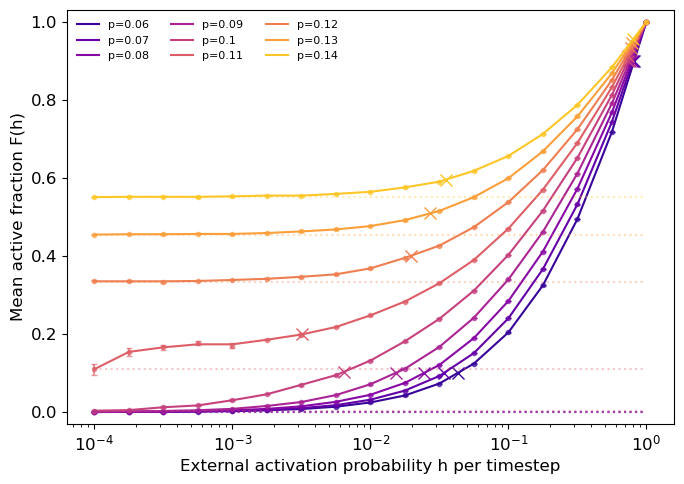

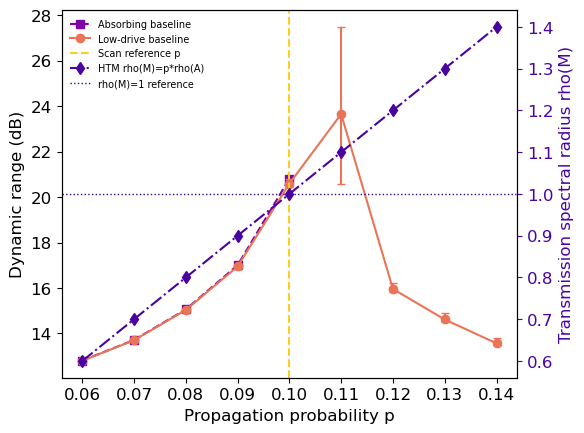

   p    F_min      F10      F90      h10      h90  delta_db  delta_db_ci95_low  delta_db_ci95_high  bootstrap_resolved_fraction h10_status h90_status  low_drive_range
0.06 0.000205 0.100184 0.900020 0.042854 0.815582 12.794766          12.784488           12.805040                          1.0   resolved   resolved         0.000582
0.07 0.000315 0.100284 0.900032 0.034106 0.799165 13.698052          13.657938           13.748752                          1.0   resolved   resolved         0.000812
0.08 0.000466 0.100420 0.900047 0.024514 0.780653 15.030454          14.999623           15.060849                          1.0   resolved   resolved         0.000879
0.09 0.000963 0.100867 0.900096 0.015351 0.759668 16.944780          16.848713           17.065555                          1.0   resolved   resolved         0.001954
0.10 0.003640 0.103276 0.900364 0.006428 0.736459 20.590867          20.437590           20.796532                          1.0   resolved   resolved         0.00877

In [42]:
# Run after an existing dynamic-range simulation has produced dr_result.
# Reuses the same trajectories and bootstrap repeat indices; no additional propagation.
from pathlib import Path
dr_plateau_output_dir = Path(dr_output_dir)/'per_p_positive_drive_baseline'
dr_plateau_result = analyze_dynamic_range_plateau(dr_result, output_dir=dr_plateau_output_dir)
plot_dynamic_range_plateau(dr_plateau_result, dr_plateau_output_dir/'dynamic_range_plateau.png')
print(dr_plateau_result['summary'][[
    'p', 'F_min', 'F10', 'F90', 'h10', 'h90', 'delta_db',
    'delta_db_ci95_low', 'delta_db_ci95_high', 'bootstrap_resolved_fraction',
    'h10_status', 'h90_status', 'low_drive_range',
]].to_string(index=False))
print('F_min is the minimum raw repeat-mean response over measured h>0; F_max=1.')
print('Inspect low_drive_range and the original trajectory diagnostics before interpreting a plateau.')
print('Additional analysis saved to:', dr_plateau_output_dir.resolve())

if 'spectrum_summary' in dr_plateau_result:
    print('Transmission spectral radii associated with these low-drive curves:')
    print(dr_plateau_result['spectrum_summary'].to_string(index=False))


## Finite-size scaling (FSS): main model

In [45]:
from pathlib import Path


def load_fss_data(data_dir, sizes, mode, burn_in=2000,
                  filename_template='avalanches_{mode}_{V}.csv'):
    """Load main-model summaries from one directory, with the reference burn-in rule."""
    requested = np.asarray(sizes, dtype=float)
    if (requested.ndim != 1 or requested.size < 3 or not np.all(np.isfinite(requested))
            or np.any(requested != np.floor(requested)) or np.any(requested <= 0)
            or len(set(requested)) != requested.size):
        raise ValueError('Need at least three distinct positive integer network sizes.')
    sizes = requested.astype(int)
    if int(burn_in) != burn_in or burn_in < 0:
        raise ValueError('burn_in must be a nonnegative number of avalanche records.')
    paths = {int(v): Path(data_dir)/filename_template.format(mode=mode, V=int(v))
             for v in sorted(sizes)}
    if len({p.resolve() for p in paths.values()}) != len(paths):
        raise ValueError('filename_template must identify a distinct file per V (use {V}).')
    missing = [str(p) for p in paths.values() if not p.is_file()]
    if missing:
        raise FileNotFoundError('Missing main FSS summaries; set fss_data_dir/fss_sizes explicitly. '
                                'Directories/model phases are never mixed: ' + ', '.join(missing))
    datasets, rows = {}, []
    for v, file in paths.items():
        frame = pd.read_csv(file)
        if not {'size', 'duration'}.issubset(frame.columns):
            raise ValueError(f'{file.name}: expected avalanche-summary columns size,duration.')
        if {'t', 'activity'}.issubset(frame.columns):
            raise ValueError(f'{file.name}: detailed timestep data are not avalanche summaries.')
        values = frame[['size', 'duration']].to_numpy(dtype=float)
        if (not np.all(np.isfinite(values) & (values > 0))
                or not np.all(values == np.floor(values)) or np.any(values[:, 0] < values[:, 1])):
            raise ValueError(f'{file.name}: invalid avalanche size/duration pairs.')
        retained = frame.iloc[int(burn_in):][['size', 'duration']].reset_index(drop=True)
        if len(retained) < 100:
            raise ValueError(f'{file.name}: fewer than 100 avalanches after burn-in.')
        datasets[v] = retained
        row = dict(V=v, model='main', file=str(file.resolve()), n_raw=len(frame),
                   burn_in_records=int(burn_in), n_retained=len(retained))
        for observable in ('size', 'duration'):
            x = retained[observable].to_numpy(dtype=float)
            row.update({f'{observable}_mean': x.mean(), f'{observable}_median': np.median(x),
                        f'{observable}_q99': np.quantile(x, .99), f'{observable}_max': x.max(),
                        f'{observable}_late_early_mean_ratio': x[len(x)//2:].mean()/x[:len(x)//2].mean()})
        rows.append(row)
    return datasets, pd.DataFrame(rows)


def fss_histograms(datasets, nbins=45):
    """Common integer-aligned bin edges across all V; PDF units include bin width."""
    rows = []
    for observable in ('size', 'duration'):
        lo = min(frame[observable].min() for frame in datasets.values())
        hi = max(frame[observable].max() for frame in datasets.values())
        grid = np.floor(np.geomspace(lo, hi + 1, nbins + 1))
        grid[0], grid[-1] = lo, hi + 1
        edges = np.unique(grid) - .5
        widths = np.diff(edges)
        centers = np.sqrt(edges[:-1] * edges[1:])
        for v, frame in datasets.items():
            counts, _ = np.histogram(frame[observable], bins=edges)
            for x, width, count in zip(centers, widths, counts):
                rows.append(dict(V=v, observable=observable, x=x, width=width,
                                 count=count, pdf=count / (len(frame) * width)))
    return pd.DataFrame(rows)


def fss_ccdf(x):
    values, counts = np.unique(np.asarray(x), return_counts=True)
    tail_count = np.cumsum(counts[::-1])[::-1]
    return values, tail_count / tail_count[0], tail_count


def fss_moment_fit(log_moments, sizes, orders, fit_q_min=2):
    """<X^q> ~ V^mu(q); mu(q)=kappa*(q+1-exponent), q>exponent-1.

    log_moments has shape (number of V, 2 observables, number of q).
    kappa is relative to NODE COUNT V, not to an assumed spatial length.
    """
    log_v = np.log(np.asarray(sizes, dtype=float))
    q = np.asarray(orders, dtype=float)
    use = q >= fit_q_min
    if use.sum() < 2:
        raise ValueError('Need at least two fitted moment orders.')
    centered_v = log_v - log_v.mean()
    mu = np.einsum('v,voq->oq', centered_v, log_moments) / np.dot(centered_v, centered_v)
    intercept_v = log_moments.mean(axis=0) - mu * log_v.mean()
    fitted = log_v[:, None, None] * mu + intercept_v
    total = np.sum((log_moments - log_moments.mean(axis=0))**2, axis=0)
    r2 = np.full_like(total, np.nan)
    np.divide(np.sum((log_moments - fitted)**2, axis=0), total, out=r2, where=total > 0)
    r2 = 1 - r2
    centered_q = q[use] - q[use].mean()
    kappa = np.einsum('q,oq->o', centered_q, mu[:, use]) / np.dot(centered_q, centered_q)
    intercept_q = mu[:, use].mean(axis=1) - kappa * q[use].mean()
    exponent = np.full(2, np.nan)
    np.divide(intercept_q, kappa, out=exponent, where=np.abs(kappa) > 1e-10)
    exponent = 1 - exponent
    return dict(mu=mu, intercept_v=intercept_v, r2=r2,
                kappa=kappa, exponent=exponent, intercept_q=intercept_q)


def fss_moments_bootstrap(datasets, orders=(1, 2, 3, 4), fit_q_min=2,
                          n_boot=500, seed=13, block_length=1):
    """Paired size/duration bootstrap within each V, conditional on these runs.

    block_length>1 uses circular contiguous avalanche blocks. This does not
    substitute for independent network realizations or remove tuning drift.
    Normalized powers avoid overflow; the normalization cancels analytically.
    """
    if int(n_boot) != n_boot or n_boot < 2:
        raise ValueError('n_boot must be an integer >= 2.')
    if int(block_length) != block_length or block_length < 1:
        raise ValueError('block_length must be a positive integer.')
    sizes = np.array(sorted(datasets), dtype=int)
    orders = np.asarray(orders, dtype=float)
    if np.any(orders <= 0) or not np.all(np.isfinite(orders)) or np.any(np.diff(orders) <= 0):
        raise ValueError('Moment orders must be finite, positive and increasing.')
    rng = np.random.default_rng(seed)
    logs = np.empty((len(sizes), 2, len(orders)))
    bootstrap_logs = np.empty((int(n_boot),) + logs.shape)
    top1_fraction = np.empty_like(logs)
    top10_fraction = np.empty_like(logs)
    for j, v in enumerate(sizes):
        x = datasets[v][['size', 'duration']].to_numpy(dtype=float)
        if block_length > len(x):
            raise ValueError('Bootstrap block length exceeds retained sample size.')
        scale = x.max(axis=0)
        powers = (x[:, :, None] / scale[None, :, None])**orders[None, None, :]
        offset = np.log(scale)[:, None] * orders
        total_power = powers.sum(axis=0)
        top1_fraction[j] = powers.max(axis=0) / total_power
        tail_n = min(10, len(x))
        top10_fraction[j] = np.partition(powers, -tail_n, axis=0)[-tail_n:].sum(axis=0) / total_power
        logs[j] = np.log(powers.mean(axis=0)) + offset
        for b in range(int(n_boot)):
            if block_length == 1:
                indices = rng.integers(0, len(x), size=len(x))
            else:
                starts = rng.integers(0, len(x), size=(len(x) + block_length - 1)//block_length)
                indices = ((starts[:, None] + np.arange(block_length)) % len(x)).ravel()[:len(x)]
            bootstrap_logs[b, j] = np.log(powers[indices].mean(axis=0)) + offset
    point = fss_moment_fit(logs, sizes, orders, fit_q_min)
    bootstrap_fits = [fss_moment_fit(sample, sizes, orders, fit_q_min) for sample in bootstrap_logs]
    return dict(sizes=sizes, orders=orders, log_moments=logs, point=point,
                bootstrap_log_moments=bootstrap_logs,
                bootstrap_mu=np.array([f['mu'] for f in bootstrap_fits]),
                bootstrap_kappa=np.array([f['kappa'] for f in bootstrap_fits]),
                bootstrap_exponent=np.array([f['exponent'] for f in bootstrap_fits]),
                fit_q_min=fit_q_min, n_boot=int(n_boot), seed=seed, block_length=block_length,
                top1_moment_fraction=top1_fraction, top10_moment_fraction=top10_fraction)


def fss_summarize(result):
    """Export conditional uncertainty and a smallest-V exclusion sensitivity check."""
    rows, moment_rows, slope_rows, draws = [], [], [], []
    point = result['point']
    sizes, orders = result['sizes'], result['orders']
    reduced = (fss_moment_fit(result['log_moments'][1:], sizes[1:], orders, result['fit_q_min'])
               if len(sizes) >= 4 else None)
    for o, observable in enumerate(('size', 'duration')):
        for name, value, samples in (
            ('kappa', point['kappa'][o], result['bootstrap_kappa'][:, o]),
            ('tau' if o == 0 else 'alpha', point['exponent'][o], result['bootstrap_exponent'][:, o]),
        ):
            finite = samples[np.isfinite(samples)]
            ci = np.percentile(finite, [2.5, 97.5]) if len(finite) else [np.nan, np.nan]
            reduced_value = (reduced['kappa'][o] if name == 'kappa' else reduced['exponent'][o]) if reduced else np.nan
            rows.append(dict(observable=observable, parameter=name, estimate=value,
                             bootstrap_std=finite.std(ddof=1) if len(finite) > 1 else np.nan,
                             ci95_low=ci[0], ci95_high=ci[1], n_valid=len(finite),
                             exclude_smallest_V_estimate=reduced_value))
        for j, v in enumerate(sizes):
            for k, q in enumerate(orders):
                moment_rows.append(dict(V=v, observable=observable, q=q,
                                        moment=np.exp(result['log_moments'][j, o, k]),
                                        top1_moment_fraction=result['top1_moment_fraction'][j, o, k],
                                        top10_moment_fraction=result['top10_moment_fraction'][j, o, k]))
        for k, q in enumerate(orders):
            slope_rows.append(dict(observable=observable, q=q, mu=point['mu'][o, k],
                                   bootstrap_std=result['bootstrap_mu'][:, o, k].std(ddof=1),
                                   log_moment_vs_log_V_R2=point['r2'][o, k],
                                   used_for_exponent_fit=bool(q >= result['fit_q_min'])))
    for b, (kappa, exponent) in enumerate(zip(result['bootstrap_kappa'], result['bootstrap_exponent'])):
        gamma_cutoff = kappa[0]/kappa[1] if np.all(kappa > 0) else np.nan
        gamma_exponents = ((exponent[1]-1)/(exponent[0]-1)
                           if np.all(exponent > 1) and np.all(kappa > 0) else np.nan)
        draws.append(dict(replicate=b, kappa_size=kappa[0], kappa_duration=kappa[1],
                          tau=exponent[0], alpha=exponent[1],
                          gamma_cutoff=gamma_cutoff, gamma_exponents=gamma_exponents))
    return pd.DataFrame(rows), pd.DataFrame(moment_rows), pd.DataFrame(slope_rows), pd.DataFrame(draws)


def plot_fss_distributions(datasets, histograms, colors, fname):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), dpi=120)
    for o, observable in enumerate(('size', 'duration')):
        for v, frame in datasets.items():
            h = histograms.query('V == @v and observable == @observable and count > 0')
            axes[0, o].loglog(h['x'], h['pdf'], 'o-', markersize=3, linewidth=1,
                              color=colors[v], label=f'V={v}, n={len(frame)}')
            x, survival, _ = fss_ccdf(frame[observable])
            axes[1, o].loglog(x, survival, color=colors[v], label=f'V={v}')
        axes[0, o].set_title(f'{observable}: common-bin PDF')
        axes[0, o].set_ylabel('Probability density')
        axes[1, o].set_title(f'{observable}: empirical CCDF (no bins)')
        axes[1, o].set_ylabel('Pr(X >= x)')
        for panel in axes[:, o]:
            panel.set_xlabel(observable)
            panel.grid(alpha=.2)
            panel.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


def plot_fss_moments(result, fname):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), dpi=120)
    for panel in axes.flat:
        panel.set_prop_cycle(color=plt.cm.plasma(np.linspace(.1, .85, len(result['orders']))))
    sizes, orders, point = result['sizes'], result['orders'], result['point']
    for o, observable in enumerate(('size', 'duration')):
        for k, q in enumerate(orders):
            axes[o, 0].loglog(sizes, np.exp(result['log_moments'][:, o, k]), 'o-', label=f'q={q:g}')
        axes[o, 1].errorbar(orders, point['mu'][o],
                             yerr=result['bootstrap_mu'][:, o].std(axis=0, ddof=1),
                             fmt='o', capsize=3, color=plt.cm.plasma(.2), label='Moment slopes +/- bootstrap SD')
        qline = np.linspace(orders.min(), orders.max(), 100)
        axes[o, 1].plot(qline, point['kappa'][o]*qline+point['intercept_q'][o], '--', color=plt.cm.plasma(.75),
                        label=f"q >= {result['fit_q_min']}: kappa={point['kappa'][o]:.3f}, exponent={point['exponent'][o]:.3f}")
        axes[o, 0].set(xlabel='Network size V (nodes)', ylabel='<X^q>', title=f'{observable}: moment growth')
        axes[o, 1].set(xlabel='Moment order q', ylabel='mu(q)', title=f'{observable}: mu(q) = kappa (q+1-exponent)')
        for panel in axes[o]:
            panel.grid(alpha=.2)
            panel.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


def plot_fss_cutoffs(datasets, result, fname):
    """Moment ratios are cutoff proxies, not sample maxima or fitted hard cutoffs."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=120)
    rows = []
    for o, observable in enumerate(('size', 'duration')):
        for k in range(len(result['orders'])-1):
            q = result['orders'][k]
            if not np.isclose(result['orders'][k+1]-q, 1):
                continue
            ratio = np.exp(result['log_moments'][:, o, k+1]-result['log_moments'][:, o, k])
            samples = np.exp(result['bootstrap_log_moments'][:, :, o, k+1]-result['bootstrap_log_moments'][:, :, o, k])
            low, high = np.percentile(samples, [2.5, 97.5], axis=0)
            axes[o].loglog(result['sizes'], ratio, 'o-', color=plt.cm.plasma(.15+.65*k/max(1, len(result['orders'])-2)), label=f'<X^{q+1:g}>/<X^{q:g}>')
            axes[o].fill_between(result['sizes'], low, high, color=plt.cm.plasma(.15+.65*k/max(1, len(result['orders'])-2)), alpha=.12)
            slope = result['point']['mu'][o, k+1]-result['point']['mu'][o, k]
            for j, v in enumerate(result['sizes']):
                rows.append(dict(V=v, observable=observable, q=q, moment_ratio=ratio[j],
                                 ci95_low=low[j], ci95_high=high[j], ratio_scaling_exponent=slope))
        axes[o].loglog(result['sizes'], [datasets[v][observable].quantile(.99) for v in result['sizes']],
                       's--', color=plt.cm.plasma(.95), label='99th percentile (diagnostic only)')
        axes[o].set(xlabel='Network size V (nodes)', ylabel='Characteristic scale', title=f'{observable}: tail-scale diagnostics')
        axes[o].grid(alpha=.2)
        axes[o].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rows)


def plot_fss_collapse(datasets, histograms, result, colors, reference_V, min_x, min_tail_count, fname):
    """Use moment-derived exponents; do not optimize them to make curves overlap."""
    import warnings
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), dpi=120)
    rows = []
    for o, observable in enumerate(('size', 'duration')):
        kappa, exponent = result['point']['kappa'][o], result['point']['exponent'][o]
        if not np.isfinite(kappa+exponent) or kappa <= 0 or exponent <= 1:
            warnings.warn(f'{observable}: moment exponents outside simple FSS regime; collapse skipped.', stacklevel=2)
            for panel in axes[:, o]:
                panel.text(.05, .5, 'Moment estimate incompatible with\nkappa > 0 and exponent > 1', transform=panel.transAxes)
            continue
        for v, frame in datasets.items():
            r = v / reference_V
            h = histograms.query('V == @v and observable == @observable and count > 0')
            h = h[h['x'] >= min_x[observable]]
            axes[0, o].loglog(h['x']/r**kappa, h['pdf']*r**(kappa*exponent),
                              'o-', markersize=3, linewidth=1, color=colors[v], label=f'N={v}')
            x, ccdf, tail_count = fss_ccdf(frame[observable])
            mask = (x >= min_x[observable]) & (tail_count >= min_tail_count)
            xs, ys = x[mask]/r**kappa, ccdf[mask]*r**(kappa*(exponent-1))
            axes[1, o].loglog(xs, ys, color=colors[v], label=f'V={v}')
            for xv, yv in zip(xs, ys):
                rows.append(dict(V=v, observable=observable, scaled_x=xv, scaled_ccdf=yv,
                                 kappa=kappa, exponent=exponent))
        axes[0, o].set_title(f'{observable}: PDF collapse, kappa={kappa:.3f}, exponent={exponent:.3f}')
        axes[0, o].set_ylabel('r^(kappa * exponent) P(X; V)')
        axes[1, o].set_title(f'{observable}: CCDF collapse; at least {min_tail_count} tail events')
        axes[1, o].set_ylabel('r^[kappa * (exponent-1)] Pr(X >= x)')
        for panel in axes[:, o]:
            panel.set_xlabel('X / r^kappa; r = V / reference_V')
            panel.grid(alpha=.2)
            panel.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rows)


def plot_fss_time_stability(datasets, colors, fname, n_windows=10):
    """Ordered epoch means reveal drift and tail sampling fluctuations; no stationarity test."""
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=120)
    for v, frame in datasets.items():
        groups = np.array_split(np.arange(len(frame)), n_windows)
        for epoch, indices in enumerate(groups):
            part = frame.iloc[indices]
            rows.append(dict(V=v, epoch=epoch, retained_record_midpoint=float(indices.mean()),
                             n=len(part), mean_size=part['size'].mean(), mean_duration=part['duration'].mean()))
    table = pd.DataFrame(rows)
    for o, observable in enumerate(('size', 'duration')):
        for v in datasets:
            part = table[table['V'] == v]
            axes[o].semilogy(part['retained_record_midpoint'], part[f'mean_{observable}'], 'o-', color=colors[v], label=f'V={v}')
        axes[o].set(xlabel='Retained avalanche index', ylabel=f'Mean {observable}', title=f'{observable}: ordered-window stability')
        axes[o].grid(alpha=.2)
        axes[o].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()
    return table


In [43]:
# Same numerical FSS settings as the self-tuning reference; main-model inputs only.
from pathlib import Path
fss_sizes = [50, 100, 200,400,600]  # replace with actual simulated sizes; at least 3
fss_mode = 'no'
fss_burn_in = 2000  # first stored avalanche records; same rule for every V
fss_filename_template = 'avalanches_{mode}_{V}.csv'
fss_nbins = 50
fss_moment_orders = [1., 1.5, 2., 2.5, 3.]
fss_fit_q_min = 2.
fss_n_boot = 500
fss_seed = 13
fss_bootstrap_block_length = 1  # >1: circular contiguous avalanche blocks
fss_reference_V = 200
fss_collapse_min_x = {'size': 5, 'duration': 3}
fss_collapse_min_tail_count = 100
fss_condition_notes = ''  # document topology, degree, p, similarity rule, and any size-dependent tuning

# Explicit main-data folder; never search self-tuning folders or combine directories.
fss_notebook_candidates = [Path.cwd(), Path.cwd()/'01 independent oscillators/Code/submitted code',
                           Path.cwd()/'submitted code']
fss_notebook_dir = next((p for p in fss_notebook_candidates if (p/'main.ipynb').is_file()), Path.cwd())
fss_data_dir = fss_notebook_dir/'FSS_noST_tuned'  # change to your folder containing ALL summaries
fss_output_dir = fss_data_dir/f'fss_main_{fss_mode}'


FSS model=main; discard first 2000 stored avalanche records per V.
  V  n_raw  n_retained  size_q99  size_max  duration_q99  duration_max  size_late_early_mean_ratio  duration_late_early_mean_ratio
 50  10000        8000    299.00    1181.0         50.00         162.0                    0.970607                        0.980002
100  10000        8000    472.01    2057.0         63.00         150.0                    0.904931                        0.947863
200  10000        8000    789.02    2716.0         73.00         229.0                    1.111598                        1.056037
400  10000        8000   1161.03    4213.0         94.00         281.0                    1.161875                        1.069863
600  10000        8000   1429.19    4979.0        109.01         264.0                    0.865106                        0.945880


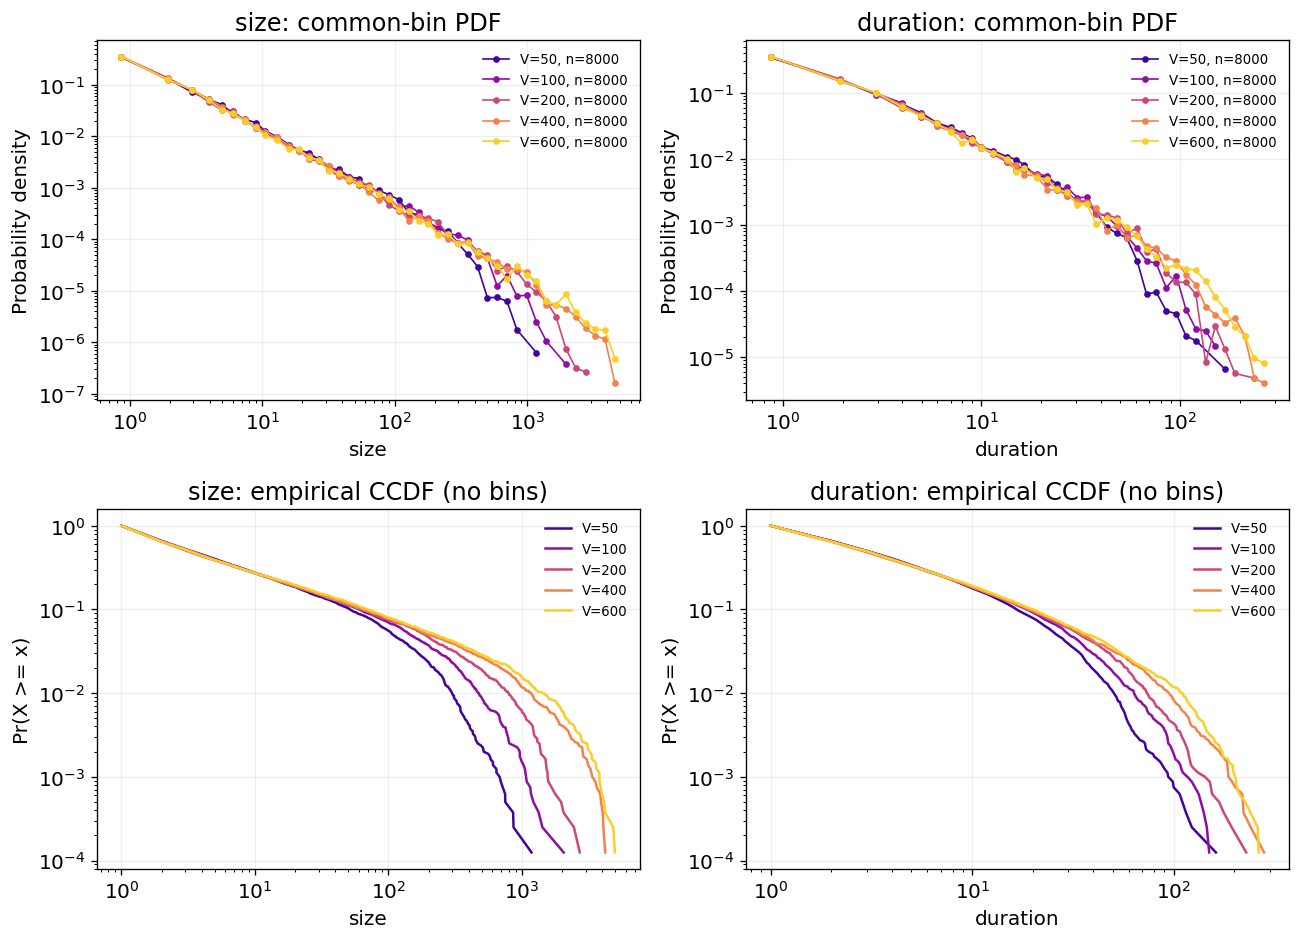

Moment-derived FSS parameters (conditional bootstrap uncertainty):
observable parameter  estimate  bootstrap_std  ci95_low  ci95_high  n_valid  exclude_smallest_V_estimate
      size     kappa  0.781475       0.040880  0.706199   0.863742      500                     0.767014
      size       tau  1.375452       0.064823  1.253672   1.500454      500                     1.363159
  duration     kappa  0.385265       0.031033  0.328063   0.445586      500                     0.390711
  duration     alpha  1.787473       0.070383  1.637002   1.910839      500                     1.833313
Check whether mu(q) is linear, and whether removing the smallest V changes the estimates:
observable   q       mu  bootstrap_std  log_moment_vs_log_V_R2  used_for_exponent_fit
      size 1.0 0.427970       0.022000                0.998819                  False
      size 1.5 0.848130       0.035096                0.997477                  False
      size 2.0 1.266169       0.048429                0.9962

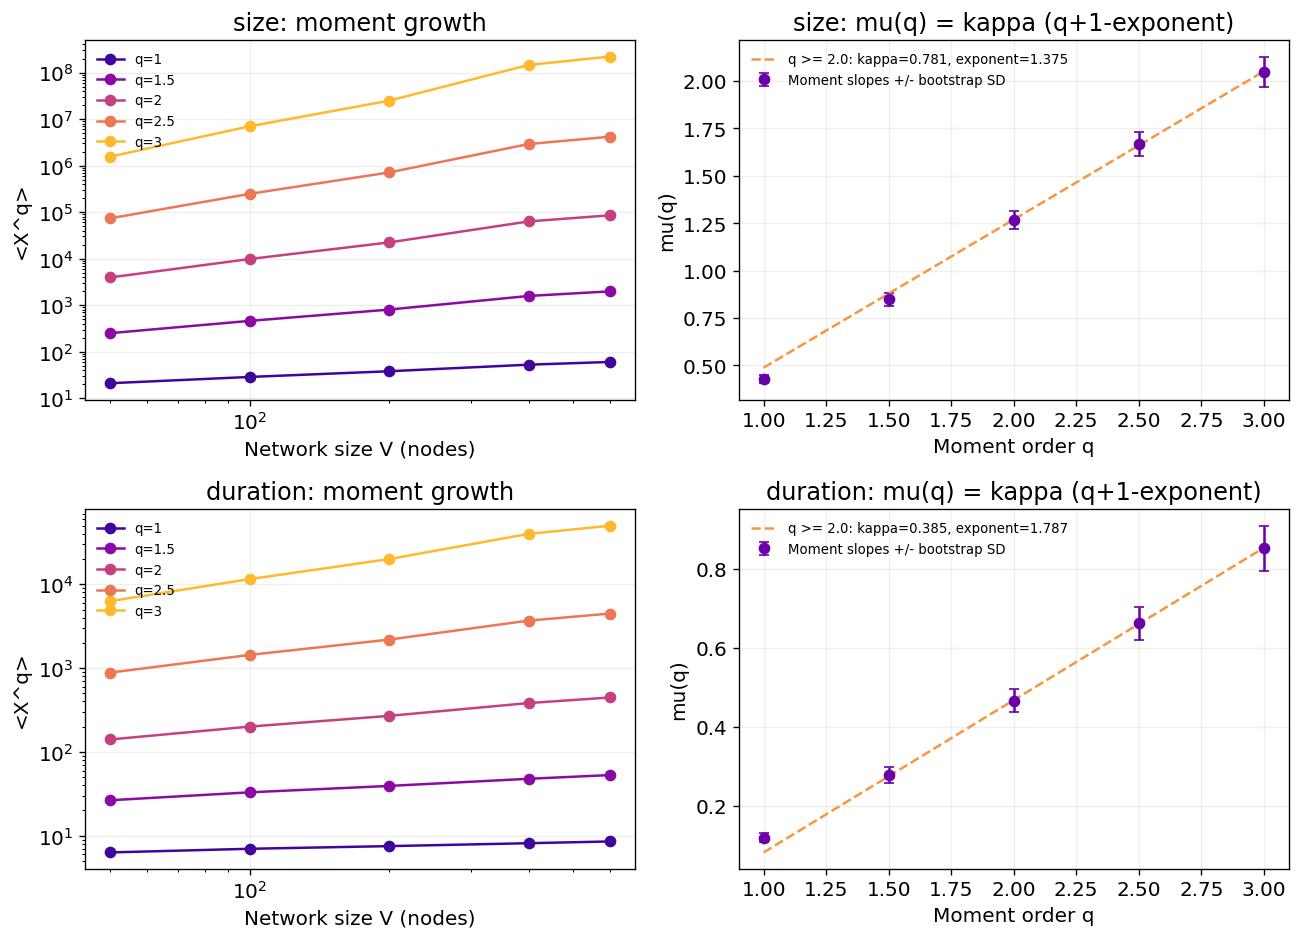

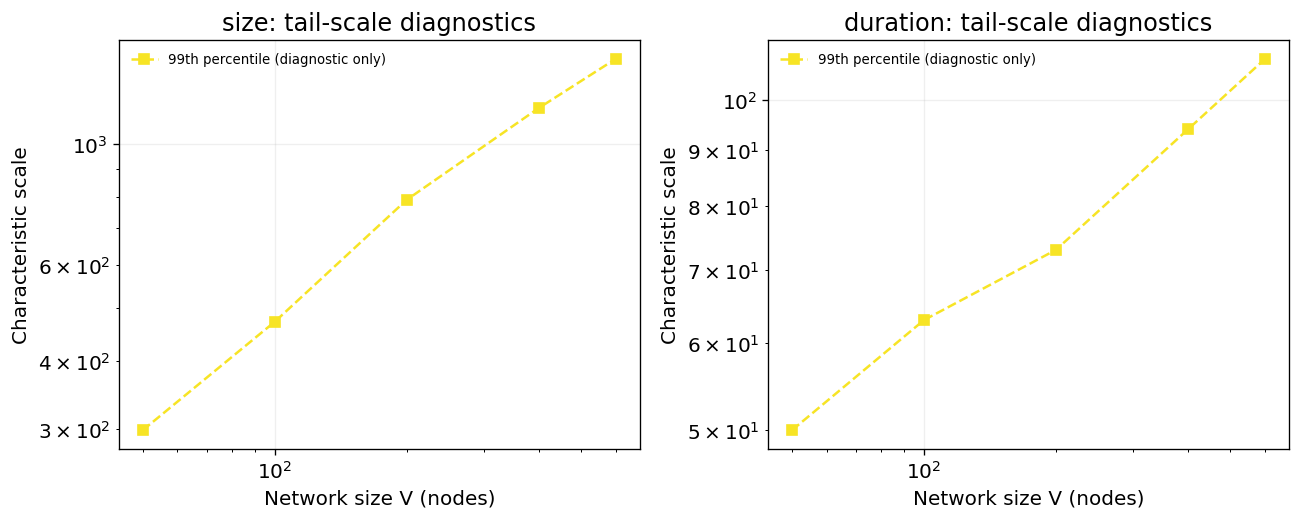

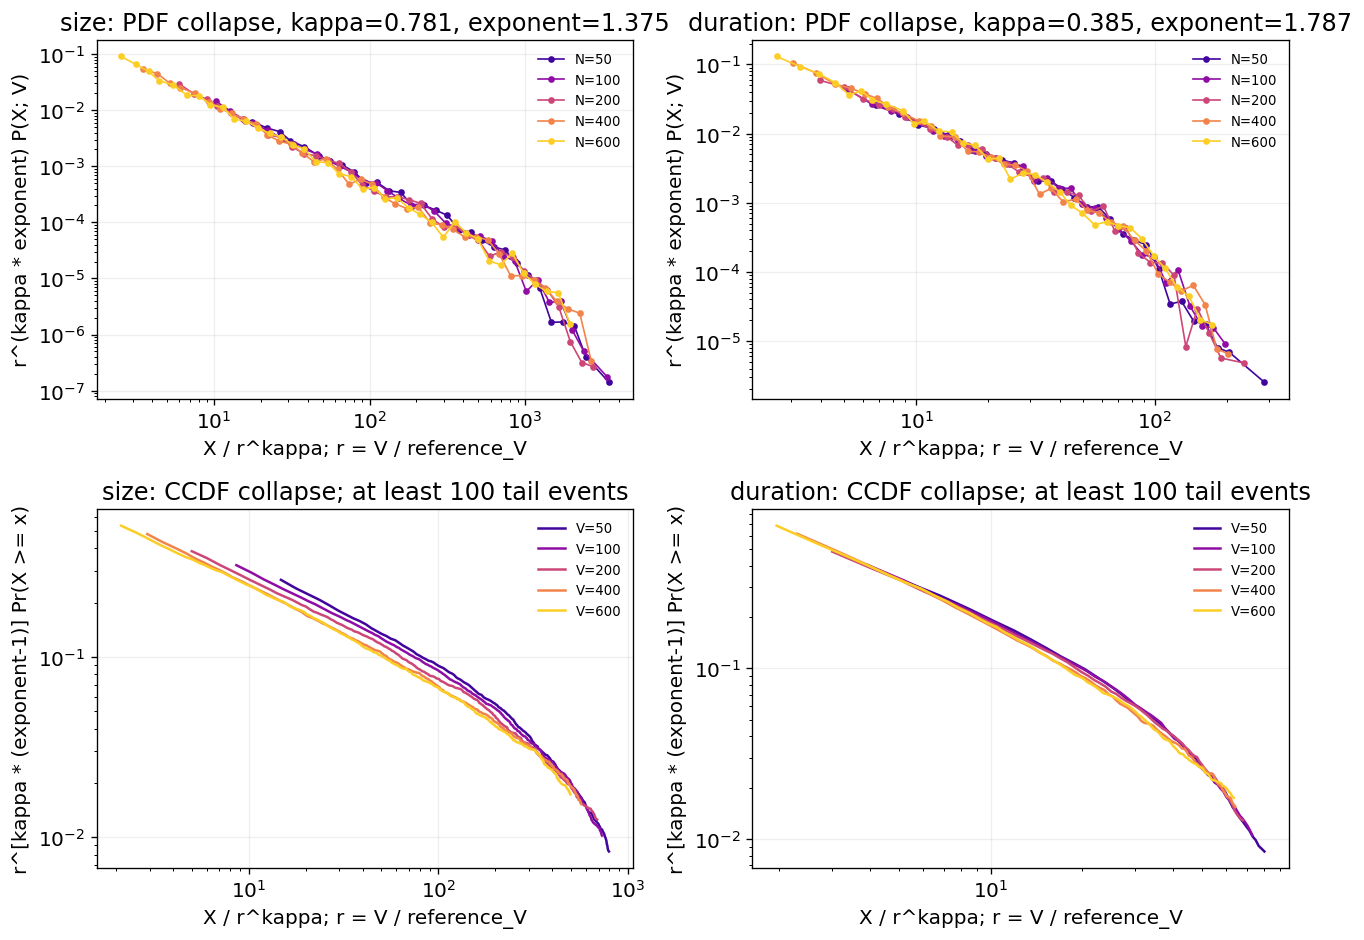

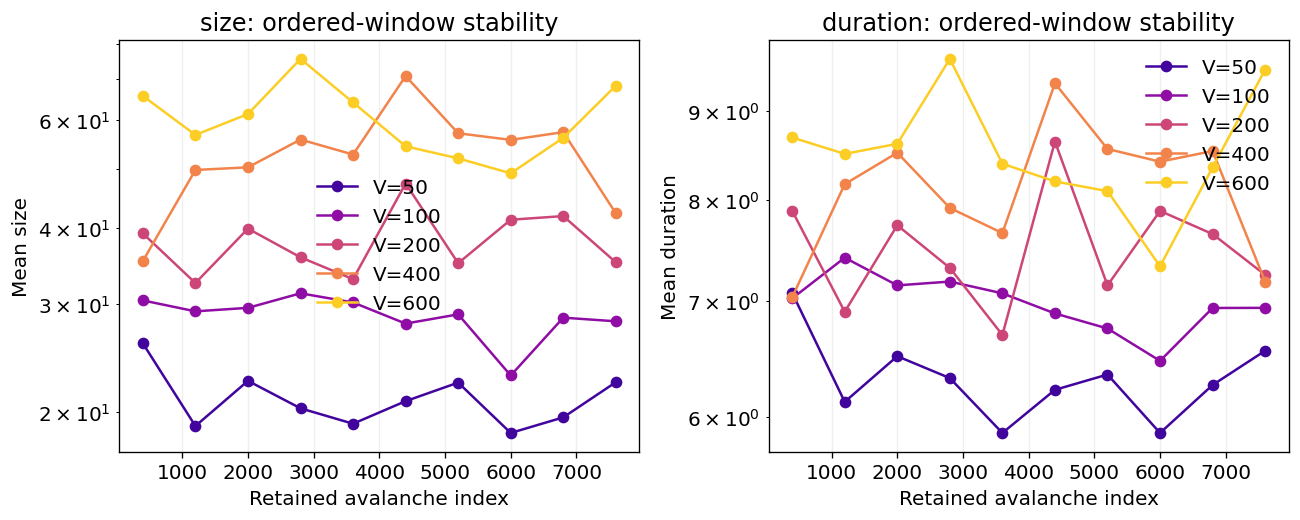

Compare gamma_cutoff = kappa_size/kappa_duration with gamma_exponents = (alpha-1)/(tau-1):
       relation  estimate  bootstrap_std  ci95_low  ci95_high  n_valid  n_boot
   gamma_cutoff  2.028406       0.096435  1.856639   2.236397      500     500
gamma_exponents  2.097399       0.255482  1.735478   2.720612      500     500
Outputs: D:\WORKS\01 independent oscillators\Code\revised code\FSS_noST_tuned\fss_main_no
5 V values and one run per V provide diagnostics, not a definitive FSS verification. Check drift, high-moment sampling, fit-range sensitivity, and independent-network repetitions.


In [47]:
# This module only reads existing simulations; it does not change G or rerun avalanches.
fss_data, fss_sources = load_fss_data(fss_data_dir, fss_sizes, fss_mode, burn_in=fss_burn_in,
                                       filename_template=fss_filename_template)
fss_output_dir.mkdir(parents=True, exist_ok=True)
import json
fss_settings = dict(model='main', sizes=list(map(int, fss_sizes)), mode=fss_mode,
                    data_dir=str(fss_data_dir.resolve()), filename_template=fss_filename_template,
                    burn_in_records=fss_burn_in, nbins=fss_nbins,
                    moment_orders=fss_moment_orders, fit_q_min=fss_fit_q_min,
                    n_boot=fss_n_boot, seed=fss_seed, block_length=fss_bootstrap_block_length,
                    reference_V=fss_reference_V, collapse_min_x=fss_collapse_min_x,
                    collapse_min_tail_count=fss_collapse_min_tail_count,
                    condition_notes=fss_condition_notes,
                    source_files=fss_sources['file'].tolist())
(fss_output_dir/'fss_settings.json').write_text(json.dumps(fss_settings, indent=2), encoding='utf-8')
fss_colors = dict(zip(sorted(fss_data), plt.cm.plasma(np.linspace(.1, .9, len(fss_data)))))
print(f'FSS model=main; discard first {fss_burn_in} stored avalanche records per V.')
print(fss_sources[['V', 'n_raw', 'n_retained', 'size_q99', 'size_max', 'duration_q99', 'duration_max',
                   'size_late_early_mean_ratio', 'duration_late_early_mean_ratio']].to_string(index=False))
fss_sources.to_csv(fss_output_dir/'data_sources.csv', index=False)

fss_hist = fss_histograms(fss_data, fss_nbins)
fss_hist.to_csv(fss_output_dir/'common_bin_pdfs.csv', index=False)
plot_fss_distributions(fss_data, fss_hist, fss_colors, fss_output_dir/'01_distributions.png')

fss_result = fss_moments_bootstrap(
    fss_data, orders=fss_moment_orders, fit_q_min=fss_fit_q_min,
    n_boot=fss_n_boot, seed=fss_seed, block_length=fss_bootstrap_block_length,
)
fss_parameters, fss_moments, fss_moment_slopes, fss_bootstrap = fss_summarize(fss_result)
fss_parameters.to_csv(fss_output_dir/'moment_fss_parameters.csv', index=False)
fss_moments.to_csv(fss_output_dir/'moments.csv', index=False)
fss_moment_slopes.to_csv(fss_output_dir/'moment_scaling_slopes.csv', index=False)
fss_bootstrap.to_csv(fss_output_dir/'paired_bootstrap_parameters.csv', index=False)
print('Moment-derived FSS parameters (conditional bootstrap uncertainty):')
print(fss_parameters.to_string(index=False))
print('Check whether mu(q) is linear, and whether removing the smallest V changes the estimates:')
print(fss_moment_slopes.to_string(index=False))
print('Largest single-event contribution across the selected moment orders:')
print(fss_moments.groupby(['V', 'observable'])[['top1_moment_fraction', 'top10_moment_fraction']].max().to_string())
plot_fss_moments(fss_result, fss_output_dir/'02_moment_scaling.png')
fss_ratios = plot_fss_cutoffs(fss_data, fss_result, fss_output_dir/'03_cutoff_proxies.png')
fss_ratios.to_csv(fss_output_dir/'moment_ratio_cutoff_proxies.csv', index=False)
fss_collapsed = plot_fss_collapse(
    fss_data, fss_hist, fss_result, fss_colors, fss_reference_V,
    fss_collapse_min_x, fss_collapse_min_tail_count, fss_output_dir/'04_scaling_collapse.png',
)
fss_collapsed.to_csv(fss_output_dir/'scaled_ccdfs.csv', index=False)
fss_epochs = plot_fss_time_stability(fss_data, fss_colors, fss_output_dir/'05_time_stability.png')
fss_epochs.to_csv(fss_output_dir/'ordered_epoch_means.csv', index=False)

# Independent scaling relations to compare; bootstrap preserves within-V size-duration pairing.
fss_kappa = fss_result['point']['kappa']
fss_exponents = fss_result['point']['exponent']
fss_consistency_rows = []
for name, estimate in (
    ('gamma_cutoff', fss_kappa[0]/fss_kappa[1] if np.all(fss_kappa > 0) else np.nan),
    ('gamma_exponents', (fss_exponents[1]-1)/(fss_exponents[0]-1)
     if np.all(fss_exponents > 1) and np.all(fss_kappa > 0) else np.nan),
):
    values = fss_bootstrap[name].to_numpy()
    values = values[np.isfinite(values)]
    interval = np.percentile(values, [2.5, 97.5]) if len(values) else [np.nan, np.nan]
    fss_consistency_rows.append(dict(relation=name, estimate=estimate,
                                    bootstrap_std=values.std(ddof=1) if len(values)>1 else np.nan,
                                    ci95_low=interval[0], ci95_high=interval[1],
                                    n_valid=len(values), n_boot=fss_n_boot))
fss_consistency = pd.DataFrame(fss_consistency_rows)
fss_consistency.to_csv(fss_output_dir/'scaling_relation_consistency.csv', index=False)
print('Compare gamma_cutoff = kappa_size/kappa_duration with gamma_exponents = (alpha-1)/(tau-1):')
print(fss_consistency.to_string(index=False))
print('Outputs:', fss_output_dir.resolve())
print(f'{len(fss_data)} V values and one run per V provide diagnostics, not a definitive FSS verification. '
      'Check drift, high-moment sampling, fit-range sensitivity, and independent-network repetitions.')
